# Lab: Parquet, DuckDB, Polars and Arrow with MovieLens 100K (Colab)

Run this notebook in **Google Colab** (see `Setup Google Colab.md` in the Labs folder).
Start with **0. Setup**, which installs the packages and downloads the data.

In seven short steps:

1. Convert CSV files to **Parquet** with DuckDB.
2. Query the Parquet files directly with **DuckDB** SQL.
3. Transform data with **Polars** and query it from DuckDB through **Arrow**.
4. Read Parquet **lazily** with Polars and see which columns are read.
5. Save tables in a **DuckDB database file** and reopen it.
6. **Conhecer o dataset (EDA)**: info, head, describe, nulos, tipos de variáveis e gráficos.
7. Responder a **quatro perguntas** em Python (Polars) e em SQL (DuckDB).

**Data:** MovieLens `ml-latest-small` (100,836 ratings, 9,742 movies).

<a id="inicio"></a>
## Guia de leitura: objetivos, âmbito e índice

O objetivo é estudar armazenamento colunar, consultas analíticas e escalabilidade local com MovieLens. As perguntas são: que géneros existem, como se distribuem as avaliações, que filmes têm melhor classificação, como evoluem os perfis de avaliação e como variam os tempos entre SQL e Python?

**Nota sobre o título original:** este trabalho começou com `ml-latest-small`, que é diferente de MovieLens 100K. O título e os restantes textos anteriores são mantidos; as tabelas de execução identificam sempre o dataset realmente usado. As conclusões escritas anteriormente referem-se à execução que as originou e precisam de ser reavaliadas quando se mudam os dados.

1. [Configuração e plano de trabalho](#configuracao).
2. [Datasets, formatos e preparação](#preparacao).
3. [Qualidade dos dados e EDA](#qualidade).
4. [Perguntas, perfis e atividade invulgar](#perguntas).
5. [Comparação entre datasets e cronologia](#comparacoes).
6. [Benchmarks: método, tempos e gráficos](#desempenho).
7. [Limitações e interpretação humana](#limitacoes).
8. [Conclusões e exportação](#conclusoes).

Execute todas as células por ordem numa sessão reiniciada. Só `ml-latest-small` está ativo por defeito. Os resultados históricos guardados no notebook original não são usados como novas medições. A comparação geral usa os datasets completos preparados; as demonstrações didáticas originais usam apenas um dataset completo com dimensão controlada.

## 0. Setup

<a id="configuracao"></a>
### Configuração única

Altere apenas a célula seguinte para escolher datasets, reutilização e trabalho a executar. Ativar 10M ou 32M exige também `PERMITIR_TAREFAS_GRANDES=True`. O plano apresenta estimativas antes de qualquer download. Desativar benchmarks permite reutilizar medições compatíveis; sem medições guardadas, não serão inventados tempos.

Mudar opções de cálculo exige voltar a executar desde o início. Mudar opções dos gráficos, a legenda ou o zoom é apenas visual. Mudar o número de *threads* exige reiniciar a sessão, porque o Polars inicializa o seu conjunto de trabalhadores na importação.

In [1]:
# Esta é a única célula onde se escolhe o trabalho a realizar.
DATASETS = {
    "ml-latest-small": True,
    "ml-100k": False,
    "ml-1m": False,
    "ml-10m": False,
    "ml-32m": False,
}
EXECUTAR_BENCHMARKS = True
REUTILIZAR_RESULTADOS = True
REUTILIZAR_PREPARACAO = True
PERMITIR_DOWNLOAD = True
PERMITIR_TAREFAS_GRANDES = False  # Necessário para 10M e 32M.
LIMITE_DOWNLOAD_MIB = 250
REPETICOES = 5
AQUECIMENTOS = 2
THREADS = 4
MEMORIA_DUCKDB = "2GB"
EXECUTAR_DETALHE = True
LIMITE_LINHAS_DETALHE = 1_100_000  # As células didáticas originais usam memória.
EXECUTAR_ANALISES_AVANCADAS = True
CRIAR_ZIP = False  # Evita duplicar os ficheiros grandes no fim.
PASTA_TRABALHO = "."  # Pasta do notebook, tanto localmente como no Colab.
# Pode indicar pastas já extraídas; os ficheiros serão apenas lidos.
PASTAS_ORIGINAIS = {"ml-latest-small": "ml-latest-small"}

selecionados = [nome for nome, ativo in DATASETS.items() if ativo]
print("Datasets selecionados:", ", ".join(selecionados) or "nenhum")
print("Benchmarks:", EXECUTAR_BENCHMARKS, "| Reutilizar resultados:", REUTILIZAR_RESULTADOS)
print("Repetições:", REPETICOES, "| Aquecimentos:", AQUECIMENTOS)
print("Análises avançadas:", EXECUTAR_ANALISES_AVANCADAS,
      "| Autorizar 10M/32M:", PERMITIR_TAREFAS_GRANDES)
assert REPETICOES >= 3 and AQUECIMENTOS >= 1 and THREADS >= 1

Datasets selecionados: ml-latest-small
Benchmarks: True | Reutilizar resultados: True
Repetições: 5 | Aquecimentos: 2
Análises avançadas: True | Autorizar 10M/32M: False


In [2]:
# Instala apenas bibliotecas ausentes; os ficheiros de dados são tratados mais abaixo.
import importlib.util, subprocess, sys
pacotes = {"duckdb": "duckdb>=1.4,<3", "polars": "polars>=1.37,<3",
           "pyarrow": "pyarrow>=15", "pandas": "pandas", "matplotlib": "matplotlib",
           "plotly": "plotly>=5"}
em_falta = [requisito for modulo, requisito in pacotes.items()
            if importlib.util.find_spec(modulo) is None]
if em_falta:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *em_falta])
print("Bibliotecas verificadas. As versões efetivas serão registadas no ambiente.")

Bibliotecas verificadas. As versões efetivas serão registadas no ambiente.


In [3]:
from pathlib import Path
import os, sys, json, csv, zipfile, urllib.request, hashlib, time, platform
import shutil, itertools, statistics, random, marshal
from datetime import datetime, timezone
from IPython.display import display, HTML

# Definir antes de importar Polars; mudar THREADS exige reiniciar a sessão.
os.environ["POLARS_MAX_THREADS"] = str(THREADS)
import duckdb
import polars as pl
import pyarrow as pa
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from polars.testing import assert_frame_equal

RAIZ = Path(PASTA_TRABALHO).resolve()
DADOS = RAIZ / "dados"
DOWNLOADS = DADOS / "downloads"
ORIGINAIS = DADOS / "originais"
PREPARADOS = DADOS / "preparados"
OUT_DIR = RAIZ / "output"
CACHE = OUT_DIR / "agregados"
for pasta in (DOWNLOADS, ORIGINAIS, PREPARADOS, OUT_DIR, CACHE):
    pasta.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://files.grouplens.org/datasets/movielens/"
CATALOGO = {
    "ml-latest-small": dict(pasta="ml-latest-small", formato="csv", zip_mib=0.94,
        bruto_mib=3, avaliacoes=100836, escala="0,5–5; passo 0,5", tags=True, links=True,
        readme="ml-latest-small-README.html"),
    "ml-100k": dict(pasta="ml-100k", formato="100k", zip_mib=4.8,
        bruto_mib=16, avaliacoes=100000, escala="1–5; passo 1", tags=False, links=False,
        readme="ml-100k-README.txt"),
    "ml-1m": dict(pasta="ml-1m", formato="dat", zip_mib=5.7,
        bruto_mib=24, avaliacoes=1000209, escala="1–5; passo 1", tags=False, links=False,
        readme="ml-1m-README.txt"),
    "ml-10m": dict(pasta="ml-10M100K", formato="dat", zip_mib=64,
        bruto_mib=310, avaliacoes=10000054, escala="0,5–5; passo 0,5", tags=True, links=False,
        readme="ml-10m-README.html"),
    "ml-32m": dict(pasta="ml-32m", formato="csv", zip_mib=229,
        bruto_mib=1000, avaliacoes=32000204, escala="0,5–5; passo 0,5", tags=True, links=True,
        readme="ml-32m-README.html"),
}

def assinatura(objeto):
    texto = json.dumps(objeto, sort_keys=True, default=str, ensure_ascii=False)
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

def sql_texto(valor):
    return "'" + str(valor).replace("'", "''") + "'"

def sql_ficheiro(caminho):
    return sql_texto(Path(caminho).as_posix())

def metadados_ficheiros(pasta):
    return {p.name: [p.stat().st_size, p.stat().st_mtime_ns]
            for p in sorted(Path(pasta).iterdir()) if p.is_file()}

def ligar():
    con = duckdb.connect()
    con.execute(f"SET threads={THREADS}")
    con.execute(f"SET memory_limit={sql_texto(MEMORIA_DUCKDB)}")
    con.execute("SET TimeZone='UTC'")
    con.execute(f"SET temp_directory={sql_ficheiro(OUT_DIR / 'temporarios_duckdb')}")
    return con

AMBIENTE = {
    "python": sys.version.split()[0], "duckdb": duckdb.__version__,
    "polars": pl.__version__, "arrow": pa.__version__, "plotly": plotly.__version__,
    "pandas": pd.__version__, "matplotlib": matplotlib.__version__, "fuso_das_consultas": "UTC",
    "sistema": platform.platform(), "processador": platform.processor(),
    "cpu_logicos": os.cpu_count(), "threads_pedidas": THREADS,
    "threads_polars": pl.thread_pool_size(), "memoria_duckdb": MEMORIA_DUCKDB,
    "motor_polars": "streaming", "relogio": "perf_counter",
}
if pl.thread_pool_size() != THREADS:
    print("Atenção: reinicie a sessão para aplicar THREADS ao Polars.")
(OUT_DIR / "ambiente.json").write_text(json.dumps(AMBIENTE, indent=2), encoding="utf-8")
display(pl.DataFrame({"propriedade": list(AMBIENTE),
                      "valor": [str(v) for v in AMBIENTE.values()]}))

plano = []
for nome in selecionados:
    info = CATALOGO[nome]
    plano.append({"dataset": nome, "avaliações_documentadas": info["avaliacoes"],
                  "ZIP_aprox_MiB": info["zip_mib"], "originais_estimados_MiB": info["bruto_mib"],
                  "reserva_estimada_MiB": info["bruto_mib"] * 4 + info["zip_mib"],
                  "escala": info["escala"], "benchmark": EXECUTAR_BENCHMARKS,
                  "autorizado": info["avaliacoes"] < 10_000_000 or PERMITIR_TAREFAS_GRANDES})
display(pl.DataFrame(plano) if plano else "Nenhum dataset selecionado: não haverá downloads.")
print("Espaço livre em disco (GiB):", round(shutil.disk_usage(RAIZ).free / 2**30, 1))
print("Estimativas de disco incluem originais e derivados; não são uma garantia de memória.")

Espaço livre em disco (GiB): 136.9
Estimativas de disco incluem originais e derivados; não são uma garantia de memória.


propriedade,valor
str,str
"""python""","""3.12.14"""
"""duckdb""","""2.0.0"""
"""polars""","""2.1.0"""
"""arrow""","""26.0.1"""
"""plotly""","""7.1.0"""
…,…
"""threads_pedidas""","""4"""
"""threads_polars""","""4"""
"""memoria_duckdb""","""2GB"""


dataset,avaliações_documentadas,ZIP_aprox_MiB,originais_estimados_MiB,reserva_estimada_MiB,escala,benchmark,autorizado
str,i64,f64,i64,f64,str,bool,bool
"""ml-latest-small""",100836,0.94,3,12.94,"""0,5–5; passo 0,5""",true,true


<a id="preparacao"></a>
### Fontes oficiais e esquema comum

As estruturas foram verificadas nos documentos oficiais do GroupLens em 4 de novembro de 2026:

| Dataset | Ficheiros usados e formato | Escala | Diferenças relevantes |
|---|---|---|---|
| [`ml-latest-small`](https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html) | `ratings.csv`, `movies.csv`, `tags.csv`, `links.csv`; UTF-8 | 0,5–5; passo 0,5 | Amostra de desenvolvimento; pode mudar; não é MovieLens 100K. |
| [MovieLens 100K](https://files.grouplens.org/datasets/movielens/ml-100k-README.txt) | `u.data` separado por tabulações; `u.item` separado por `|`; `u.genre` | 1–5; inteiros | Filmes com 19 indicadores de género; texto antigo lido como Latin-1. Sem tabelas de etiquetas ou de ligações externas. |
| [MovieLens 1M](https://files.grouplens.org/datasets/movielens/ml-1m-README.txt) | `ratings.dat`, `movies.dat`; separador `::` | 1–5; inteiros | Filmes em Latin-1. Demografia disponível mas fora do esquema comparativo; sem etiquetas ou `links`. |
| [MovieLens 10M](https://files.grouplens.org/datasets/movielens/ml-10m-README.html) | `ratings.dat`, `movies.dat`, `tags.dat`; `::`; UTF-8 | 0,5–5; passo 0,5 | O ZIP usa a pasta `ml-10M100K`; “100K” no nome da pasta refere-se às etiquetas. Sem `links`. |
| [MovieLens 32M](https://files.grouplens.org/datasets/movielens/ml-32m-README.html) | Os quatro CSV; UTF-8 | 0,5–5; passo 0,5 | Amostra maior, com cobertura até 2023 segundo o documento oficial. |

O esquema comum mantém `ratings(userId: Int64, movieId: Int64, rating: Float64, timestamp: Int64)` e `movies(movieId: Int64, title: String, genres: String)`. Os timestamps representam segundos Unix em UTC. As etiquetas e ligações são preparadas apenas quando existem; não se criam dados fictícios. Géneros e títulos mantêm a escrita original, incluindo categorias especiais; categorias com grafias diferentes entre versões não são automaticamente equivalentes.

ZIP e originais são preservados. A adaptação do 100K transforma indicadores em listas de géneros; a do 1M converte o texto dos filmes para UTF-8 num ficheiro derivado. As avaliações grandes são lidas diretamente pelo DuckDB para Parquet comprimido, sem um DataFrame completo em Python. Cada dataset fica numa pasta própria.

As estimativas em MiB partem do [índice oficial](https://files.grouplens.org/datasets/movielens/) e de uma reserva aproximada para ficheiros extraídos e derivados. Os tamanhos efetivos são mostrados depois da preparação. O tempo de rede, de extração e de conversão é registado separadamente. A reutilização compara versão do conversor, nomes, tamanhos e datas de modificação dos ficheiros; não é uma verificação criptográfica de todo o conteúdo. Se editar dados preservando esses metadados, desative a reutilização.

In [4]:
# A preparação substitui o download fixo da versão inicial.
print('Consultar o plano acima antes de executar a preparação seguinte.')

Consultar o plano acima antes de executar a preparação seguinte.


## 1. Convert CSV to Parquet

One DuckDB `COPY` statement reads a CSV file and writes it as Parquet. Parquet stores each column separately, compressed, together with its data type.

In [5]:
VERSAO_PREPARACAO = "2026-11-04.1"

def ficheiros_necessarios(nome):
    info = CATALOGO[nome]
    if info["formato"] == "csv":
        return ["ratings.csv", "movies.csv", "tags.csv", "links.csv"]
    if nome == "ml-100k":
        return ["u.data", "u.item", "u.genre"]
    return ["ratings.dat", "movies.dat"] + (["tags.dat"] if info["tags"] else [])

def localizar_originais(nome):
    candidatos = [Path(PASTAS_ORIGINAIS.get(nome, "__inexistente__")),
                  ORIGINAIS / CATALOGO[nome]["pasta"], RAIZ / CATALOGO[nome]["pasta"]]
    for pasta in candidatos:
        if all((pasta / f).is_file() for f in ficheiros_necessarios(nome)):
            return pasta.resolve()
    return None

def obter_originais(nome):
    pasta = localizar_originais(nome)
    if pasta:
        return pasta, "originais locais reutilizados", 0.0, 0.0
    arquivo = DOWNLOADS / f"{nome}.zip"
    descarga_s = 0.0
    if not arquivo.exists():
        if not PERMITIR_DOWNLOAD:
            raise FileNotFoundError("Sem originais locais e download desativado.")
        if CATALOGO[nome]["zip_mib"] > LIMITE_DOWNLOAD_MIB:
            raise ValueError("O ZIP excede LIMITE_DOWNLOAD_MIB.")
        inicio = time.perf_counter()
        parcial = arquivo.with_suffix(".zip.part")
        urllib.request.urlretrieve(BASE_URL + nome + ".zip", parcial)
        with zipfile.ZipFile(parcial) as z:
            if z.testzip() is not None:
                raise ValueError("O ZIP descarregado está corrompido.")
        parcial.replace(arquivo)
        descarga_s = time.perf_counter() - inicio
    inicio = time.perf_counter()
    with zipfile.ZipFile(arquivo) as z:
        # Extrai apenas caminhos que ficam dentro da pasta de originais.
        destino = ORIGINAIS.resolve()
        for membro in z.infolist():
            (destino / membro.filename).resolve().relative_to(destino)
        z.extractall(destino)
    pasta = localizar_originais(nome)
    if pasta is None:
        raise FileNotFoundError("A estrutura do ZIP não coincide com a documentação.")
    return pasta, "ZIP extraído", descarga_s, time.perf_counter() - inicio

def csv_tipado(caminho, colunas, separador=",", cabecalho=True):
    tipos = ", ".join(f"{sql_texto(c)}: {sql_texto(t)}" for c, t in colunas.items())
    aspas = "\"" if cabecalho else ""
    return (f"read_csv({sql_ficheiro(caminho)}, delim={sql_texto(separador)}, "
            f"header={str(cabecalho).lower()}, auto_detect=false, columns={{{tipos}}}, "
            f"quote={sql_texto(aspas)}, escape={sql_texto(aspas)})")

def converter_filmes_antigos(nome, origem, destino):
    # Só os metadados pequenos passam pelo módulo csv; ratings são lidos pelo DuckDB.
    with destino.open("w", newline="", encoding="utf-8") as saida:
        escritor = csv.writer(saida)
        escritor.writerow(["movieId", "title", "genres"])
        if nome == "ml-100k":
            with (origem / "u.genre").open(encoding="latin-1") as f:
                generos = {int(i): g for linha in f if linha.strip()
                           for g, i in [linha.rstrip("\n").split("|")]}
            with (origem / "u.item").open(encoding="latin-1", newline="") as f:
                for campos in csv.reader(f, delimiter="|"):
                    lista = [generos[i] for i, flag in enumerate(campos[5:]) if flag == "1"]
                    escritor.writerow([campos[0], campos[1], "|".join(lista)])
        else:
            with (origem / "movies.dat").open(encoding="latin-1") as f:
                for linha in f:
                    escritor.writerow(linha.rstrip("\r\n").split("::", 2))

def preparar(nome):
    inicio_total = time.perf_counter()
    origem, estado, descarga_s, extracao_s = obter_originais(nome)
    destino = PREPARADOS / nome
    destino.mkdir(exist_ok=True)
    manifesto = destino / "manifesto.json"
    assinatura_origem = assinatura([VERSAO_PREPARACAO, nome, metadados_ficheiros(origem)])
    if REUTILIZAR_PREPARACAO and manifesto.exists():
        anterior = json.loads(manifesto.read_text(encoding="utf-8"))
        if (anterior["assinatura_origem"] == assinatura_origem
                and all((destino / f"{t}.parquet").exists() for t in anterior["tabelas"])
                and anterior["ficheiros_preparados"] == {
                    p.name: [p.stat().st_size, p.stat().st_mtime_ns]
                    for p in destino.glob("*.parquet")}):
            return anterior, {"dataset": nome, "estado": "Parquet reutilizado",
                "download_s": descarga_s, "extracao_s": extracao_s, "conversao_s": 0.0,
                "total_preparacao_s": time.perf_counter() - inicio_total}
    inicio = time.perf_counter()
    info = CATALOGO[nome]
    rating_cols = {"userId": "BIGINT", "movieId": "BIGINT", "rating": "DOUBLE", "timestamp": "BIGINT"}
    movie_cols = {"movieId": "BIGINT", "title": "VARCHAR", "genres": "VARCHAR"}
    tags_cols = {"userId": "BIGINT", "movieId": "BIGINT", "tag": "VARCHAR", "timestamp": "BIGINT"}
    links_cols = {"movieId": "BIGINT", "imdbId": "BIGINT", "tmdbId": "BIGINT"}
    if info["formato"] == "csv":
        fontes = {t: csv_tipado(origem / f"{t}.csv", c) for t, c in
                  [("ratings", rating_cols), ("movies", movie_cols),
                   ("tags", tags_cols), ("links", links_cols)]}
    else:
        if nome in ("ml-100k", "ml-1m"):
            utf8 = destino / "movies_utf8.csv"
            converter_filmes_antigos(nome, origem, utf8)
            filmes = csv_tipado(utf8, movie_cols)
        else:
            filmes = csv_tipado(origem / "movies.dat", movie_cols, "::", False)
        ratings_nome = "u.data" if nome == "ml-100k" else "ratings.dat"
        fontes = {"ratings": csv_tipado(origem / ratings_nome, rating_cols,
                    "\t" if nome == "ml-100k" else "::", False), "movies": filmes}
        if info["tags"]:
            fontes["tags"] = csv_tipado(origem / "tags.dat", tags_cols, "::", False)
    with ligar() as con:
        for tabela, fonte in fontes.items():
            con.execute(f"COPY (SELECT * FROM {fonte}) TO "
                        f"{sql_ficheiro(destino / (tabela + '.parquet'))} "
                        "(FORMAT PARQUET, COMPRESSION ZSTD)")
        n = con.execute(f"SELECT COUNT(*) FROM {sql_ficheiro(destino / 'ratings.parquet')}").fetchone()[0]
    derivados = {p.name: [p.stat().st_size, p.stat().st_mtime_ns] for p in destino.glob("*.parquet")}
    dados = {"dataset": nome, "origem": str(origem), "pasta": str(destino),
             "tabelas": list(fontes), "linhas_ratings": n,
             "assinatura_origem": assinatura_origem, "ficheiros_preparados": derivados,
             "assinatura_dados": assinatura([assinatura_origem, derivados]),
             "versao_preparacao": VERSAO_PREPARACAO}
    manifesto.write_text(json.dumps(dados, indent=2), encoding="utf-8")
    return dados, {"dataset": nome, "estado": estado + "; convertido",
                  "download_s": descarga_s, "extracao_s": extracao_s,
                  "conversao_s": time.perf_counter() - inicio,
                  "total_preparacao_s": time.perf_counter() - inicio_total}

datasets_preparados, preparacao, omitidos = {}, [], []
for nome in selecionados:
    info = CATALOGO[nome]
    if info["avaliacoes"] >= 10_000_000 and not PERMITIR_TAREFAS_GRANDES:
        omitidos.append({"dataset": nome, "motivo": "Ativar PERMITIR_TAREFAS_GRANDES para 10M/32M."})
        continue
    if shutil.disk_usage(RAIZ).free < info["bruto_mib"] * 4 * 2**20:
        omitidos.append({"dataset": nome, "motivo": "Espaço livre inferior à reserva estimada."})
        continue
    try:
        dados, tempos = preparar(nome)
        datasets_preparados[nome] = dados
        preparacao.append(tempos)
    except (OSError, ValueError, zipfile.BadZipFile, duckdb.Error) as erro:
        omitidos.append({"dataset": nome, "motivo": str(erro)})

display(pl.DataFrame(preparacao) if preparacao else "Sem preparação executada.")
display(pl.DataFrame(omitidos) if omitidos else "Sem datasets omitidos.")
if preparacao:
    pl.DataFrame(preparacao).write_csv(OUT_DIR / "preparacao_ultima_execucao.csv")
# A demonstração original corre sobre um único dataset completo com dimensão controlada.
candidatos = [n for n, d in datasets_preparados.items()
              if d["linhas_ratings"] <= LIMITE_LINHAS_DETALHE]
DATASET_DETALHE = candidatos[0] if candidatos else None
DETALHE_ATIVO = EXECUTAR_DETALHE and DATASET_DETALHE is not None
if DETALHE_ATIVO:
    PQ_DIR = Path(datasets_preparados[DATASET_DETALHE]["pasta"])
    CSV_DIR = Path(datasets_preparados[DATASET_DETALHE]["origem"])
    RATINGS = (PQ_DIR / "ratings.parquet").as_posix()
    MOVIES = (PQ_DIR / "movies.parquet").as_posix()
    TAGS = (PQ_DIR / "tags.parquet").as_posix()
    LINKS = (PQ_DIR / "links.parquet").as_posix()
print("Dataset da demonstração detalhada:", DATASET_DETALHE if DETALHE_ATIVO else "desativada")

Dataset da demonstração detalhada: ml-latest-small


dataset,estado,download_s,extracao_s,conversao_s,total_preparacao_s
str,str,f64,f64,f64,f64
"""ml-latest-small""","""Parquet reutilizado""",0.0,0.0,0.0,0.004749


'Sem datasets omitidos.'

In [6]:
for nome, dados in datasets_preparados.items():
    print("\nDataset:", nome, "| avaliações:", dados["linhas_ratings"])
    for tabela in dados["tabelas"]:
        ficheiro = Path(dados["pasta"]) / f"{tabela}.parquet"
        print(f"{tabela:10} Parquet: {ficheiro.stat().st_size/2**20:.2f} MiB")


Dataset: ml-latest-small | avaliações: 100836
ratings    Parquet: 0.48 MiB
movies     Parquet: 0.15 MiB
tags       Parquet: 0.03 MiB
links      Parquet: 0.07 MiB


### Demonstrações locais e gestão de memória

As secções didáticas seguintes continuam a mostrar CSV/Parquet, Arrow, consultas *lazy* e persistência DuckDB. Usam o primeiro dataset selecionado com até `LIMITE_LINHAS_DETALHE` avaliações. O nome é apresentado na preparação. Se nenhum cumprir esse limite, estas células são omitidas e as comparações completas por agregação continuam disponíveis. Não se usa uma amostra silenciosa.

O limite evita carregar 10M/32M integralmente na EDA original. As análises comparativas posteriores leem Parquet com DuckDB ou Polars *lazy*, dataset a dataset. Alguns agrupamentos, medianas e ordenações precisam de memória; o modo *streaming* não garante memória constante em todas as operações. DuckDB tem um limite de memória e uma pasta temporária de apoio em disco.

## 2. Query the Parquet files directly with DuckDB

DuckDB reads the files where they are: there is nothing to import and no server to start.
`.pl()` returns the result as a Polars DataFrame.

In [7]:
if DETALHE_ATIVO:
    top10 = duckdb.sql(f"""SELECT m.movieId, m.title, AVG(r.rating) AS avg_exact,
        AVG(r.rating) AS avg_rating, COUNT(*) AS num_ratings
        FROM '{RATINGS}' r JOIN '{MOVIES}' m USING(movieId)
        GROUP BY m.movieId, m.title HAVING COUNT(*)>=100
        ORDER BY avg_exact DESC, m.movieId LIMIT 10""").pl()
    display(top10.select('title', 'avg_rating', 'num_ratings'))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


title,avg_rating,num_ratings
str,f64,i64
"""Shawshank Redemption, The (199…",4.429022,317
"""Godfather, The (1972)""",4.2890625,192
"""Fight Club (1999)""",4.272936,218
"""Godfather: Part II, The (1974)""",4.25969,129
"""Departed, The (2006)""",4.252336,107
"""Goodfellas (1990)""",4.25,126
"""Casablanca (1942)""",4.24,100
"""Dark Knight, The (2008)""",4.238255,149
"""Usual Suspects, The (1995)""",4.237745,204


## 3. Transform with Polars, query with DuckDB (through Arrow)

Polars splits the `genres` column (`Adventure|Animation|...`) into one row per genre. The result, `movie_genres`, exists only in memory, not in a file. DuckDB queries it by its variable name: both tools use the Arrow columnar format, so the data is not copied or converted.

**Nota sobre Arrow:** o formato comum facilita a partilha de dados colunares, mas a ausência de cópias depende dos tipos, das operações e das versões das bibliotecas. A demonstração regista explicitamente a tabela Arrow; não mede nem garante que todo o percurso seja sem cópias.

In [8]:
if DETALHE_ATIVO:
    movie_genres = (pl.read_parquet(MOVIES)
        .select('movieId', pl.col('genres').str.split('|').alias('genre')).explode('genre'))
    with duckdb.connect() as con:
        con.register('movie_genres_arrow', movie_genres.to_arrow())
        genre_counts = con.sql(f"""SELECT g.genre, COUNT(*) AS num_ratings,
            ROUND(AVG(r.rating),2) AS avg_rating FROM movie_genres_arrow g
            JOIN '{RATINGS}' r USING(movieId) GROUP BY g.genre ORDER BY num_ratings DESC, g.genre""").pl()
    display(genre_counts)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


genre,num_ratings,avg_rating
str,i64,f64
"""Drama""",41928,3.66
"""Comedy""",39053,3.38
"""Action""",30635,3.45
"""Thriller""",26452,3.49
"""Adventure""",24161,3.51
…,…,…
"""Musical""",4138,3.56
"""Western""",1930,3.58
"""Documentary""",1219,3.8


## 4. Read Parquet lazily with Polars

`pl.read_parquet` reads the whole file at once (**eager**). `pl.scan_parquet` reads nothing yet: it builds a plan (**lazy**), and `.collect()` runs it.

`.explain()` shows what the plan will read.

In [9]:
if DETALHE_ATIVO:
    lazy_query = (
        pl.scan_parquet(RATINGS)
          .filter(pl.col('rating') >= 4.5)
          .select('movieId', 'rating')
    )
    print(lazy_query.explain())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Parquet SCAN [C:/Workstation/EDSA/Big Data Foundations/Projecto/BDF/dados/preparados/ml-latest-small/ratings.parquet]
PROJECT 2/4 COLUMNS
SELECTION: col("rating") >= 4.5
ESTIMATED ROWS: 100836


In the plan, `PROJECT 2/4 COLUMNS` means only 2 of the 4 columns are read from the file, and
`SELECTION` means the filter is applied while reading. Parquet makes this possible because it stores
each column separately.

In [10]:
if DETALHE_ATIVO:
    high_ratings = lazy_query.collect()   # the file is read now
    display(high_ratings.shape)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


(21762, 2)

## 5. Save tables in a DuckDB database file

A file name instead of memory keeps the tables after Python closes. `with` closes the connection at
the end of the block: an open `.duckdb` file is locked, and no other program can open it.

**Nota sobre persistência:** o bloco `with` fecha a ligação e liberta os recursos. A abertura simultânea de um ficheiro DuckDB depende do modo de acesso e dos processos envolvidos; vários leitores em modo apenas de leitura são um caso distinto de um processo que escreve. Nesta demonstração as ligações são abertas uma de cada vez.

In [11]:
if DETALHE_ATIVO:
    DB = (OUT_DIR / f'movielens_{DATASET_DETALHE}.duckdb').as_posix()
    with duckdb.connect(DB) as db:
        db.execute(f"CREATE OR REPLACE TABLE ratings AS SELECT * FROM '{RATINGS}'")
        db.execute(f"CREATE OR REPLACE TABLE movies AS SELECT * FROM '{MOVIES}'")
        db.register('generos_arrow', genre_counts.to_arrow())
        db.execute("CREATE OR REPLACE TABLE genre_counts AS SELECT * FROM generos_arrow")
    with duckdb.connect(DB, read_only=True) as db:
        print(db.sql('SHOW TABLES'))
        print(db.sql('SELECT COUNT(*) AS ratings FROM ratings'))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


┌──────────────┐
│     name     │
│   varchar    │
├──────────────┤
│ genre_counts │
│ movies       │
│ ratings      │
└──────────────┘

┌─────────┐
│ ratings │
│  int64  │
├─────────┤
│  100836 │
└─────────┘



<a id="qualidade"></a>
### Qualidade: âmbito das verificações

As verificações separam nulos, domínio dos valores, chaves, relações entre tabelas e variantes de escrita. Uma tabela vazia de variantes só indica que a normalização usada não encontrou essas variantes; não demonstra que os dados foram previamente limpos nem que não existem outros erros. Os textos originais com percentagens concretas descrevem a execução anterior e não substituem os resultados atuais.

## 6. Conhecer o dataset (EDA)

Antes de responder a perguntas, convém conhecer as tabelas: dimensão, tipos de dados, primeiras linhas,
estatísticas descritivas, valores em falta, tipo de cada variável e a forma das distribuições.
Sempre que possível, cada passo é feito em **Python (Polars)** e em **SQL (DuckDB)**.

In [12]:
if DETALHE_ATIVO:
    ratings = pl.read_parquet(RATINGS)
    movies = pl.read_parquet(MOVIES)
    tables = {'ratings': ratings, 'movies': movies}
    paths = {'ratings': RATINGS, 'movies': MOVIES}
    for tabela in ('tags', 'links'):
        ficheiro = PQ_DIR / f'{tabela}.parquet'
        if tabela in datasets_preparados[DATASET_DETALHE]['tabelas']:
            tables[tabela] = pl.read_parquet(ficheiro)
            paths[tabela] = ficheiro.as_posix()
        else:
            print(f'{DATASET_DETALHE}: tabela {tabela} indisponível; só esta combinação é omitida.')
    if 'tags' in tables: tags = tables['tags']
    if 'links' in tables: links = tables['links']
    for name, df in tables.items():
        print(f'{name:8} {df.height:>10,} linhas × {df.width} colunas | {df.estimated_size("mb"):.2f} MiB em memória')
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


ratings     100,836 linhas × 4 colunas | 3.08 MiB em memória
movies        9,742 linhas × 3 colunas | 0.46 MiB em memória
tags          3,683 linhas × 4 colunas | 0.12 MiB em memória
links         9,742 linhas × 3 colunas | 0.22 MiB em memória


### 6.1 Estrutura e tipos de dados (`info`)

Em Polars, `glimpse()` mostra cada coluna com o tipo e os primeiros valores. Para quem vem do pandas,
`.to_pandas().info()` dá o resumo clássico. Em SQL, `DESCRIBE` devolve o esquema lido do Parquet.

In [13]:
if DETALHE_ATIVO:
    # Python: Polars glimpse + pandas info
    for name, df in tables.items():
        print(f'\n===== {name} =====')
        df.glimpse()

    print('\n===== ratings (pandas .info) =====')
    ratings.to_pandas().info(memory_usage='deep')
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')



===== ratings =====
Rows: 100836
Columns: 4
$ userId    <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ movieId   <i64> 1, 3, 6, 47, 50, 70, 101, 110, 151, 157
$ rating    <f64> 4.0, 4.0, 4.0, 5.0, 5.0, 3.0, 5.0, 4.0, 5.0, 5.0
$ timestamp <i64> 964982703, 964981247, 964982224, 964983815, 964982931, 964982400, 964980868, 964982176, 964984041, 964984100


===== movies =====
Rows: 9742
Columns: 3
$ movieId <i64> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10
$ title   <str> 'Toy Story (1995)', 'Jumanji (1995)', 'Grumpier Old Men (1995)', 'Waiting to Exhale (1995)', 'Father of the Bride Part II (1995)', 'Heat (1995)', 'Sabrina (1995)', 'Tom and Huck (1995)', 'Sudden Death (1995)', 'GoldenEye (1995)'
$ genres  <str> 'Adventure|Animation|Children|Comedy|Fantasy', 'Adventure|Children|Fantasy', 'Comedy|Romance', 'Comedy|Drama|Romance', 'Comedy', 'Action|Crime|Thriller', 'Comedy|Romance', 'Adventure|Children', 'Action', 'Action|Adventure|Thriller'


===== tags =====
Rows: 3683
Columns: 4
$ userId    <i64> 2, 2, 2, 2, 2, 

In [14]:
if DETALHE_ATIVO:
    # SQL: DESCRIBE lê o esquema diretamente do ficheiro Parquet
    for name, path in paths.items():
        print(f'===== {name} =====')
        print(duckdb.sql(f"DESCRIBE SELECT * FROM '{path}'"))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ userId      │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ movieId     │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ rating      │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ timestamp   │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

===== movies =====
┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ movieId     │ BIGINT      │ YES     │ NULL    │ 

### 6.2 Primeiras linhas (`head`)

In [15]:
if DETALHE_ATIVO:
    # Python
    for name, df in tables.items():
        print(f'===== {name} =====')
        display(df.head(5))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
===== movies =====
===== tags =====
===== links =====


userId,movieId,rating,timestamp
i64,i64,f64,i64
1,1,4.0,964982703
1,3,4.0,964981247
1,6,4.0,964982224
1,47,5.0,964983815
1,50,5.0,964982931


movieId,title,genres
i64,str,str
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…"
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy"""
3,"""Grumpier Old Men (1995)""","""Comedy|Romance"""
4,"""Waiting to Exhale (1995)""","""Comedy|Drama|Romance"""
5,"""Father of the Bride Part II (1…","""Comedy"""


userId,movieId,tag,timestamp
i64,i64,str,i64
2,60756,"""funny""",1445714994
2,60756,"""Highly quotable""",1445714996
2,60756,"""will ferrell""",1445714992
2,89774,"""Boxing story""",1445715207
2,89774,"""MMA""",1445715200


movieId,imdbId,tmdbId
i64,i64,i64
1,114709,862
2,113497,8844
3,113228,15602
4,114885,31357
5,113041,11862


In [16]:
if DETALHE_ATIVO:
    # SQL
    for name, path in paths.items():
        print(f'===== {name} =====')
        print(duckdb.sql(f"SELECT * FROM '{path}' LIMIT 5"))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
┌────────┬─────────┬────────┬───────────┐
│ userId │ movieId │ rating │ timestamp │
│ int64  │  int64  │ double │   int64   │
├────────┼─────────┼────────┼───────────┤
│      1 │       1 │    4.0 │ 964982703 │
│      1 │       3 │    4.0 │ 964981247 │
│      1 │       6 │    4.0 │ 964982224 │
│      1 │      47 │    5.0 │ 964983815 │
│      1 │      50 │    5.0 │ 964982931 │
└────────┴─────────┴────────┴───────────┘

===== movies =====
┌─────────┬────────────────────────────────────┬─────────────────────────────────────────────┐
│ movieId │               title                │                   genres                    │
│  int64  │              varchar               │                   varchar                   │
├─────────┼────────────────────────────────────┼─────────────────────────────────────────────┤
│       1 │ Toy Story (1995)                   │ Adventure|Animation|Children|Comedy|Fantasy │
│       2 │ Jumanji (1995)                     │ Adventure|Childr

### 6.3 Estatísticas descritivas (`describe`)

`describe()` em Polars e `SUMMARIZE` em DuckDB: contagem, nulos, média, desvio-padrão, mínimo, quartis e
máximo. `SUMMARIZE` acrescenta ainda o número aproximado de valores distintos (`approx_unique`), muito
útil para perceber se uma coluna é categórica.

Atenção: estatísticas como a média de `userId` ou `movieId` não têm significado, porque são identificadores.

In [17]:
if DETALHE_ATIVO:
    # Python
    for name, df in tables.items():
        print(f'===== {name} =====')
        display(df.describe())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
===== movies =====
===== tags =====
===== links =====


statistic,userId,movieId,rating,timestamp
str,f64,f64,f64,f64
"""count""",100836.0,100836.0,100836.0,100836.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",326.127564,19435.295718,3.501557,1.2059e9
"""std""",182.618491,35530.987199,1.042529,2.1626e8
"""min""",1.0,1.0,0.5,8.28124615e8
"""25%""",177.0,1199.0,3.0,1.0191e9
"""50%""",325.0,2991.0,3.5,1.1861e9
"""75%""",477.0,8121.0,4.0,1.4360e9
"""max""",610.0,193609.0,5.0,1.5378e9


statistic,movieId,title,genres
str,f64,str,str
"""count""",9742.0,"""9742""","""9742"""
"""null_count""",0.0,"""0""","""0"""
"""mean""",42200.353623,null,null
"""std""",52160.494854,null,null
"""min""",1.0,"""'71 (2014)""","""(no genres listed)"""
"""25%""",3248.0,null,null
"""50%""",7301.0,null,null
"""75%""",76251.0,null,null
"""max""",193609.0,"""À nous la liberté (Freedom for…","""Western"""


statistic,userId,movieId,tag,timestamp
str,f64,f64,str,f64
"""count""",3683.0,3683.0,"""3683""",3683.0
"""null_count""",0.0,0.0,"""0""",0.0
"""mean""",431.149335,27252.013576,null,1.3200e9
"""std""",158.472553,43490.558803,null,1.7210e8
"""min""",2.0,1.0,"""""artsy""""",1.1372e9
"""25%""",424.0,1263.0,null,1.1375e9
"""50%""",474.0,4454.0,null,1.2698e9
"""75%""",477.0,39292.0,null,1.4985e9
"""max""",610.0,193565.0,"""zombies""",1.5371e9


statistic,movieId,imdbId,tmdbId
str,f64,f64,f64
"""count""",9742.0,9742.0,9734.0
"""null_count""",0.0,0.0,8.0
"""mean""",42200.353623,677183.898173,55162.123793
"""std""",52160.494854,1.1072e6,93653.481487
"""min""",1.0,417.0,2.0
"""25%""",3248.0,95179.0,9665.0
"""50%""",7301.0,167261.0,16535.0
"""75%""",76251.0,805570.0,44214.0
"""max""",193609.0,8.391976e6,525662.0


In [18]:
if DETALHE_ATIVO:
    # SQL
    for name, path in paths.items():
        print(f'===== {name} =====')
        display(duckdb.sql(f"SUMMARIZE SELECT * FROM '{path}'").pl())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
===== movies =====
===== tags =====
===== links =====


column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,"decimal[9,2]"
"""userId""","""BIGINT""","""1""","""610""",609,"""326.12756356856676""","""182.6184914635004""","""176""","""325""","""477""",100836,0.00
"""movieId""","""BIGINT""","""1""","""193609""",9341,"""19435.2957177992""","""35530.9871987003""","""1195""","""2996""","""8043""",100836,0.00
"""rating""","""DOUBLE""","""0.5""","""5.0""",10,"""3.501556983616962""","""1.0425292390606342""","""3.0""","""3.5""","""4.0""",100836,0.00
"""timestamp""","""BIGINT""","""828124615""","""1537799250""",88061,"""1205946087.3684695""","""216261035.99513078""","""1016245984""","""1184543600""","""1436471542""",100836,0.00


column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,"decimal[9,2]"
"""movieId""","""BIGINT""","""1""","""193609""",9341,"""42200.353623485935""","""52160.49485443824""","""3240""","""7290""","""76526""",9742,0.00
"""title""","""VARCHAR""","""'71 (2014)""","""À nous la liberté (Freedom for…",9757,null,null,null,null,null,9742,0.00
"""genres""","""VARCHAR""","""(no genres listed)""","""Western""",971,null,null,null,null,null,9742,0.00


column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,"decimal[9,2]"
"""userId""","""BIGINT""","""2""","""610""",60,"""431.1493347814282""","""158.47255348483532""","""424""","""474""","""492""",3683,0.00
"""movieId""","""BIGINT""","""1""","""193565""",1580,"""27252.01357588922""","""43490.55880276775""","""1270""","""4469""","""39695""",3683,0.00
"""tag""","""VARCHAR""","""""artsy""""","""zombies""",1571,null,null,null,null,null,3683,0.00
"""timestamp""","""BIGINT""","""1137179352""","""1537098603""",3383,"""1320031966.823785""","""172102450.43712625""","""1137571682""","""1272474605""","""1498456755""",3683,0.00


column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,"decimal[9,2]"
"""movieId""","""BIGINT""","""1""","""193609""",9341,"""42200.353623485935""","""52160.49485443824""","""3240""","""7290""","""76526""",9742,0.00
"""imdbId""","""BIGINT""","""417""","""8391976""",9990,"""677183.8981728598""","""1107227.5767597635""","""95150""","""168622""","""802780""",9742,0.00
"""tmdbId""","""BIGINT""","""2""","""525662""",9286,"""55162.123792890896""","""93653.48148734072""","""9671""","""16630""","""44416""",9742,0.08


### 6.4 Nomes e categorias potencialmente "duplicados"

Vamos verificar se géneros ou títulos distintos diferem apenas em maiúsculas/minúsculas ou espaços. Para isso, normalizamos temporariamente os nomes (sem alterar os dados originais) e procuramos formas diferentes que ficam iguais após a normalização.

Isto deteta diferenças de escrita simples; não identifica nomes apenas semelhantes, que podem referir-se a filmes diferentes. - Uma mesa vazia mostra-nos que o dataset já foi tratado ou simplesmente bem composto antes desta análise.

[REVER DEPOIS DE CORRER O DATASET 32M]

In [19]:
if DETALHE_ATIVO:
    # Separa os géneros: cada linha passa a conter um único género.
    genre_values = (
        movies
        .select(pl.col("genres").str.split("|").alias("genre"))
        .explode("genre")
        .with_columns(pl.col("genre").str.strip_chars())
        .filter(
            pl.col("genre").is_not_null()
            & (pl.col("genre") != "")
        )
    )

    def spelling_variants(df: pl.DataFrame, column: str) -> pl.DataFrame:
        """Mostra escritas diferentes que coincidem após normalizar caixa e espaços."""
        return (
            df.with_columns(
                pl.col(column)
                .str.strip_chars()
                .str.to_lowercase()
                .str.replace_all(r"\s+", " ")
                .alias("nome_normalizado")
            )
            .group_by("nome_normalizado")
            .agg(pl.col(column).unique().sort().alias("formas_encontradas"))
            .filter(pl.col("formas_encontradas").list.len() > 1)
            .sort("nome_normalizado")
        )

    genre_variants = spelling_variants(genre_values, "genre")
    title_variants = spelling_variants(movies, "title")

    print("Variações de escrita nos géneros:")
    display(genre_variants)

    print("Variações de escrita nos títulos:")
    display(title_variants)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Variações de escrita nos géneros:
Variações de escrita nos títulos:


nome_normalizado,formas_encontradas
str,list[str]


nome_normalizado,formas_encontradas
str,list[str]


### 6.5 Valores em falta, duplicados e cardinalidade

Os comandos de bloco acima indicam practicamente isenção de valores não nulos. Apenas um set 'tmdb' apresenta um baixa percentagem (0,08%) de valores nulos. Isto para um dataset 100K, mas num dataset mais compreensivo isso poderia não ser o caso.

Igualmente importante é a cardinalidade e duplicidade dos dados e para isso estabelecemos aqui uma tabela sumário para esse efeito.

In [20]:
if DETALHE_ATIVO:
    # Python: nulos e número de valores distintos por coluna
    for name, df in tables.items():
        print(f'===== {name} =====')
        display(pl.concat([
            df.null_count().with_columns(pl.lit('nulos').alias('métrica')),
            df.select(pl.all().n_unique()).with_columns(pl.lit('distintos').alias('métrica')),
        ], how='vertical_relaxed').select('métrica', *df.columns))

    # Duplicados: cada utilizador deve avaliar cada filme no máximo uma vez
    dup = ratings.height - ratings.select(pl.struct('userId', 'movieId').n_unique()).item()
    print('Pares (userId, movieId) duplicados em ratings:', dup)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
===== movies =====
===== tags =====
===== links =====
Pares (userId, movieId) duplicados em ratings: 0


métrica,userId,movieId,rating,timestamp
str,u32,u32,u32,u32
"""nulos""",0,0,0,0
"""distintos""",610,9724,10,85043


métrica,movieId,title,genres
str,u32,u32,u32
"""nulos""",0,0,0
"""distintos""",9742,9737,951


métrica,userId,movieId,tag,timestamp
str,u32,u32,u32,u32
"""nulos""",0,0,0,0
"""distintos""",58,1572,1589,3411


métrica,movieId,imdbId,tmdbId
str,u32,u32,u32
"""nulos""",0,0,8
"""distintos""",9742,9742,9734


In [21]:
if DETALHE_ATIVO:
    print(duckdb.sql(f"""SELECT COUNT(*) AS linhas, COUNT(DISTINCT userId) AS utilizadores,
        COUNT(DISTINCT movieId) AS filmes_avaliados, COUNT(*)-COUNT(rating) AS ratings_nulos,
        COUNT(*)-COUNT(DISTINCT (userId,movieId)) AS pares_duplicados FROM '{RATINGS}'"""))
    if 'links' in paths:
        print(duckdb.sql(f"SELECT COUNT(*) AS filmes, COUNT(*) FILTER (WHERE tmdbId IS NULL) AS sem_tmdbId FROM '{LINKS}'"))
    else:
        print('Ligações externas indisponíveis neste dataset; análise de tmdbId omitida.')
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


┌────────┬──────────────┬──────────────────┬───────────────┬──────────────────┐
│ linhas │ utilizadores │ filmes_avaliados │ ratings_nulos │ pares_duplicados │
│ int64  │    int64     │      int64       │     int64     │      int64       │
├────────┼──────────────┼──────────────────┼───────────────┼──────────────────┤
│ 100836 │          610 │             9724 │             0 │                0 │
└────────┴──────────────┴──────────────────┴───────────────┴──────────────────┘

┌────────┬────────────┐
│ filmes │ sem_tmdbId │
│ int64  │   int64    │
├────────┼────────────┤
│   9742 │          8 │
└────────┴────────────┘



### 6.6 Variáveis categóricas e numéricas

O tipo de dados guardado não chega para classificar uma variável: `userId` e `movieId` são inteiros mas
são **identificadores** (categóricos), e `timestamp` é um inteiro que representa uma **data**
(segundos desde 1970-01-01). A função abaixo combina o tipo de dados com estas regras.

In [22]:
if DETALHE_ATIVO:
    def classify_columns(df: pl.DataFrame) -> pl.DataFrame:
        rows = []
        for col, dtype in df.schema.items():
            if col.endswith('Id'):
                kind = 'identificador (categórica)'
            elif col == 'timestamp':
                kind = 'temporal (Unix epoch)'
            elif dtype.is_numeric():
                kind = 'numérica'
            else:
                kind = 'categórica / texto'
            rows.append({'coluna': col, 'dtype': str(dtype), 'tipo': kind,
                         'distintos': df[col].n_unique()})
        return pl.DataFrame(rows)

    for name, df in tables.items():
        print(f'===== {name} =====')
        display(classify_columns(df))

    numeric_vars = {n: [c for c, t in df.schema.items() if t.is_numeric() and not c.endswith('Id') and c != 'timestamp']
                    for n, df in tables.items()}
    categorical_vars = {n: [c for c, t in df.schema.items() if t == pl.String] for n, df in tables.items()}
    print('Numéricas:  ', numeric_vars)
    print('Categóricas:', categorical_vars)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


===== ratings =====
===== movies =====
===== tags =====
===== links =====
Numéricas:   {'ratings': ['rating'], 'movies': [], 'tags': [], 'links': []}
Categóricas: {'ratings': [], 'movies': ['title', 'genres'], 'tags': ['tag'], 'links': []}


coluna,dtype,tipo,distintos
str,str,str,i64
"""userId""","""Int64""","""identificador (categórica)""",610
"""movieId""","""Int64""","""identificador (categórica)""",9724
"""rating""","""Float64""","""numérica""",10
"""timestamp""","""Int64""","""temporal (Unix epoch)""",85043


coluna,dtype,tipo,distintos
str,str,str,i64
"""movieId""","""Int64""","""identificador (categórica)""",9742
"""title""","""String""","""categórica / texto""",9737
"""genres""","""String""","""categórica / texto""",951


coluna,dtype,tipo,distintos
str,str,str,i64
"""userId""","""Int64""","""identificador (categórica)""",58
"""movieId""","""Int64""","""identificador (categórica)""",1572
"""tag""","""String""","""categórica / texto""",1589
"""timestamp""","""Int64""","""temporal (Unix epoch)""",3411


coluna,dtype,tipo,distintos
str,str,str,i64
"""movieId""","""Int64""","""identificador (categórica)""",9742
"""imdbId""","""Int64""","""identificador (categórica)""",9742
"""tmdbId""","""Int64""","""identificador (categórica)""",9734


**Nota sobre as escalas:** os passos de 0,5 descritos no texto original aplicam-se a `ml-latest-small`, 10M e 32M. MovieLens 100K e 1M só têm valores inteiros. Um perfil “Só inteiros” nestes últimos resulta da escala disponível e não é, por si, uma preferência do utilizador.

Notas sobre as variáveis:

- `rating` é **numérica discreta e ordinal**: só toma valores de 0.5 a 5.0, em passos de 0.5.
- `genres` é **categórica multivalor**: um filme pode ter vários géneros separados por `|`.
- `title` é texto, mas contém o **ano de estreia** entre parênteses, que podemos extrair.
- `tag` é texto livre escrito pelos utilizadores (alta cardinalidade).

Criamos algumas variáveis derivadas para os gráficos: ano de estreia, número de géneros e data da avaliação.

In [23]:
if DETALHE_ATIVO:
    # Python
    movies_ext = movies.with_columns(
        pl.col('title').str.extract(r'\((\d{4})\)\s*$', 1).cast(pl.Int32, strict=False).alias('year'),
        pl.col('genres').str.split('|').list.len().alias('num_genres'),
    )
    ratings_ext = ratings.with_columns(pl.from_epoch('timestamp', time_unit='s').alias('rated_at'))

    display(movies_ext.head())
    display(ratings_ext.head())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


movieId,title,genres,year,num_genres
i64,str,str,i32,u32
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…",1995,5
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy""",1995,3
3,"""Grumpier Old Men (1995)""","""Comedy|Romance""",1995,2
4,"""Waiting to Exhale (1995)""","""Comedy|Drama|Romance""",1995,3
5,"""Father of the Bride Part II (1…","""Comedy""",1995,1


userId,movieId,rating,timestamp,rated_at
i64,i64,f64,i64,datetime[μs]
1,1,4.0,964982703,2000-07-30 18:45:03
1,3,4.0,964981247,2000-07-30 18:20:47
1,6,4.0,964982224,2000-07-30 18:37:04
1,47,5.0,964983815,2000-07-30 19:03:35
1,50,5.0,964982931,2000-07-30 18:48:51


In [24]:
if DETALHE_ATIVO:
    # SQL: as mesmas variáveis derivadas
    print(duckdb.sql(rf'''
        SELECT movieId, title,
               TRY_CAST(regexp_extract(title, '\((\d{{4}})\)\s*$', 1) AS INTEGER) AS year,
               len(string_split(genres, '|'))                                  AS num_genres
        FROM '{MOVIES}' LIMIT 5
    '''))
    print(duckdb.sql(f"SELECT *, to_timestamp(timestamp) AS rated_at FROM '{RATINGS}' LIMIT 5"))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


┌─────────┬────────────────────────────────────┬───────┬────────────┐
│ movieId │               title                │ year  │ num_genres │
│  int64  │              varchar               │ int32 │   int64    │
├─────────┼────────────────────────────────────┼───────┼────────────┤
│       1 │ Toy Story (1995)                   │  1995 │          5 │
│       2 │ Jumanji (1995)                     │  1995 │          3 │
│       3 │ Grumpier Old Men (1995)            │  1995 │          2 │
│       4 │ Waiting to Exhale (1995)           │  1995 │          3 │
│       5 │ Father of the Bride Part II (1995) │  1995 │          1 │
└─────────┴────────────────────────────────────┴───────┴────────────┘

┌────────┬─────────┬────────┬───────────┬──────────────────────────┐
│ userId │ movieId │ rating │ timestamp │         rated_at         │
│ int64  │  int64  │ double │   int64   │ timestamp with time zone │
├────────┼─────────┼────────┼───────────┼──────────────────────────┤
│      1 │       1 │   

### 6.7 Distribuição das variáveis

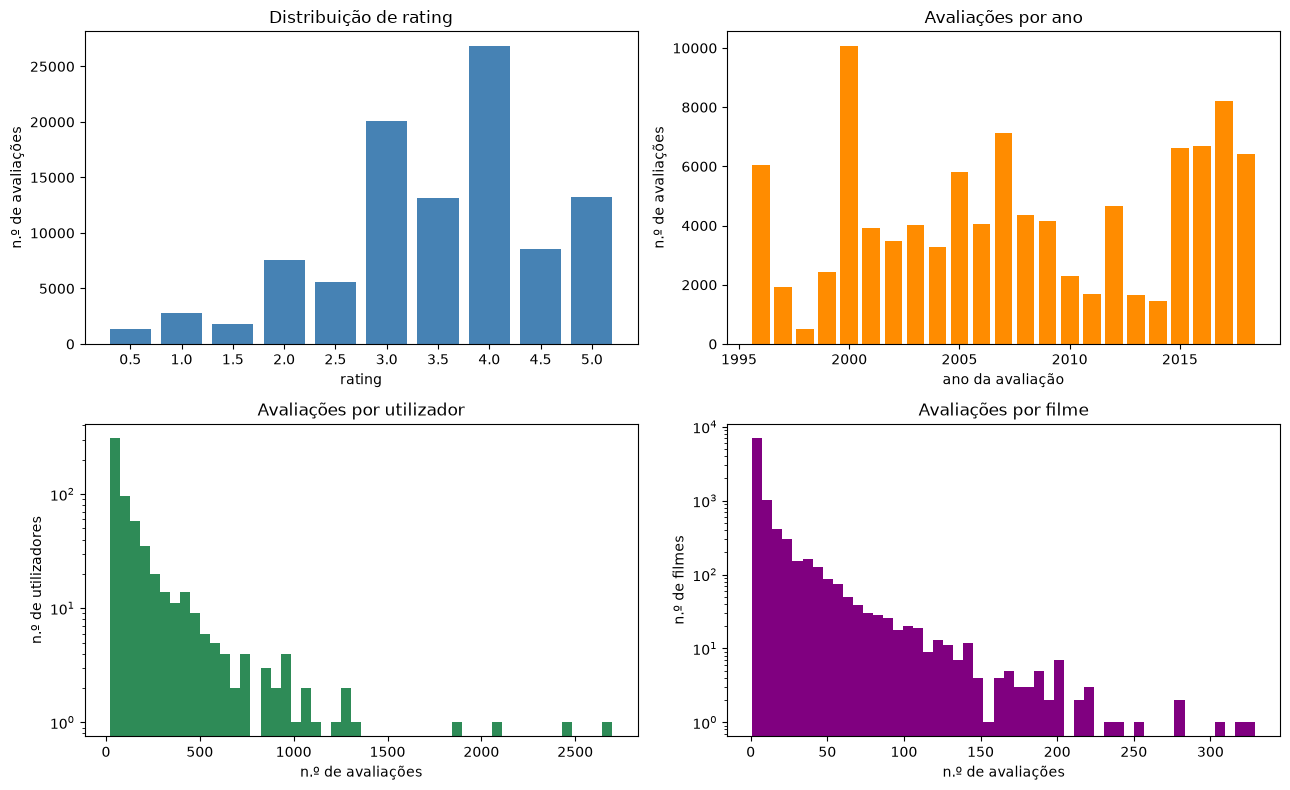

In [25]:
if DETALHE_ATIVO:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    # 1. rating: variável discreta -> gráfico de barras com a contagem de cada valor
    rc = ratings.group_by('rating').len().sort('rating')
    axes[0, 0].bar(rc['rating'].cast(pl.String), rc['len'], color='steelblue')
    axes[0, 0].set(title='Distribuição de rating', xlabel='rating', ylabel='n.º de avaliações')

    # 2. timestamp: avaliações por ano
    ry = ratings_ext.group_by(pl.col('rated_at').dt.year().alias('ano')).len().sort('ano')
    axes[0, 1].bar(ry['ano'], ry['len'], color='darkorange')
    axes[0, 1].set(title='Avaliações por ano', xlabel='ano da avaliação', ylabel='n.º de avaliações')

    # 3. n.º de avaliações por utilizador (cauda longa -> escala log)
    per_user = ratings.group_by('userId').len()
    axes[1, 0].hist(per_user['len'], bins=50, color='seagreen')
    axes[1, 0].set(title='Avaliações por utilizador', xlabel='n.º de avaliações', ylabel='n.º de utilizadores', yscale='log')

    # 4. n.º de avaliações por filme
    per_movie = ratings.group_by('movieId').len()
    axes[1, 1].hist(per_movie['len'], bins=50, color='purple')
    axes[1, 1].set(title='Avaliações por filme', xlabel='n.º de avaliações', ylabel='n.º de filmes', yscale='log')

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


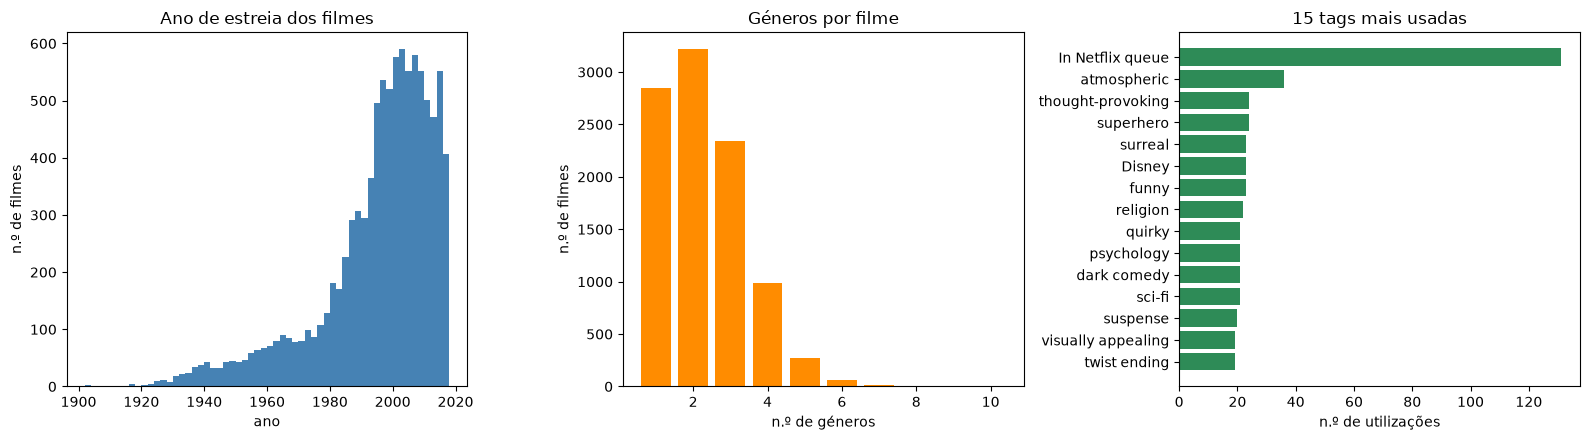

In [26]:
if DETALHE_ATIVO:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # 5. ano de estreia dos filmes
    years = movies_ext['year'].drop_nulls()
    axes[0].hist(years, bins=range(years.min(), years.max() + 2, 2), color='steelblue')
    axes[0].set(title='Ano de estreia dos filmes', xlabel='ano', ylabel='n.º de filmes')

    # 6. n.º de géneros por filme
    ng = movies_ext.group_by('num_genres').len().sort('num_genres')
    axes[1].bar(ng['num_genres'], ng['len'], color='darkorange')
    axes[1].set(title='Géneros por filme', xlabel='n.º de géneros', ylabel='n.º de filmes')

    # 7. tags mais usadas
    if 'tags' in tables:
        top_tags = tags.group_by('tag').len().sort('len', descending=True).head(15).reverse()
        axes[2].barh(top_tags['tag'], top_tags['len'], color='seagreen')
        axes[2].set(title='15 tags mais usadas', xlabel='n.º de utilizações')

    else:
        axes[2].text(0.5, 0.5, 'Etiquetas indisponíveis neste dataset', ha='center')
        axes[2].set_axis_off()

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


O que observar nos gráficos:

- Os valores **inteiros** de rating (3, 4, 5) são muito mais frequentes do que os meios pontos.
- Avaliações por utilizador e por filme têm **cauda longa**: poucos utilizadores/filmes concentram muitas
  avaliações. Por construção do dataset, cada utilizador tem pelo menos 20 avaliações.
- Muitos filmes têm muito poucas avaliações, o que vai ser importante na pergunta sobre a melhor média.

Os valores inteiros serem mais frequentes, leva-nos a crer que o sistema de rating possa ter sido alterado ao longo do tempo, para isso executa-se o seguinte teste.

year,1.0,2.0,3.0,4.0,5.0,0.5,1.5,2.5,3.5,4.5
i32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
1996,195,404,2575,1701,1165,0,0,0,0,0
1997,30,109,659,673,445,0,0,0,0,0
1998,48,71,110,168,110,0,0,0,0,0
1999,112,227,515,835,750,0,0,0,0,0
2000,638,1559,2886,3172,1806,0,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…
2014,24,57,207,346,109,12,45,122,341,176
2015,134,367,1053,1711,806,175,111,477,1119,663
2016,87,300,816,1752,987,118,145,351,1184,963


year,1.0,2.0,3.0,4.0,5.0,0.5,1.5,2.5,3.5,4.5
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1996,3.228477,6.688742,42.63245,28.162252,19.288079,0.0,0.0,0.0,0.0,0.0
1997,1.565762,5.688935,34.394572,35.125261,23.22547,0.0,0.0,0.0,0.0,0.0
1998,9.467456,14.003945,21.696252,33.136095,21.696252,0.0,0.0,0.0,0.0,0.0
1999,4.592046,9.307093,21.115211,34.235342,30.750308,0.0,0.0,0.0,0.0,0.0
2000,6.341318,15.495478,28.685021,31.527681,17.950502,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2014,1.667825,3.961084,14.38499,24.044475,7.574705,0.833912,3.127172,8.47811,23.697012,12.230716
2015,2.025393,5.547158,15.915961,25.861548,12.182588,2.645103,1.677751,7.209794,16.913543,10.021161
2016,1.297926,4.475608,12.173654,26.13755,14.72475,1.760406,2.163211,5.236461,17.663733,14.366701


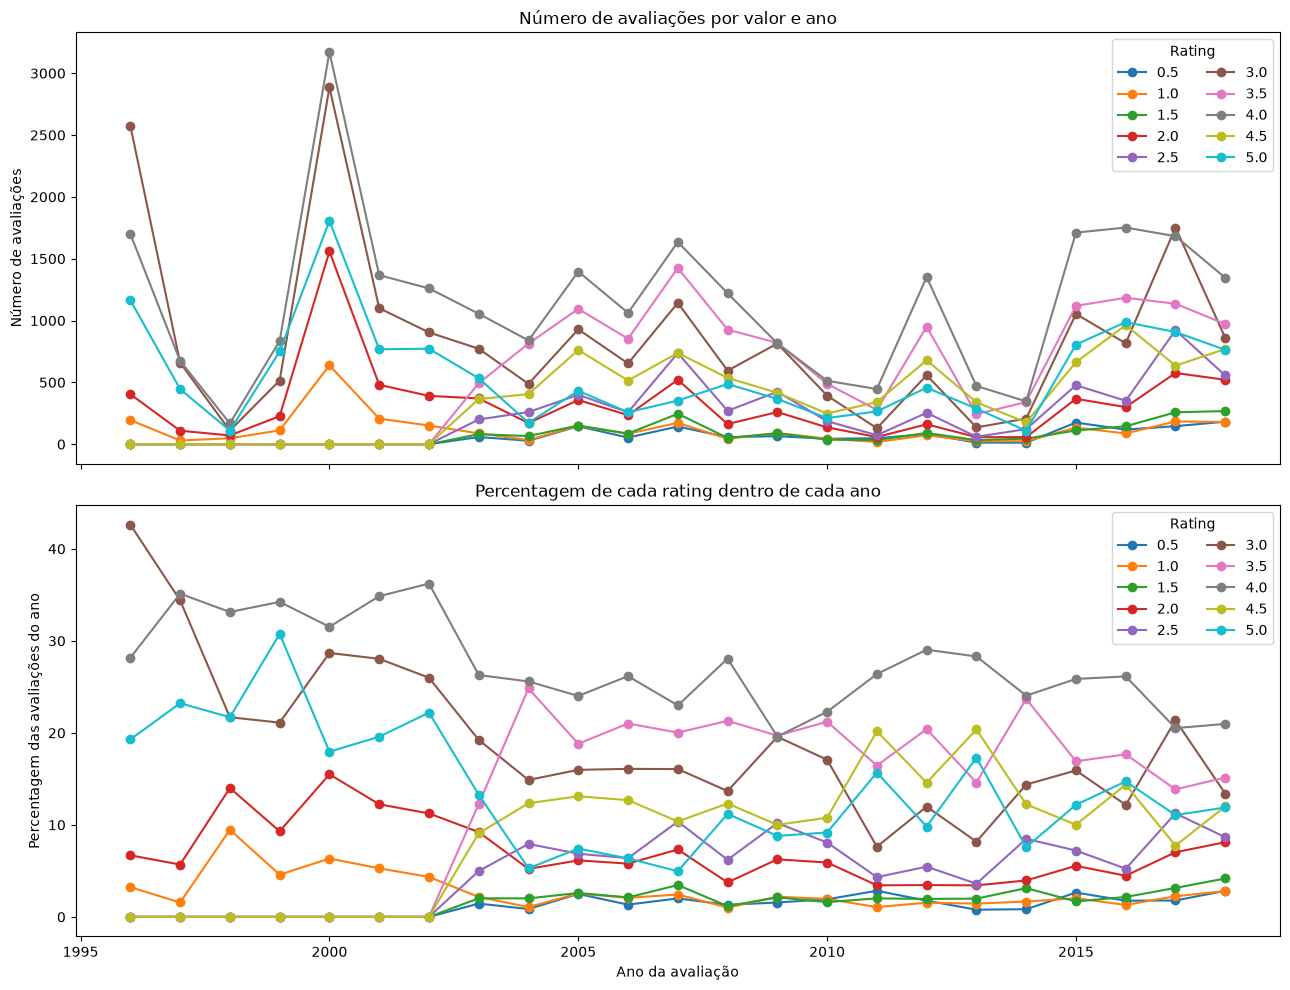

In [27]:
if DETALHE_ATIVO:
    # Converte o timestamp (segundos desde 1970, em UTC) para o ano da avaliação.
    # Para cada ano e valor de rating, conta o número de avaliações.
    ratings_yearly = (
        ratings
        .with_columns(
            pl.from_epoch("timestamp", time_unit="s")
            .dt.year()
            .alias("year")
        )
        .group_by(["year", "rating"])
        .len()
        .with_columns(
            (
                pl.col("len") / pl.col("len").sum().over("year") * 100
            ).alias("percent_of_year")
        )
        .sort(["year", "rating"])
    )

    # Tabela com as contagens: cada linha é um ano e cada coluna um rating.
    counts_by_year = (
        ratings_yearly
        .pivot(on="rating", index="year", values="len")
        .fill_null(0)
        .sort("year")
    )

    # Tabela com a percentagem de cada rating em cada ano.
    percent_by_year = (
        ratings_yearly
        .pivot(on="rating", index="year", values="percent_of_year")
        .fill_null(0)
        .sort("year")
    )

    display(counts_by_year)
    display(percent_by_year)

    # Desenha a evolução das contagens e das percentagens.
    rating_columns = sorted(
        [column for column in counts_by_year.columns if column != "year"],
        key=float
    )

    fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

    for column in rating_columns:
        axes[0].plot(
            counts_by_year["year"],
            counts_by_year[column],
            marker="o",
            label=column
        )
        axes[1].plot(
            percent_by_year["year"],
            percent_by_year[column],
            marker="o",
            label=column
        )

    axes[0].set_title("Número de avaliações por valor e ano")
    axes[0].set_ylabel("Número de avaliações")
    axes[0].legend(title="Rating", ncol=2)

    axes[1].set_title("Percentagem de cada rating dentro de cada ano")
    axes[1].set_xlabel("Ano da avaliação")
    axes[1].set_ylabel("Percentagem das avaliações do ano")
    axes[1].legend(title="Rating", ncol=2)

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Demonstra-se assim que o sistema de ratings foi alterado em 2003.

**Nota metodológica sobre a afirmação anterior:** o aparecimento de meios pontos em determinados anos, nesta amostra, não basta para demonstrar a data de uma alteração do sistema. É necessário confirmar a história do serviço numa fonte documental. Estes dados permitem observar valores e timestamps; mudanças de amostragem, composição e escala também condicionam a interpretação.

**[Humano!! - preenche aqui texto sobre alterações de médias e composição dos utilizadores]**

Compare contagens com proporções anuais, observe quantos utilizadores contribuem em cada ano e distinga uma mudança de comportamento de uma mudança da população observada. Qualquer afirmação sobre uma alteração do serviço precisa de uma referência própria.

profile,num_users,percent_users
str,u32,f64
"""Misto""",369,60.5
"""Só inteiros""",241,39.5


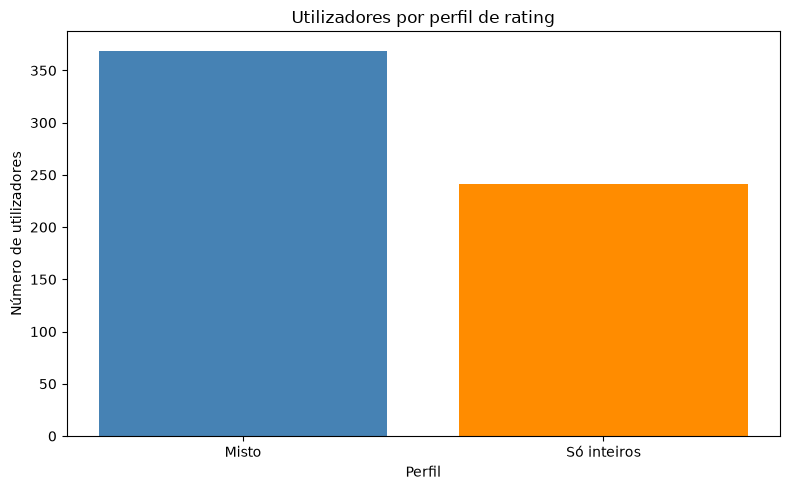

In [28]:
if DETALHE_ATIVO:
    # Conta, por utilizador, quantos ratings são inteiros e quantos são meios pontos.
    user_rating_profiles = (
        ratings
        .group_by("userId")
        .agg(
            pl.len().alias("num_ratings"),
            (pl.col("rating") % 1 == 0).sum().alias("integer_ratings"),
            (pl.col("rating") % 1 != 0).sum().alias("half_star_ratings"),
        )
        .with_columns(
            pl.when(pl.col("half_star_ratings") == 0)
            .then(pl.lit("Só inteiros"))
            .when(pl.col("integer_ratings") == 0)
            .then(pl.lit("Só meios pontos"))
            .otherwise(pl.lit("Misto"))
            .alias("profile")
        )
        .sort("userId")
    )

    # Resume quantos utilizadores pertencem a cada perfil.
    profile_summary = (
        user_rating_profiles
        .group_by("profile")
        .agg(pl.len().alias("num_users"))
        .with_columns(
            (
                pl.col("num_users")
                / pl.col("num_users").sum()
                * 100
            ).round(1).alias("percent_users")
        )
        .sort("num_users", descending=True)
    )

    display(profile_summary)

    # Gráfico do número de utilizadores em cada perfil.
    summary_for_plot = profile_summary.sort("profile")

    plt.figure(figsize=(8, 5))
    plt.bar(
        summary_for_plot["profile"].to_list(),
        summary_for_plot["num_users"].to_list(),
        color=["steelblue", "darkorange", "seagreen"]
    )
    plt.title("Utilizadores por perfil de rating")
    plt.xlabel("Perfil")
    plt.ylabel("Número de utilizadores")
    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


É cumulativo na forma como classifica o perfil, mas o gráfico não soma todos os utilizadores acumulados desde o início.

Em cada ano:
- Para cada utilizador que avaliou pelo menos um filme nesse ano, o código olha para as avaliações dele até ao fim desse ano.
- Só o inclui se, até então, tiver pelo menos duas avaliações.
- Classifica-o pelo histórico acumulado: “Só inteiros”, “Só meios pontos” ou “Misto”.
- Conta-o uma vez nesse ano. Se avaliar em anos seguintes, volta a aparecer nesses anos, com o perfil atualizado.
Por exemplo, se alguém deu ratings inteiros em 2010 e usou um meio ponto em 2012, aparece como “Só inteiros” em 2010 e como “Misto” em 2012. Se não avaliar em 2011, não aparece no ponto de 2011.

Portanto, as linhas mostram a composição dos utilizadores ativos em cada ano, segundo o histórico que tinham até então. Um utilizador deixa de ser “Só inteiros” quando dá o primeiro rating não inteiro.

Utilizadores com apenas uma avaliação: 0


userId,total_ratings
i64,u32


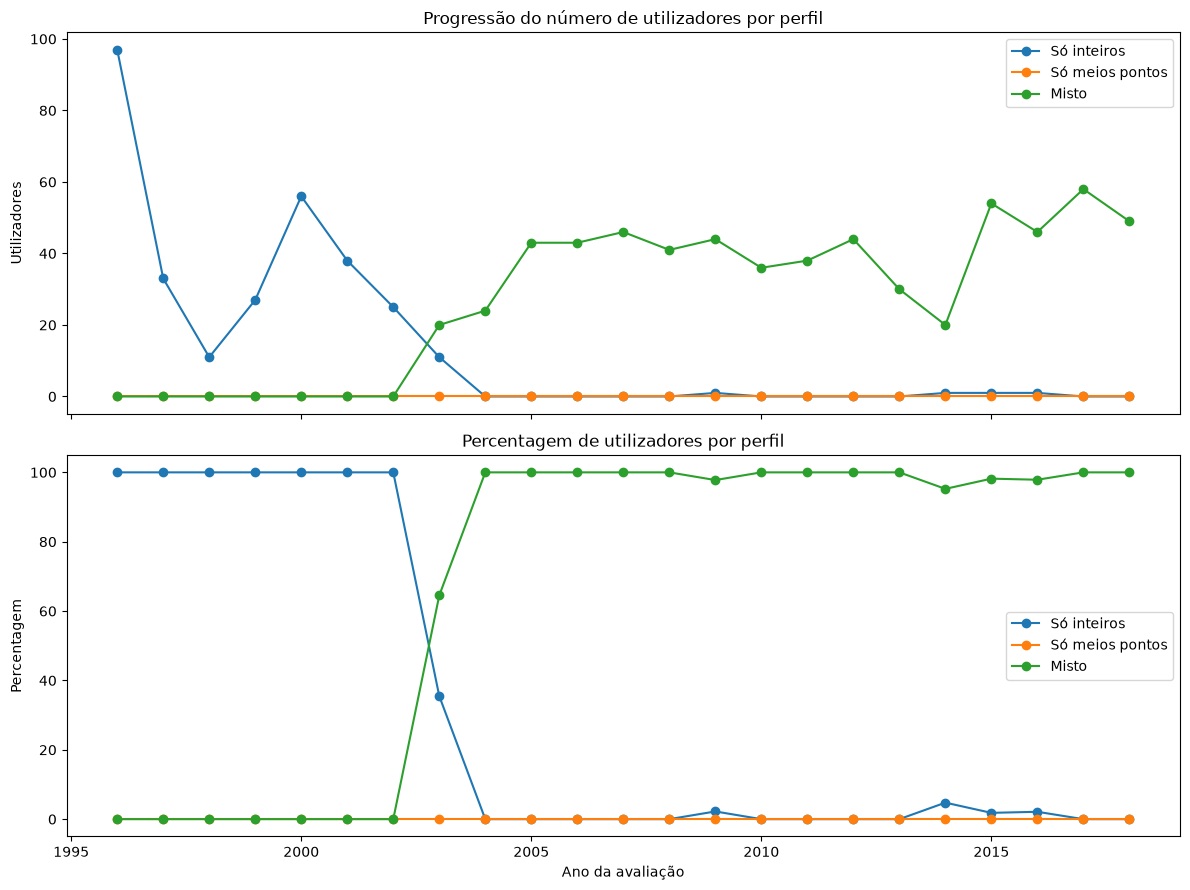

year,profile,num_users,percent_of_users
i64,str,u32,f64
1996,"""Misto""",0,0.0
1996,"""Só inteiros""",97,100.0
1996,"""Só meios pontos""",0,0.0
1997,"""Misto""",0,0.0
1997,"""Só inteiros""",33,100.0
…,…,…,…
2017,"""Só inteiros""",0,0.0
2017,"""Só meios pontos""",0,0.0
2018,"""Misto""",49,100.0


In [29]:
if DETALHE_ATIVO:
    # Cria um grupo separado para utilizadores com apenas uma avaliação no dataset.
    user_totals = (
        ratings
        .group_by("userId")
        .agg(pl.len().alias("total_ratings"))
    )

    single_rating_users = user_totals.filter(pl.col("total_ratings") == 1)

    print("Utilizadores com apenas uma avaliação:", single_rating_users.height)
    display(single_rating_users)

    # Para cada utilizador e ano, conta ratings inteiros e meios pontos.
    ratings_by_user_year = (
        ratings
        .with_columns(
            pl.from_epoch("timestamp", time_unit="s")
            .dt.year()
            .alias("year")
        )
        .group_by(["userId", "year"])
        .agg(
            pl.len().alias("ratings_this_year"),
            (pl.col("rating") % 1 == 0).sum().alias("integers_this_year"),
            (pl.col("rating") % 1 != 0).sum().alias("half_stars_this_year"),
        )
        .sort(["userId", "year"])
    )

    # Soma as avaliações progressivamente: em cada ano, inclui o histórico até esse ano.
    user_profiles_over_time = (
        ratings_by_user_year
        .with_columns(
            pl.col("ratings_this_year").cum_sum().over("userId").alias("ratings_to_date"),
            pl.col("integers_this_year").cum_sum().over("userId").alias("integers_to_date"),
            pl.col("half_stars_this_year").cum_sum().over("userId").alias("half_stars_to_date"),
        )
        # Exclui utilizadores que ainda só tinham uma avaliação até esse ano.
        .filter(pl.col("ratings_to_date") >= 2)
        .with_columns(
            pl.when(pl.col("half_stars_to_date") == 0)
            .then(pl.lit("Só inteiros"))
            .when(pl.col("integers_to_date") == 0)
            .then(pl.lit("Só meios pontos"))
            .otherwise(pl.lit("Misto"))
            .alias("profile")
        )
    )

    # Conta utilizadores por perfil e ano.
    # Um utilizador conta uma vez por ano, de acordo com o seu perfil acumulado até esse ano.
    profiles_by_year = (
        user_profiles_over_time
        .group_by(["year", "profile"])
        .agg(pl.len().alias("num_users"))
    )

    # Completa combinações sem utilizadores com zero, para que as linhas do gráfico sejam contínuas.
    years = sorted(user_profiles_over_time["year"].unique().to_list())
    profile_names = ["Só inteiros", "Só meios pontos", "Misto"]

    profile_grid = pl.DataFrame(
        [(year, profile) for year in years for profile in profile_names],
        schema=["year", "profile"],
        orient="row",
    )

    profiles_by_year = (
        profile_grid
        .join(profiles_by_year, on=["year", "profile"], how="left")
        .with_columns(pl.col("num_users").fill_null(0))
        .sort(["year", "profile"])
        .with_columns(
            (
                pl.col("num_users")
                / pl.col("num_users").sum().over("year")
                * 100
            ).alias("percent_of_users")
        )
    )

    # Gráfico: contagem de utilizadores e percentagem de cada perfil por ano.
    fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

    for profile in profile_names:
        profile_data = profiles_by_year.filter(pl.col("profile") == profile)

        axes[0].plot(
            profile_data["year"],
            profile_data["num_users"],
            marker="o",
            label=profile,
        )
        axes[1].plot(
            profile_data["year"],
            profile_data["percent_of_users"],
            marker="o",
            label=profile,
        )

    axes[0].set_title("Progressão do número de utilizadores por perfil")
    axes[0].set_ylabel("Utilizadores")
    axes[0].legend()

    axes[1].set_title("Percentagem de utilizadores por perfil")
    axes[1].set_xlabel("Ano da avaliação")
    axes[1].set_ylabel("Percentagem")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    display(profiles_by_year)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


G

### Dois conceitos diferentes de progressão

A primeira evolução conta apenas utilizadores ativos no ano. A seguinte mantém os utilizadores elegíveis nos anos sem atividade e representa a população acumulada. Entram quando têm pelo menos duas avaliações; podem mudar de perfil. A variação líquida de um perfil inclui entradas e saídas, pelo que pode ser negativa. Nenhuma destas curvas identifica pessoas entre datasets.

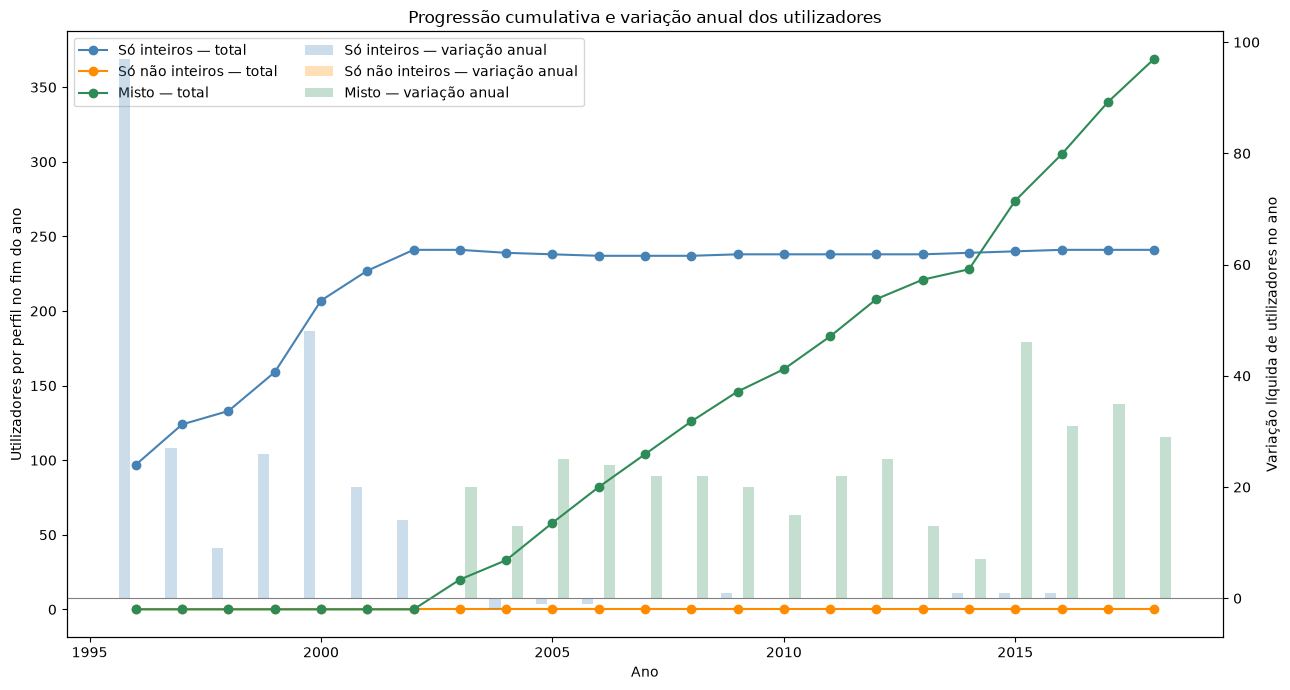

In [30]:
if DETALHE_ATIVO:
    import polars as pl
    import matplotlib.pyplot as plt

    # 1. Acrescenta o ano da avaliação.
    profile_activity = ratings.with_columns(
        pl.from_epoch("timestamp", time_unit="s")
        .dt.year()
        .cast(pl.Int64)
        .alias("year")
    )

    years = list(range(
        profile_activity["year"].min(),
        profile_activity["year"].max() + 1,
    ))

    profile_names = ["Só inteiros", "Só não inteiros", "Misto"]

    # 2. Conta ratings inteiros e não inteiros por utilizador e ano.
    yearly_user_counts = (
        profile_activity
        .group_by(["userId", "year"])
        .agg(
            (pl.col("rating") % 1 == 0).sum().alias("integer_count"),
            (pl.col("rating") % 1 != 0).sum().alias("non_integer_count"),
        )
    )

    # 3. Cria todos os pares utilizador/ano.
    # Assim, um utilizador continua representado nos anos em que não avaliou.
    user_year_grid = (
        pl.DataFrame({"year": years})
        .join(profile_activity.select("userId").unique(), how="cross")
    )

    profiles_over_time = (
        user_year_grid
        .join(yearly_user_counts, on=["userId", "year"], how="left")
        .with_columns(
            pl.col("integer_count").fill_null(0),
            pl.col("non_integer_count").fill_null(0),
        )
        .sort(["userId", "year"])
        .with_columns(
            pl.col("integer_count").cum_sum().over("userId"),
            pl.col("non_integer_count").cum_sum().over("userId"),
        )
        # Só entra no gráfico depois de acumular pelo menos duas avaliações.
        # Quem só tem uma avaliação em todo o dataset nunca entra.
        .filter(
            (pl.col("integer_count") + pl.col("non_integer_count")) >= 2
        )
        .with_columns(
            pl.when(pl.col("non_integer_count") == 0)
            .then(pl.lit("Só inteiros"))
            .when(pl.col("integer_count") == 0)
            .then(pl.lit("Só não inteiros"))
            .otherwise(pl.lit("Misto"))
            .alias("profile")
        )
    )

    # 4. Conta utilizadores únicos em cada perfil no fim de cada ano.
    profile_counts = (
        profiles_over_time
        .group_by(["year", "profile"])
        .agg(pl.col("userId").n_unique().alias("num_users"))
    )

    year_profile_grid = (
        pl.DataFrame({"year": years})
        .join(pl.DataFrame({"profile": profile_names}), how="cross")
    )

    # 5. A variação líquida é a população atual menos a do ano anterior.
    # Uma transição para Misto reduz o grupo anterior e aumenta Misto.
    profile_evolution = (
        year_profile_grid
        .join(profile_counts, on=["year", "profile"], how="left")
        .with_columns(
            pl.col("num_users").fill_null(0).cast(pl.Int64)
        )
        .sort(["profile", "year"])
        .with_columns(
            (
                pl.col("num_users")
                - pl.col("num_users").shift(1).over("profile").fill_null(0)
            ).alias("net_gain")
        )
    )

    # 6. Linhas: população de cada perfil. Barras: variação líquida anual.
    colors = {
        "Só inteiros": "steelblue",
        "Só não inteiros": "darkorange",
        "Misto": "seagreen",
    }

    bar_width = 0.24
    offsets = {
        "Só inteiros": -bar_width,
        "Só não inteiros": 0,
        "Misto": bar_width,
    }

    fig, ax_users = plt.subplots(figsize=(13, 7))
    ax_change = ax_users.twinx()

    for profile in profile_names:
        profile_data = (
            profile_evolution
            .filter(pl.col("profile") == profile)
            .sort("year")
        )

        ax_users.plot(
            profile_data["year"].to_list(),
            profile_data["num_users"].to_list(),
            marker="o",
            color=colors[profile],
            label=f"{profile} — total",
        )

        ax_change.bar(
            [
                year + offsets[profile]
                for year in profile_data["year"].to_list()
            ],
            profile_data["net_gain"].to_list(),
            width=bar_width,
            alpha=0.28,
            color=colors[profile],
            label=f"{profile} — variação anual",
        )

    ax_users.set_title("Progressão cumulativa e variação anual dos utilizadores")
    ax_users.set_xlabel("Ano")
    ax_users.set_ylabel("Utilizadores por perfil no fim do ano")
    ax_change.set_ylabel("Variação líquida de utilizadores no ano")
    ax_change.axhline(0, color="gray", linewidth=0.8)

    line_handles, line_labels = ax_users.get_legend_handles_labels()
    bar_handles, bar_labels = ax_change.get_legend_handles_labels()

    ax_users.legend(
        line_handles + bar_handles,
        line_labels + bar_labels,
        loc="upper left",
        ncol=2,
    )

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


<a id="perguntas"></a>
### Perguntas analíticas e validação das respostas

Nos rankings, ordena-se o valor sem arredondamento e usa-se `movieId` para resolver empates. O arredondamento serve apenas a apresentação. As comparações obrigatórias usam asserções que interrompem a execução se houver divergência.

## 7. Perguntas sobre o dataset (Python e SQL)

Cada pergunta é respondida duas vezes, em **Polars** e em **DuckDB SQL**, e no fim confirma-se que
as duas respostas são iguais. A função `same()` compara duas tabelas ignorando diferenças de tipo
(`UInt32` vs `Int64`) e diferenças mínimas de arredondamento entre Polars e DuckDB.

In [31]:
if DETALHE_ATIVO:
    def same(a: pl.DataFrame, b: pl.DataFrame, tol: float = 1e-8) -> bool:
        # Uma divergência interrompe a execução; não basta imprimir False.
        assert_frame_equal(a, b, check_dtypes=False, check_exact=False, abs_tol=tol, rel_tol=tol)
        return True
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


### 7.1 Quais são os géneros de filmes no dataset?

Reutilizamos `movie_genres` (secção 3), em que cada linha é um par (filme, género).
Em SQL, `string_split` + `unnest` faz o mesmo que `str.split` + `explode`.

In [32]:
if DETALHE_ATIVO:
    # Python
    genres_py = movie_genres.select('genre').unique().sort('genre')
    print(genres_py.height, 'géneros (inclui "(no genres listed)")')
    display(genres_py['genre'].to_list())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


20 géneros (inclui "(no genres listed)")


['(no genres listed)',
 'Action',
 'Adventure',
 'Animation',
 'Children',
 'Comedy',
 'Crime',
 'Documentary',
 'Drama',
 'Fantasy',
 'Film-Noir',
 'Horror',
 'IMAX',
 'Musical',
 'Mystery',
 'Romance',
 'Sci-Fi',
 'Thriller',
 'War',
 'Western']

In [33]:
if DETALHE_ATIVO:
    # SQL
    genres_sql = duckdb.sql(f'''
        SELECT DISTINCT genre
        FROM (SELECT unnest(string_split(genres, '|')) AS genre FROM '{MOVIES}')
        ORDER BY genre
    ''').pl()
    print('Python e SQL iguais:', same(genres_py, genres_sql))
    display(genres_sql)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Python e SQL iguais: True


genre
str
"""(no genres listed)"""
"""Action"""
"""Adventure"""
"""Animation"""
"""Children"""
…
"""Romance"""
"""Sci-Fi"""
"""Thriller"""


### 7.2 Qual é o número de filmes por género?

Como um filme pode ter vários géneros, a soma das contagens é maior do que o número de filmes.

In [34]:
if DETALHE_ATIVO:
    # Python
    movies_per_genre_py = (
        movie_genres
          .group_by('genre')
          .agg(pl.len().alias('num_movies'))
          .with_columns((pl.col('num_movies') / movies.height * 100).round(1).alias('pct_movies'))
          .sort(['num_movies', 'genre'], descending=[True, False])
    )
    print('Soma das contagens:', movies_per_genre_py['num_movies'].sum(), '| filmes:', movies.height)
    display(movies_per_genre_py)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Soma das contagens: 22084 | filmes: 9742


genre,num_movies,pct_movies
str,u32,f64
"""Drama""",4361,44.8
"""Comedy""",3756,38.6
"""Thriller""",1894,19.4
"""Action""",1828,18.8
"""Romance""",1596,16.4
…,…,…
"""Musical""",334,3.4
"""Western""",167,1.7
"""IMAX""",158,1.6


In [35]:
if DETALHE_ATIVO:
    # SQL
    movies_per_genre_sql = duckdb.sql(f'''
        WITH movie_genre AS (
            SELECT movieId, unnest(string_split(genres, '|')) AS genre
            FROM '{MOVIES}'
        )
        SELECT genre,
               COUNT(*)                                                  AS num_movies,
               ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM '{MOVIES}'), 1) AS pct_movies
        FROM movie_genre
        GROUP BY genre
        ORDER BY num_movies DESC, genre
    ''').pl()
    print('Python e SQL iguais:', same(movies_per_genre_py.select('genre', 'num_movies'),
                                        movies_per_genre_sql.select('genre', 'num_movies')))
    display(movies_per_genre_sql)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Python e SQL iguais: True


genre,num_movies,pct_movies
str,i64,f64
"""Drama""",4361,44.8
"""Comedy""",3756,38.6
"""Thriller""",1894,19.4
"""Action""",1828,18.8
"""Romance""",1596,16.4
…,…,…
"""Musical""",334,3.4
"""Western""",167,1.7
"""IMAX""",158,1.6


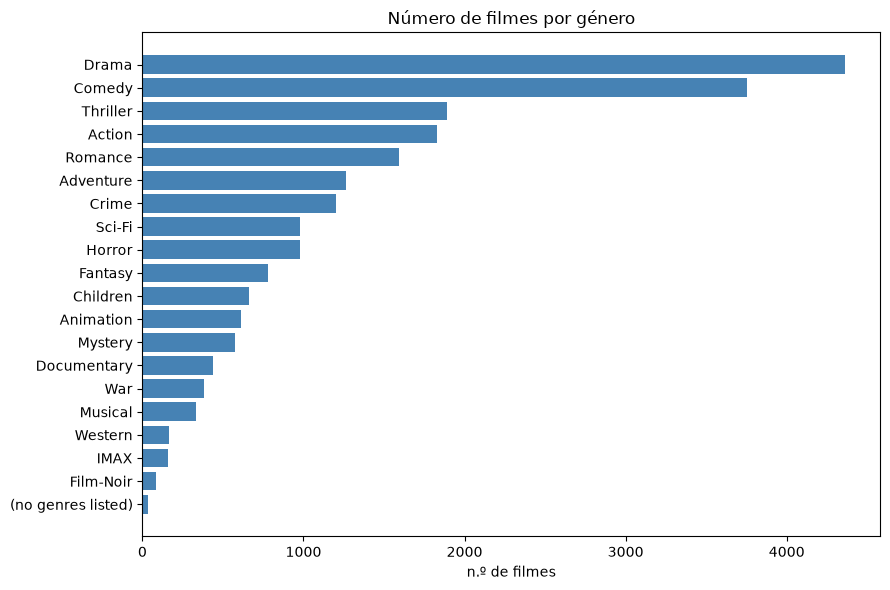

In [36]:
if DETALHE_ATIVO:
    plot_df = movies_per_genre_py.reverse()
    plt.figure(figsize=(9, 6))
    plt.barh(plot_df['genre'], plot_df['num_movies'], color='steelblue')
    plt.title('Número de filmes por género')
    plt.xlabel('n.º de filmes')
    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


### 7.3 Qual é a distribuição das avaliações por utilizador?

Olhamos para isto de duas formas:

1. **Resumo por utilizador**: quantas avaliações fez, média, desvio-padrão, mínimo, mediana e máximo.
2. **Distribuição dos valores de rating por utilizador**: quantas vezes cada utilizador deu 0.5, 1.0, …, 5.0.

In [37]:
if DETALHE_ATIVO:
    # Python: resumo por utilizador
    user_stats_py = (
        ratings
          .group_by('userId')
          .agg(
              pl.len().alias('num_ratings'),
              pl.col('rating').mean().alias('mean'),
              pl.col('rating').std().alias('std'),
              pl.col('rating').min().alias('min'),
              pl.col('rating').median().alias('median'),
              pl.col('rating').max().alias('max'),
          )
          .sort('userId')
    )
    display(user_stats_py)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


userId,num_ratings,mean,std,min,median,max
i64,u32,f64,f64,f64,f64,f64
1,232,4.366379,0.800048,1.0,5.0,5.0
2,29,3.948276,0.805615,2.0,4.0,5.0
3,39,2.435897,2.090642,0.5,0.5,5.0
4,216,3.555556,1.314204,1.0,4.0,5.0
5,44,3.636364,0.990441,1.0,4.0,5.0
…,…,…,…,…,…,…
606,1115,3.657399,0.724121,0.5,4.0,5.0
607,187,3.786096,0.965657,1.0,4.0,5.0
608,831,3.134176,1.079262,0.5,3.0,5.0


In [38]:
if DETALHE_ATIVO:
    # SQL: o mesmo resumo
    user_stats_sql = duckdb.sql(f'''
        SELECT userId,
               COUNT(*)                         AS num_ratings,
               AVG(rating)            AS mean,
               STDDEV_SAMP(rating)    AS std,
               MIN(rating)                      AS min,
               MEDIAN(rating)                   AS median,
               MAX(rating)                      AS max
        FROM '{RATINGS}'
        GROUP BY userId
        ORDER BY userId
    ''').pl()
    print('Python e SQL iguais:', same(user_stats_py, user_stats_sql))
    display(user_stats_sql)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Python e SQL iguais: True


userId,num_ratings,mean,std,min,median,max
i64,i64,f64,f64,f64,f64,f64
1,232,4.366379,0.800048,1.0,5.0,5.0
2,29,3.948276,0.805615,2.0,4.0,5.0
3,39,2.435897,2.090642,0.5,0.5,5.0
4,216,3.555556,1.314204,1.0,4.0,5.0
5,44,3.636364,0.990441,1.0,4.0,5.0
…,…,…,…,…,…,…
606,1115,3.657399,0.724121,0.5,4.0,5.0
607,187,3.786096,0.965657,1.0,4.0,5.0
608,831,3.134176,1.079262,0.5,3.0,5.0


In [39]:
if DETALHE_ATIVO:
    # Como se distribuem estas estatísticas pelos utilizadores?
    display(user_stats_py.select('num_ratings', 'mean', 'std', 'median').describe())
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


statistic,num_ratings,mean,std,median
str,f64,f64,f64,f64
"""count""",610.0,610.0,610.0,610.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",165.304918,3.657222,0.927116,3.760246
"""std""",269.480584,0.480635,0.266108,0.60172
"""min""",20.0,1.275,0.0,0.5
"""25%""",35.0,3.36,0.736025,3.5
"""50%""",71.0,3.696463,0.902378,4.0
"""75%""",168.0,4.0,1.079262,4.0
"""max""",2698.0,5.0,2.090642,5.0


In [40]:
if DETALHE_ATIVO:
    # Python: contagem de cada valor de rating por utilizador (formato largo)
    rating_dist_py = (
        ratings
          .pivot(on='rating', index='userId', values='rating', aggregate_function='len', sort_columns=True)
          .fill_null(0)
          .sort('userId')
    )
    display(rating_dist_py.head(10))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


userId,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
1,0,1,0,5,0,26,0,76,0,124
2,0,0,0,1,1,4,4,9,4,6
3,20,0,0,1,0,1,1,1,5,10
4,0,23,0,26,0,39,0,64,0,64
5,0,1,0,3,0,17,0,13,0,10
6,0,7,0,13,0,152,0,102,0,40
7,6,12,12,11,7,16,18,28,29,13
8,0,1,0,3,0,21,0,12,0,10
9,0,6,0,6,0,12,0,14,0,8


In [41]:
if DETALHE_ATIVO:
    # SQL: PIVOT faz o mesmo
    rating_dist_sql = duckdb.sql(f'''
        PIVOT (SELECT userId, rating FROM '{RATINGS}')
        ON rating
        USING COUNT(*)
        GROUP BY userId
        ORDER BY userId
    ''').pl()
    display(rating_dist_sql.head(10))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


userId,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
1,0,1,0,5,0,26,0,76,0,124
2,0,0,0,1,1,4,4,9,4,6
3,20,0,0,1,0,1,1,1,5,10
4,0,23,0,26,0,39,0,64,0,64
5,0,1,0,3,0,17,0,13,0,10
6,0,7,0,13,0,152,0,102,0,40
7,6,12,12,11,7,16,18,28,29,13
8,0,1,0,3,0,21,0,12,0,10
9,0,6,0,6,0,12,0,14,0,8


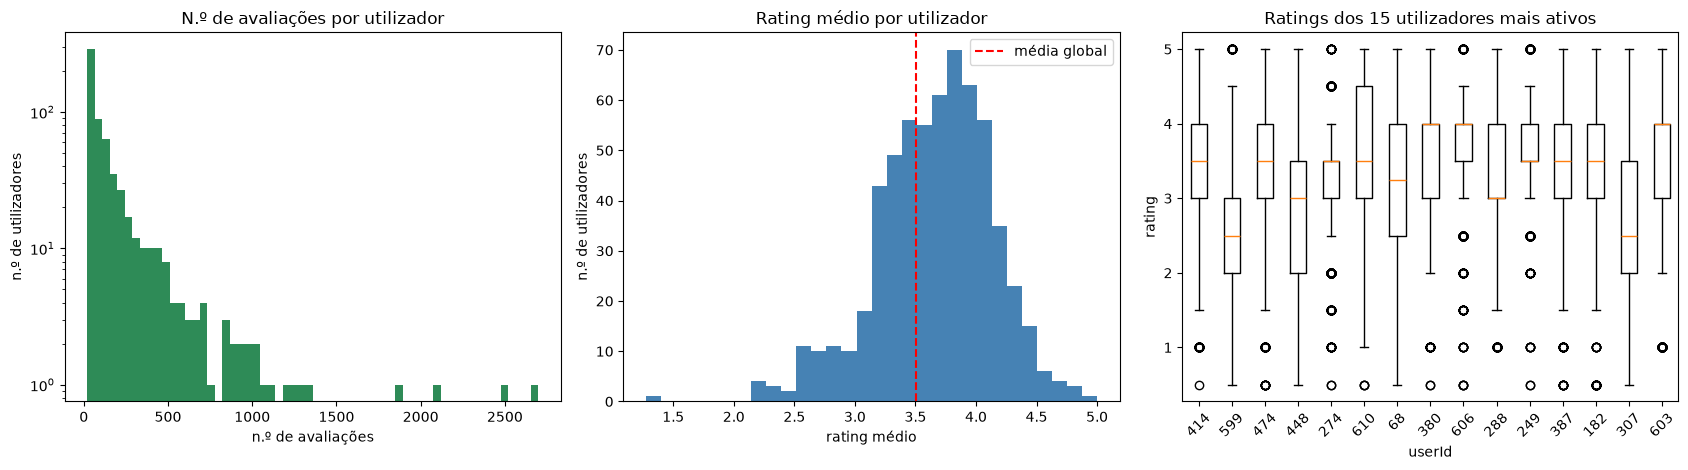

In [42]:
if DETALHE_ATIVO:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

    # a) n.º de avaliações por utilizador
    axes[0].hist(user_stats_py['num_ratings'], bins=60, color='seagreen')
    axes[0].set(title='N.º de avaliações por utilizador', xlabel='n.º de avaliações',
                ylabel='n.º de utilizadores', yscale='log')

    # b) rating médio por utilizador
    axes[1].hist(user_stats_py['mean'], bins=30, color='steelblue')
    axes[1].axvline(ratings['rating'].mean(), color='red', ls='--', label='média global')
    axes[1].set(title='Rating médio por utilizador', xlabel='rating médio', ylabel='n.º de utilizadores')
    axes[1].legend()

    # c) boxplot dos 15 utilizadores mais ativos
    top_users = user_stats_py.sort('num_ratings', descending=True).head(15)['userId'].to_list()
    data = [ratings.filter(pl.col('userId') == u)['rating'].to_numpy() for u in top_users]
    axes[2].boxplot(data, tick_labels=[str(u) for u in top_users])
    axes[2].set(title='Ratings dos 15 utilizadores mais ativos', xlabel='userId', ylabel='rating')
    axes[2].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


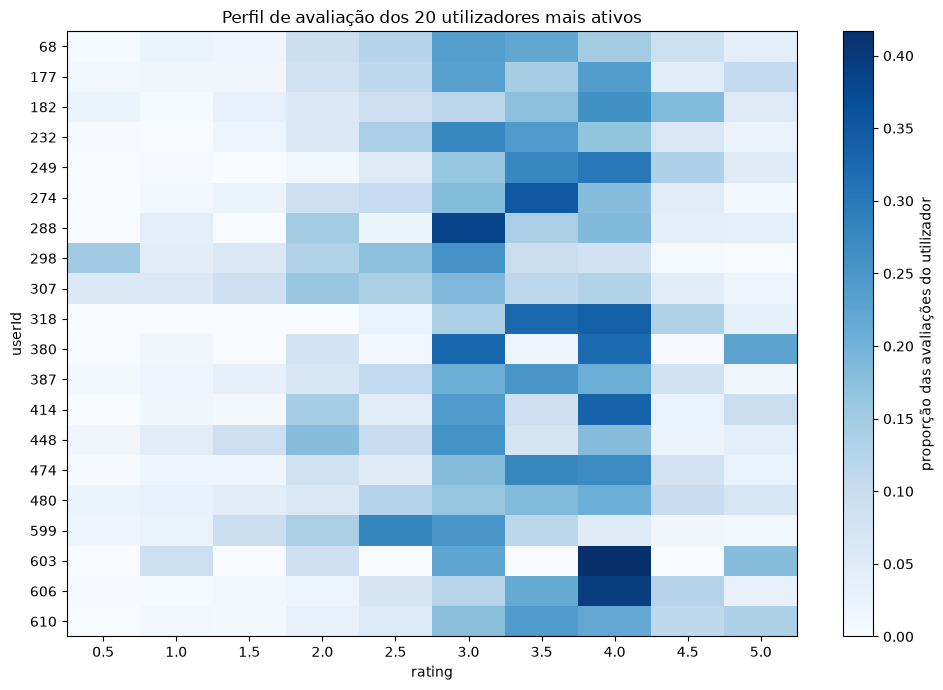

In [43]:
if DETALHE_ATIVO:
    # Heatmap: proporção de cada valor de rating nos 20 utilizadores mais ativos
    top20 = user_stats_py.sort('num_ratings', descending=True).head(20)['userId']
    value_cols = [c for c in rating_dist_py.columns if c != 'userId']
    heat = (rating_dist_py.filter(pl.col('userId').is_in(top20.to_list()))
            .with_columns(total=pl.sum_horizontal(value_cols))
            .with_columns([pl.col(c) / pl.col('total') for c in value_cols]))

    plt.figure(figsize=(10, 7))
    plt.imshow(heat.select(value_cols).to_numpy(), aspect='auto', cmap='Blues')
    plt.colorbar(label='proporção das avaliações do utilizador')
    plt.xticks(range(len(value_cols)), value_cols)
    plt.yticks(range(heat.height), heat['userId'].to_list())
    plt.xlabel('rating')
    plt.ylabel('userId')
    plt.title('Perfil de avaliação dos 20 utilizadores mais ativos')
    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


O heatmap mostra que os utilizadores têm **perfis diferentes**: uns usam toda a escala, outros só valores
inteiros, outros concentram-se em notas altas. É por isso que, em sistemas de recomendação, é comum
normalizar os ratings por utilizador (subtrair a média de cada um).

year,user_band,avg_user_rating,num_users,num_reviews
i32,str,f64,u32,u32
1996,"""21–50""",3.659343,47,1597
1996,"""51–100""",3.544513,33,2293
1996,"""6–20""",4.0,1,20
1996,"""Mais de 100""",3.445842,16,2130
1997,"""21–50""",3.60114,19,578
…,…,…,…,…
2017,"""51–100""",3.81023,8,470
2017,"""Mais de 100""",3.576422,33,7256
2018,"""21–50""",3.956107,12,346


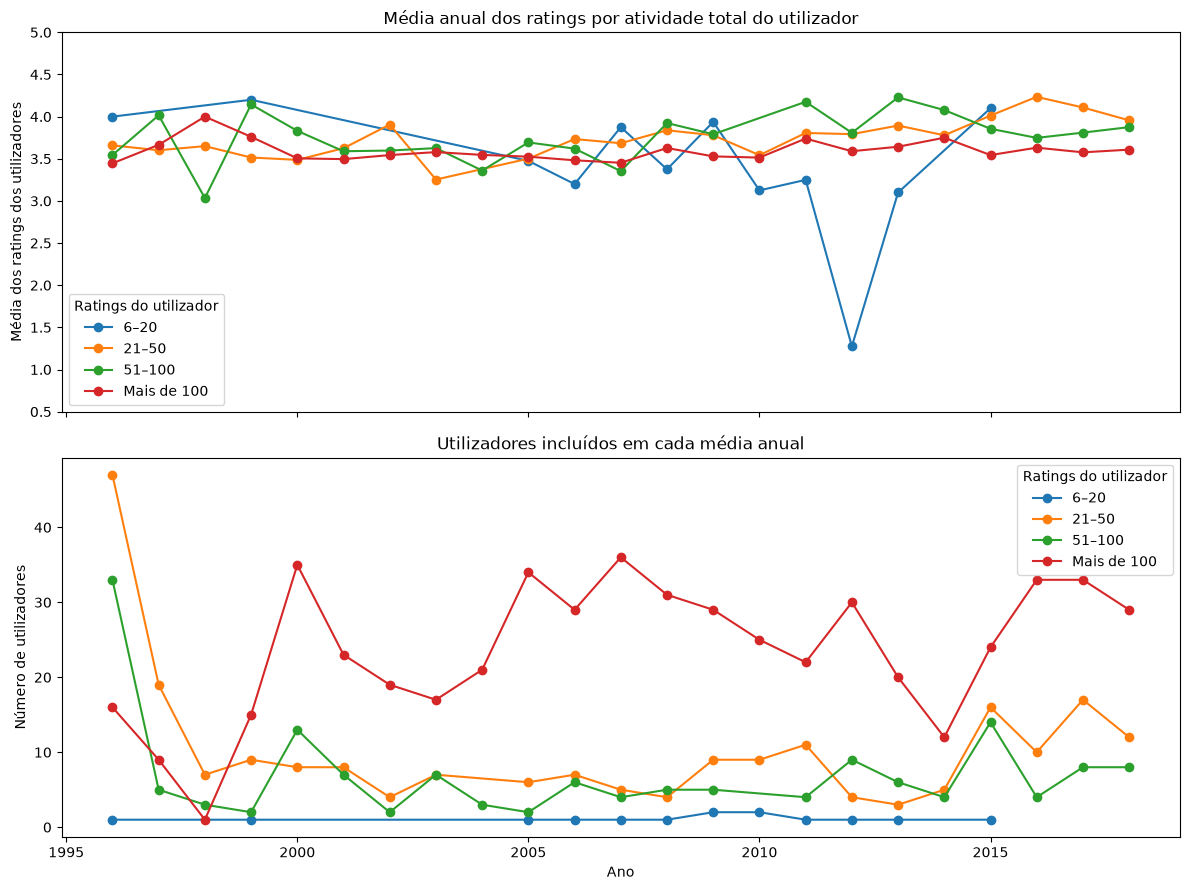

In [44]:
if DETALHE_ATIVO:
    # Agrupa utilizadores pelo número total de ratings que fizeram no dataset.
    user_review_counts = (
        ratings
        .group_by("userId")
        .agg(pl.len().alias("total_reviews"))
    )

    # Acrescenta o ano da avaliação e o grupo de atividade de cada utilizador.
    ratings_with_user_band = (
        ratings
        .with_columns(
            pl.from_epoch("timestamp", time_unit="s").dt.year().alias("year")
        )
        .join(user_review_counts, on="userId")
        .with_columns(
            pl.when(pl.col("total_reviews") <= 5)
            .then(pl.lit("Até 5"))
            .when(pl.col("total_reviews") <= 20)
            .then(pl.lit("6–20"))
            .when(pl.col("total_reviews") <= 50)
            .then(pl.lit("21–50"))
            .when(pl.col("total_reviews") <= 100)
            .then(pl.lit("51–100"))
            .otherwise(pl.lit("Mais de 100"))
            .alias("user_band")
        )
    )

    # Primeiro calcula a média de cada utilizador em cada ano.
    # Assim, cada utilizador tem o mesmo peso na média do seu grupo.
    user_year_means = (
        ratings_with_user_band
        .group_by(["year", "user_band", "userId"])
        .agg(
            pl.col("rating").mean().alias("user_year_avg"),
            pl.len().alias("reviews_in_year"),
        )
    )

    # Depois calcula a média dos utilizadores de cada grupo e ano.
    yearly_user_band = (
        user_year_means
        .group_by(["year", "user_band"])
        .agg(
            pl.col("user_year_avg").mean().alias("avg_user_rating"),
            pl.len().alias("num_users"),
            pl.col("reviews_in_year").sum().alias("num_reviews"),
        )
        .sort(["year", "user_band"])
    )

    display(yearly_user_band)

    # Gráfico: média anual por grupo e número de utilizadores que contribuem.
    user_bands = ["Até 5", "6–20", "21–50", "51–100", "Mais de 100"]

    fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

    for band in user_bands:
        band_data = yearly_user_band.filter(pl.col("user_band") == band)

        if band_data.height > 0:
            axes[0].plot(
                band_data["year"],
                band_data["avg_user_rating"],
                marker="o",
                label=band,
            )
            axes[1].plot(
                band_data["year"],
                band_data["num_users"],
                marker="o",
                label=band,
            )

    axes[0].set_title("Média anual dos ratings por atividade total do utilizador")
    axes[0].set_ylabel("Média dos ratings dos utilizadores")
    axes[0].set_ylim(0.5, 5.0)
    axes[0].legend(title="Ratings do utilizador")

    axes[1].set_title("Utilizadores incluídos em cada média anual")
    axes[1].set_xlabel("Ano")
    axes[1].set_ylabel("Número de utilizadores")
    axes[1].legend(title="Ratings do utilizador")

    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


### 7.4 Quais são os filmes com a média de avaliação mais alta?

Sem um número mínimo de avaliações, o topo fica cheio de filmes com **uma única avaliação de 5.0**.
Por isso, como na secção 2, exigimos pelo menos 100 avaliações.

In [45]:
if DETALHE_ATIVO:
    naive = (ratings.group_by('movieId')
        .agg(pl.col('rating').mean().alias('avg_rating'), pl.len().alias('num_ratings'))
        .join(movies.select('movieId','title'), on='movieId')
        .sort(['avg_rating','movieId'], descending=[True,False]))
    print('Filmes com média 5,0:', naive.filter(pl.col('avg_rating')==5).height,
          '| com uma avaliação:', naive.filter((pl.col('avg_rating')==5)&(pl.col('num_ratings')==1)).height)
    display(naive.head(10))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Filmes com média 5,0: 296 | com uma avaliação: 289


movieId,avg_rating,num_ratings,title
i64,f64,u32,str
53,5.0,2,"""Lamerica (1994)"""
99,5.0,2,"""Heidi Fleiss: Hollywood Madam …"
148,5.0,1,"""Awfully Big Adventure, An (199…"
467,5.0,1,"""Live Nude Girls (1995)"""
495,5.0,1,"""In the Realm of the Senses (Ai…"
496,5.0,1,"""What Happened Was... (1994)"""
626,5.0,1,"""Thin Line Between Love and Hat…"
633,5.0,1,"""Denise Calls Up (1995)"""
876,5.0,1,"""Supercop 2 (Project S) (Chao j…"


In [46]:
if DETALHE_ATIVO:
    MIN_RATINGS = 100
    top10_py = (ratings.join(movies.select('movieId','title'), on='movieId')
        .group_by('movieId','title')
        .agg(pl.col('rating').mean().alias('avg_exact'),pl.len().alias('num_ratings'))
        .filter(pl.col('num_ratings')>=MIN_RATINGS)
        .sort(['avg_exact','movieId'],descending=[True,False]).head(10)
        .select('title',pl.col('avg_exact').alias('avg_rating'),'num_ratings'))
    display(top10_py)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


title,avg_rating,num_ratings
str,f64,u32
"""Shawshank Redemption, The (199…",4.429022,317
"""Godfather, The (1972)""",4.2890625,192
"""Fight Club (1999)""",4.272936,218
"""Godfather: Part II, The (1974)""",4.25969,129
"""Departed, The (2006)""",4.252336,107
"""Goodfellas (1990)""",4.25,126
"""Casablanca (1942)""",4.24,100
"""Dark Knight, The (2008)""",4.238255,149
"""Usual Suspects, The (1995)""",4.237745,204


In [47]:
if DETALHE_ATIVO:
    print('Python e SQL iguais:', same(top10_py, top10.select('title','avg_rating','num_ratings')))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Python e SQL iguais: True


**Extra: média ponderada (Bayesiana).** Em vez de um corte rígido, puxa-se a média de cada filme para a
média global, com mais força quando há poucas avaliações (fórmula usada pelo IMDb):

$$WR = \frac{v}{v+m}\,R + \frac{m}{v+m}\,C$$

onde $R$ é a média do filme, $v$ o n.º de avaliações, $C$ a média global e $m$ o "peso" da média global.

In [48]:
if DETALHE_ATIVO:
    # Python
    C = ratings['rating'].mean()
    m = MIN_RATINGS

    weighted_py = (
        ratings.group_by('movieId')
          .agg(pl.col('rating').mean().alias('R'), pl.len().alias('v'))
          .with_columns(((pl.col('v') / (pl.col('v') + m)) * pl.col('R')
                         + (m / (pl.col('v') + m)) * C).alias('weighted'))
          .join(movies.select('movieId', 'title'), on='movieId')
          .sort(['weighted', 'movieId'], descending=[True, False])
          .head(10)
          .select('title', pl.col('R').alias('avg_rating'), pl.col('v').alias('num_ratings'),
                  pl.col('weighted'))
    )
    display(weighted_py)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


title,avg_rating,num_ratings,weighted
str,f64,u32,f64
"""Shawshank Redemption, The (199…",4.429022,317,4.206608
"""Fight Club (1999)""",4.272936,218,4.030364
"""Pulp Fiction (1994)""",4.197068,307,4.026181
"""Star Wars: Episode IV - A New …",4.231076,251,4.023236
"""Godfather, The (1972)""",4.2890625,192,4.019369
"""Forrest Gump (1994)""",4.164134,329,4.009687
"""Matrix, The (1999)""",4.192446,278,4.009671
"""Schindler's List (1993)""",4.225,220,3.998924
"""Usual Suspects, The (1995)""",4.237745,204,3.995578


In [49]:
if DETALHE_ATIVO:
    weighted_sql = duckdb.sql(f"""WITH stats AS (
        SELECT movieId, AVG(rating) AS R, COUNT(*) AS v FROM '{RATINGS}' GROUP BY movieId),
        params AS (SELECT AVG(rating) AS C, {m} AS m FROM '{RATINGS}'),
        exatos AS (SELECT s.movieId, mv.title, s.R, s.v,
            s.v/(s.v+p.m)*s.R+p.m/(s.v+p.m)*p.C AS valor_exato
            FROM stats s CROSS JOIN params p JOIN '{MOVIES}' mv USING(movieId))
        SELECT title, R AS avg_rating, v AS num_ratings, valor_exato AS weighted
        FROM exatos ORDER BY valor_exato DESC, movieId LIMIT 10""").pl()
    print('Python e SQL iguais:', same(weighted_py, weighted_sql))
    display(weighted_sql)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Python e SQL iguais: True


title,avg_rating,num_ratings,weighted
str,f64,i64,f64
"""Shawshank Redemption, The (199…",4.429022,317,4.206608
"""Fight Club (1999)""",4.272936,218,4.030364
"""Pulp Fiction (1994)""",4.197068,307,4.026181
"""Star Wars: Episode IV - A New …",4.231076,251,4.023236
"""Godfather, The (1972)""",4.2890625,192,4.019369
"""Forrest Gump (1994)""",4.164134,329,4.009687
"""Matrix, The (1999)""",4.192446,278,4.009671
"""Schindler's List (1993)""",4.225,220,3.998924
"""Usual Suspects, The (1995)""",4.237745,204,3.995578


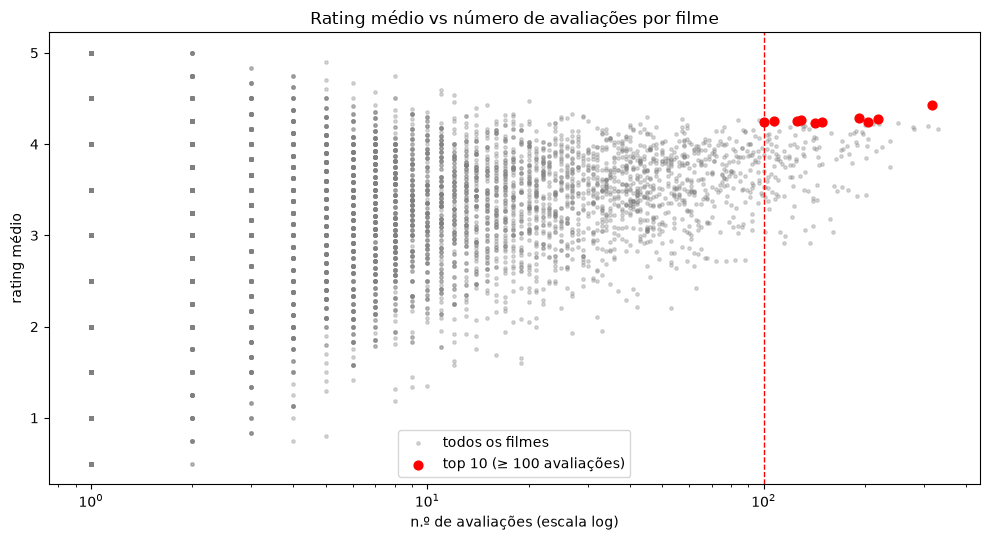

In [50]:
if DETALHE_ATIVO:
    # Média vs n.º de avaliações: os extremos (0.5 e 5.0) vêm quase todos de filmes com poucas avaliações
    plt.figure(figsize=(10, 5.5))
    plt.scatter(naive['num_ratings'], naive['avg_rating'], s=6, alpha=0.3, color='grey', label='todos os filmes')
    top_ids = (naive.filter(pl.col('num_ratings') >= MIN_RATINGS).head(10))
    plt.scatter(top_ids['num_ratings'], top_ids['avg_rating'], s=40, color='red', label=f'top 10 (≥ {MIN_RATINGS} avaliações)')
    plt.axvline(MIN_RATINGS, color='red', ls='--', lw=1)
    plt.xscale('log')
    plt.xlabel('n.º de avaliações (escala log)')
    plt.ylabel('rating médio')
    plt.title('Rating médio vs número de avaliações por filme')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


## 8. Padrões de comportamento e atividade de avaliação potencialmente invulgar

Analisamos como os utilizadores atribuem avaliações ao longo do tempo e se alguns filmes recebem concentrações invulgares de avaliações extremas.

A análise utiliza regras simples e ajustáveis para identificar atividade que merece uma análise mais detalhada. Os sinais identificados descrevem padrões nos dados e não constituem prova de utilização de bots ou de manipulação das avaliações.

Examinamos períodos de atividade intensa dos utilizadores, a atribuição repetida das mesmas classificações e alterações súbitas nas avaliações dos filmes face ao seu histórico anterior.

In [51]:
if DETALHE_ATIVO:
    # Limites ajustáveis: regras exploratórias, sem validação como detetor de bots.
    MIN_USER_RATINGS = 20
    BUSY_HOUR = 50
    SAME_SECOND = 10
    EXTREME_SHARE = 0.80

    activity = ratings.with_columns(
        pl.from_epoch("timestamp", time_unit="s").alias("rated_at")
    ).with_columns(
        pl.col("rated_at").dt.date().alias("day"),
        pl.col("rated_at").dt.truncate("1h").alias("hour"),
    )

    # Máximo de avaliações numa hora de calendário.
    hourly_activity = activity.group_by(["userId", "hour"]).len()
    peak_hours = hourly_activity.group_by("userId").agg(
        pl.col("len").max().alias("max_ratings_hour")
    )

    # Máximo de avaliações com o mesmo timestamp.
    peak_seconds = (
        activity.group_by(["userId", "timestamp"]).len()
        .group_by("userId")
        .agg(pl.col("len").max().alias("max_ratings_second"))
    )

    user_behaviour = (
        activity.group_by("userId")
        .agg(
            pl.len().alias("num_ratings"),
            pl.col("day").n_unique().alias("active_days"),
            pl.col("rated_at").min().alias("first_rating"),
            pl.col("rated_at").max().alias("last_rating"),
            pl.col("rating").mean().alias("avg_rating"),
            pl.col("rating").n_unique().alias("distinct_scores"),
            (pl.col("rating") <= 1.0).mean().alias("low_share"),
            (pl.col("rating") >= 4.5).mean().alias("high_share"),
        )
        .join(peak_hours, on="userId")
        .join(peak_seconds, on="userId")
        .with_columns(
            (pl.col("max_ratings_hour") / pl.col("num_ratings"))
            .alias("peak_hour_share")
        )
        .with_columns(
            # Atividade intensa que representa pelo menos metade do histórico do utilizador.
            (
                (pl.col("max_ratings_hour") >= BUSY_HOUR)
                & (pl.col("peak_hour_share") >= 0.50)
            ).alias("concentrated_burst"),

            (pl.col("max_ratings_second") >= SAME_SECOND)
            .alias("same_second_batch"),

            (
                (pl.col("num_ratings") >= MIN_USER_RATINGS)
                & (pl.col("distinct_scores") == 1)
            ).alias("single_score"),

            (
                (pl.col("num_ratings") >= MIN_USER_RATINGS)
                & (pl.col("low_share") >= EXTREME_SHARE)
            ).alias("mostly_low"),

            (
                (pl.col("num_ratings") >= MIN_USER_RATINGS)
                & (pl.col("high_share") >= EXTREME_SHARE)
            ).alias("mostly_high"),
        )
    )

    flag_columns = [
        "concentrated_burst",
        "same_second_batch",
        "single_score",
        "mostly_low",
        "mostly_high",
    ]

    user_behaviour = (
        user_behaviour
        .with_columns(
            pl.sum_horizontal(
                [pl.col(column).cast(pl.Int32) for column in flag_columns]
            ).alias("num_flags")
        )
        .sort(
            ["num_flags", "max_ratings_hour"],
            descending=[True, True]
        )
    )

    flagged_users = user_behaviour.filter(pl.col("num_flags") > 0)

    print("Utilizadores analisados:", user_behaviour.height)
    print("Utilizadores com pelo menos um sinal:", flagged_users.height)

    display(user_behaviour.select(
        pl.col(column).sum().alias(column) for column in flag_columns
    ))
    display(flagged_users)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Utilizadores analisados: 610
Utilizadores com pelo menos um sinal: 210


concentrated_burst,same_second_batch,single_score,mostly_low,mostly_high
u32,u32,u32,u32,u32
197,13,1,0,9


userId,num_ratings,active_days,first_rating,last_rating,avg_rating,distinct_scores,low_share,high_share,max_ratings_hour,max_ratings_second,peak_hour_share,concentrated_burst,same_second_batch,single_score,mostly_low,mostly_high,num_flags
i64,u32,u32,datetime[μs],datetime[μs],f64,u32,f64,f64,u32,u32,f64,bool,bool,bool,bool,bool,i32
534,520,3,2016-04-04 16:39:55,2017-02-16 20:45:00,3.804808,8,0.0,0.236538,448,128,0.861538,true,true,false,false,false,2
492,121,1,1997-05-18 17:19:05,1997-05-18 17:45:46,3.867769,4,0.0,0.264463,121,10,1.0,true,true,false,false,false,2
500,86,1,2001-11-12 01:08:29,2001-11-12 01:25:55,3.244186,5,0.197674,0.151163,86,10,1.0,true,true,false,false,false,2
168,94,2,2011-05-30 22:08:05,2011-05-31 01:50:46,4.462766,7,0.010638,0.819149,73,1,0.776596,true,false,false,false,true,2
191,85,1,1996-04-17 16:50:09,1996-04-17 17:08:18,3.741176,5,0.152941,0.411765,64,34,0.752941,true,true,false,false,false,2
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
206,25,1,1996-12-16 19:07:47,1996-12-16 19:11:47,4.04,3,0.0,0.36,25,10,1.0,false,true,false,false,false,1
251,23,1,2016-08-08 17:17:30,2016-08-08 17:28:20,4.869565,3,0.0,0.956522,23,1,1.0,false,false,false,false,true,1
163,23,1,1998-05-03 17:45:32,1998-05-03 17:46:10,3.0,3,0.0,0.0,23,10,1.0,false,true,false,false,false,1


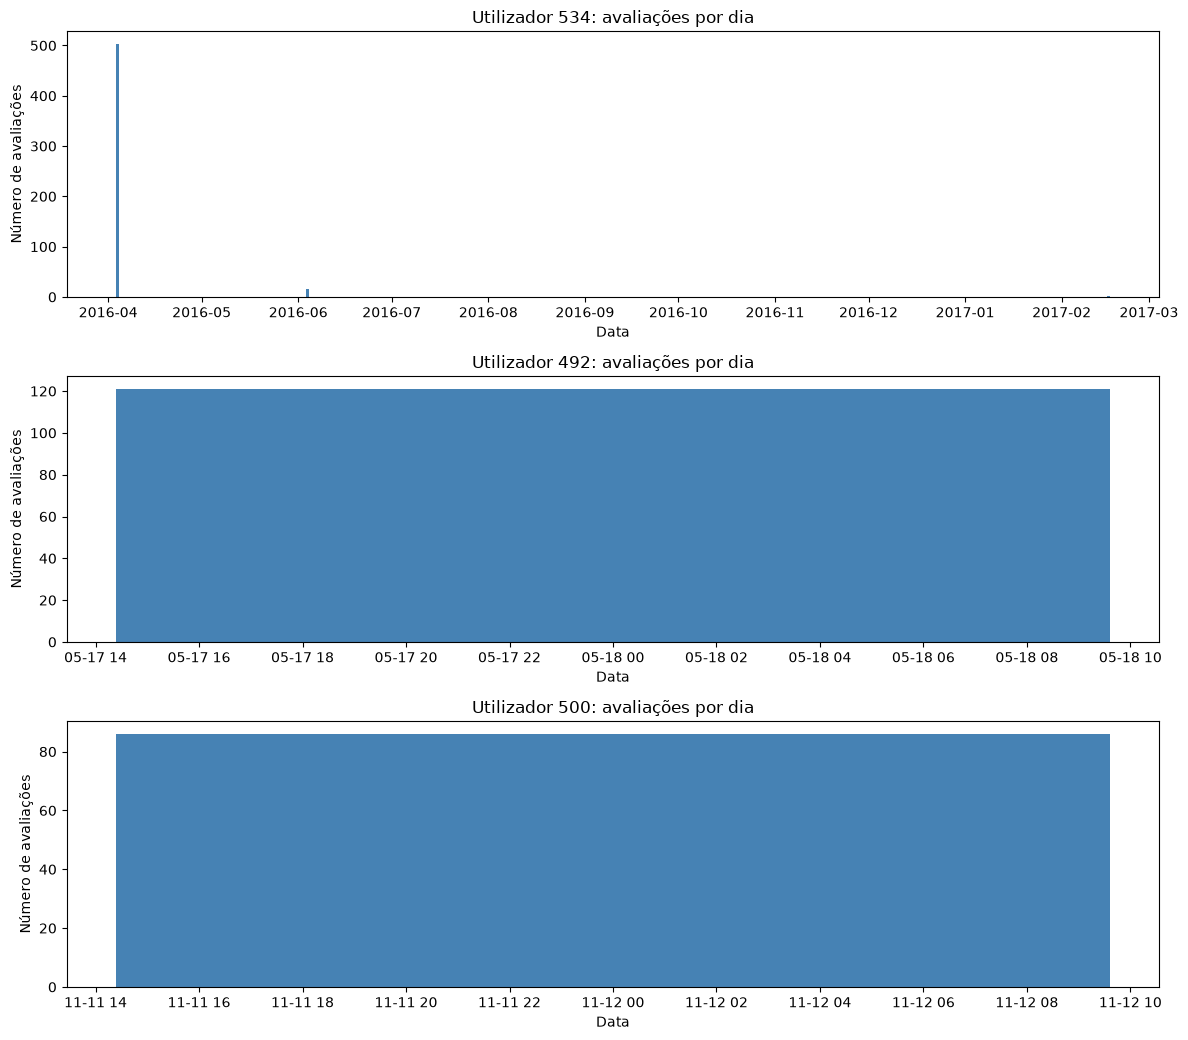

In [52]:
if DETALHE_ATIVO:
    selected_users = flagged_users.head(3)["userId"].to_list()

    if not selected_users:
        print("Nenhum utilizador cumpre os limites atuais.")
    else:
        fig, axes = plt.subplots(
            len(selected_users), 1,
            figsize=(12, 3.5 * len(selected_users)),
            squeeze=False
        )

        for ax, user_id in zip(axes[:, 0], selected_users):
            user_days = (
                activity.filter(pl.col("userId") == user_id)
                .group_by("day")
                .agg(
                    pl.len().alias("num_ratings"),
                    pl.col("rating").mean().alias("avg_rating"),
                )
                .sort("day")
            )

            ax.bar(
                user_days["day"].to_list(),
                user_days["num_ratings"].to_list(),
                color="steelblue"
            )
            ax.set_title(f"Utilizador {user_id}: avaliações por dia")
            ax.set_ylabel("Número de avaliações")
            ax.set_xlabel("Data")

        plt.tight_layout()
        plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


In [53]:
if DETALHE_ATIVO:
    MIN_PREVIOUS_RATINGS = 20
    MIN_EVENT_USERS = 5
    MIN_EXTREME_SHARE = 0.80
    MIN_AVERAGE_CHANGE = 1.0

    movie_days = (
        activity.group_by(["movieId", "day"])
        .agg(
            pl.len().alias("num_ratings"),
            pl.col("userId").n_unique().alias("num_users"),
            pl.col("rating").sum().alias("rating_sum"),
            pl.col("rating").mean().alias("day_avg"),
            (pl.col("rating") <= 1.0).mean().alias("low_share"),
            (pl.col("rating") >= 4.5).mean().alias("high_share"),
        )
        .sort(["movieId", "day"])
        .with_columns(
            (
                pl.col("num_ratings").cum_sum().over("movieId")
                - pl.col("num_ratings")
            ).alias("previous_ratings"),
            (
                pl.col("rating_sum").cum_sum().over("movieId")
                - pl.col("rating_sum")
            ).alias("previous_rating_sum"),
        )
        .with_columns(
            pl.when(pl.col("previous_ratings") > 0)
            .then(
                pl.col("previous_rating_sum") / pl.col("previous_ratings")
            )
            .otherwise(None)
            .alias("previous_avg")
        )
        .with_columns(
            (pl.col("day_avg") - pl.col("previous_avg")).alias("avg_change")
        )
    )

    candidate_events = (
        movie_days
        .filter(
            (pl.col("previous_ratings") >= MIN_PREVIOUS_RATINGS)
            & (pl.col("num_users") >= MIN_EVENT_USERS)
        )
        .with_columns(
            pl.when(
                (pl.col("low_share") >= MIN_EXTREME_SHARE)
                & (pl.col("avg_change") <= -MIN_AVERAGE_CHANGE)
            )
            .then(pl.lit("Concentração de avaliações baixas"))
            .when(
                (pl.col("high_share") >= MIN_EXTREME_SHARE)
                & (pl.col("avg_change") >= MIN_AVERAGE_CHANGE)
            )
            .then(pl.lit("Concentração de avaliações altas"))
            .otherwise(None)
            .alias("event_type")
        )
        .filter(pl.col("event_type").is_not_null())
        .join(movies.select("movieId", "title"), on="movieId")
        .select(
            "movieId", "title", "day", "event_type",
            "num_users", "previous_ratings",
            "previous_avg", "day_avg", "avg_change",
        )
        .sort(["num_users", "day"], descending=[True, False])
    )

    print("Eventos candidatos por filme:", candidate_events.height)
    display(candidate_events)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Eventos candidatos por filme: 0


movieId,title,day,event_type,num_users,previous_ratings,previous_avg,day_avg,avg_change
i64,str,date,str,u32,u32,f64,f64,f64


Test sobre resultados aqui referente ao data set pequeno.

**[Humano!! - preenche aqui texto sobre limitações da deteção de comportamentos invulgares]**

Indique os limites usados, a proporção de utilizadores sinalizados e exemplos que mereçam inspeção. Considere introdução legítima de avaliações em lote, diferenças de escala e falsos positivos. Os sinais não provam automatização ou manipulação.

## 9. Evolução das avaliações dos filmes e possíveis eventos de influência

### 9.1 Objetivo e hipóteses

Analisamos a evolução da classificação e do número de avaliações de cada filme,
procurando identificar:

- Filmes cuja classificação média aumentou ou diminuiu entre dois períodos.
- Concentrações de avaliações muito baixas ou muito altas em períodos curtos.
- A participação de utilizadores anteriormente sinalizados no capítulo 8.

Consideramos as seguintes hipóteses:

**H1 — Mudança de classificação:** alguns filmes apresentam diferenças relevantes
na classificação média entre um período anterior e um período recente.

**H2 — Concentração temporal:** alguns filmes recebem várias avaliações extremas
no mesmo dia, com uma média diferente da observada anteriormente.

**H3 — Participação de utilizadores sinalizados:** alguns desses eventos incluem
utilizadores com padrões de atividade identificados no capítulo 8.

Estas hipóteses são exploratórias. Uma alteração da média pode resultar de mudanças
no público que avalia o filme, do número de avaliações ou da evolução da sua receção.
Os eventos identificados não demonstram, por si só, campanhas de desvalorização
ou de promoção artificial.

O termo «recente» refere-se aos últimos anos disponíveis no dataset.

In [54]:
if DETALHE_ATIVO:
    YEARS_PER_PERIOD = 5
    MIN_RATINGS_PER_PERIOD = 10
    MIN_MEAN_CHANGE = 0.5

    movie_activity = (
        ratings
        .with_columns(
            pl.from_epoch("timestamp", time_unit="s").alias("rated_at")
        )
        .with_columns(
            pl.col("rated_at").dt.year().alias("year"),
            pl.col("rated_at").dt.date().alias("day"),
        )
    )

    last_year = movie_activity["year"].max()
    recent_start = last_year - YEARS_PER_PERIOD + 1
    previous_end = recent_start - 1
    previous_start = previous_end - YEARS_PER_PERIOD + 1

    print(f"Período anterior: {previous_start}–{previous_end}")
    print(f"Período recente: {recent_start}–{last_year}")

    previous_stats = (
        movie_activity
        .filter(pl.col("year").is_between(previous_start, previous_end))
        .group_by("movieId")
        .agg(
            pl.len().alias("previous_count"),
            pl.col("rating").mean().alias("previous_mean"),
        )
    )

    recent_stats = (
        movie_activity
        .filter(pl.col("year").is_between(recent_start, last_year))
        .group_by("movieId")
        .agg(
            pl.len().alias("recent_count"),
            pl.col("rating").mean().alias("recent_mean"),
        )
    )

    # Compara apenas filmes com informação suficiente nos dois períodos.
    movie_changes = (
        previous_stats
        .join(recent_stats, on="movieId", how="inner")
        .filter(
            (pl.col("previous_count") >= MIN_RATINGS_PER_PERIOD)
            & (pl.col("recent_count") >= MIN_RATINGS_PER_PERIOD)
        )
        .with_columns(
            (pl.col("recent_mean") - pl.col("previous_mean")).alias("mean_change"),
            pl.col("previous_mean").rank("min", descending=True).alias("previous_rank"),
            pl.col("recent_mean").rank("min", descending=True).alias("recent_rank"),
        )
        .with_columns(
            (pl.col("previous_rank") - pl.col("recent_rank")).alias("rank_gain")
        )
        .join(movies.select("movieId", "title"), on="movieId")
        .select(
            "movieId", "title",
            "previous_count", "recent_count",
            "previous_mean", "recent_mean", "mean_change",
            "previous_rank", "recent_rank", "rank_gain",
        )
    )

    rising_movies = (
        movie_changes
        .filter(pl.col("mean_change") >= MIN_MEAN_CHANGE)
        .sort(["mean_change", "recent_count"], descending=[True, True])
    )

    falling_movies = (
        movie_changes
        .filter(pl.col("mean_change") <= -MIN_MEAN_CHANGE)
        .sort(["mean_change", "recent_count"], descending=[False, True])
    )

    print("Filmes que cumprem os mínimos nos dois períodos:", movie_changes.height)

    print("Maiores subidas de classificação média:")
    display(rising_movies.head(10))

    print("Maiores descidas de classificação média:")
    display(falling_movies.head(10))
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Período anterior: 2009–2013
Período recente: 2014–2018
Filmes que cumprem os mínimos nos dois períodos: 300
Maiores subidas de classificação média:
Maiores descidas de classificação média:


movieId,title,previous_count,recent_count,previous_mean,recent_mean,mean_change,previous_rank,recent_rank,rank_gain
i64,str,u32,u32,f64,f64,f64,u32,u32,u32
344,"""Ace Ventura: Pet Detective (19…",22,18,2.681818,3.555556,0.873737,297,210,87
1676,"""Starship Troopers (1997)""",10,16,2.95,3.78125,0.83125,290,137,153
41566,"""Chronicles of Narnia: The Lion…",10,26,2.7,3.480769,0.780769,296,237,59
2916,"""Total Recall (1990)""",14,13,3.357143,4.038462,0.681319,258,45,213
53125,"""Pirates of the Caribbean: At W…",11,28,2.954545,3.625,0.670455,288,192,96
586,"""Home Alone (1990)""",15,18,2.966667,3.611111,0.644444,286,196,90
4776,"""Training Day (2001)""",10,14,3.5,4.142857,0.642857,242,30,212
6934,"""Matrix Revolutions, The (2003)""",14,29,2.821429,3.448276,0.626847,295,250,45
19,"""Ace Ventura: When Nature Calls…",12,19,2.5,3.105263,0.605263,300,289,11


movieId,title,previous_count,recent_count,previous_mean,recent_mean,mean_change,previous_rank,recent_rank,rank_gain
i64,str,u32,u32,f64,f64,f64,u32,u32,u32
1380,"""Grease (1978)""",10,12,3.65,2.25,-1.4,216,300,4294967212
8533,"""Notebook, The (2004)""",10,22,4.35,3.136364,-1.213636,16,286,4294967026
1101,"""Top Gun (1986)""",11,10,3.681818,2.65,-1.031818,205,299,4294967202
66934,"""Dr. Horrible's Sing-Along Blog…",11,13,4.363636,3.538462,-0.825175,12,217,4294967091
81591,"""Black Swan (2010)""",15,27,4.133333,3.351852,-0.781481,58,269,4294967085
953,"""It's a Wonderful Life (1946)""",10,12,4.55,3.791667,-0.758333,2,133,4294967165
82459,"""True Grit (2010)""",13,15,4.153846,3.4,-0.753846,50,257,4294967089
76251,"""Kick-Ass (2010)""",21,22,4.02381,3.295455,-0.728355,103,277,4294967122
2005,"""Goonies, The (1985)""",14,14,3.857143,3.214286,-0.642857,165,283,4294967178


### 9.2 Evolução anual da classificação e do volume de avaliações

Representamos a média anual e o número de avaliações dos filmes com maior subida
e maior descida. O volume ajuda a interpretar a estabilidade das médias:
uma média baseada em poucas avaliações pode variar bastante.

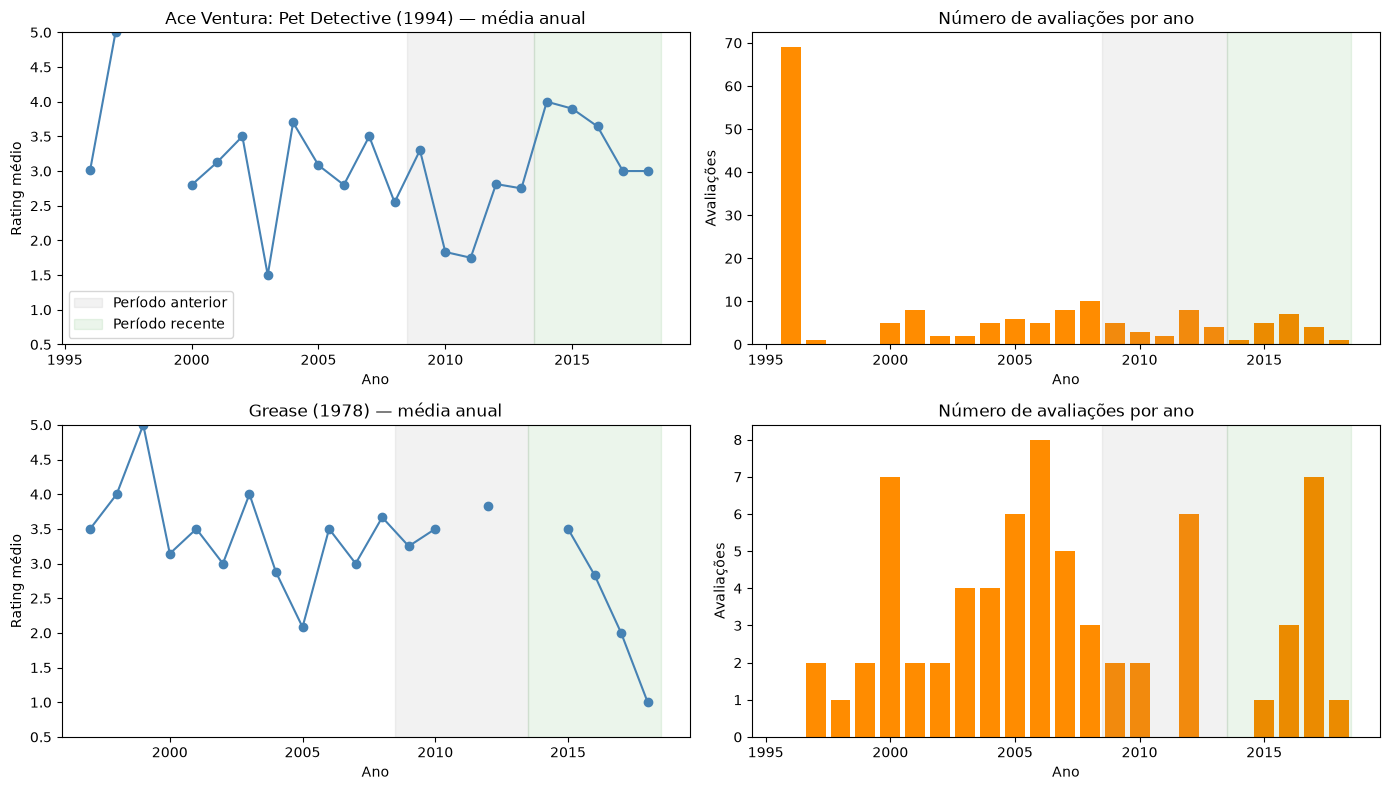

In [55]:
if DETALHE_ATIVO:
    # Seleciona um filme em subida e um em descida, quando existirem.
    selected_movies = pl.concat([
        rising_movies.head(1),
        falling_movies.head(1),
    ]).unique(subset="movieId")

    if selected_movies.is_empty():
        print("Nenhum filme cumpre os critérios atuais de subida ou descida.")
    else:
        annual_movie_stats = (
            movie_activity
            .group_by(["movieId", "year"])
            .agg(
                pl.col("rating").mean().alias("annual_mean"),
                pl.len().alias("num_ratings"),
            )
        )

        fig, axes = plt.subplots(
            selected_movies.height, 2,
            figsize=(14, 4 * selected_movies.height),
            squeeze=False,
        )

        for row, movie in enumerate(selected_movies.iter_rows(named=True)):
            film_data = annual_movie_stats.filter(
                pl.col("movieId") == movie["movieId"]
            )

            # Completa os anos sem ratings: contagem zero e média ausente.
            film_data = (
                pl.DataFrame({
                    "year": list(range(movie_activity["year"].min(), last_year + 1))
                })
                .join(film_data, on="year", how="left")
                .with_columns(pl.col("num_ratings").fill_null(0))
                .sort("year")
            )

            axes[row, 0].plot(
                film_data["year"].to_numpy(),
                film_data["annual_mean"].to_numpy(),
                marker="o",
                color="steelblue",
            )
            axes[row, 0].set(
                title=f"{movie['title']} — média anual",
                xlabel="Ano",
                ylabel="Rating médio",
                ylim=(0.5, 5.0),
            )

            axes[row, 1].bar(
                film_data["year"].to_list(),
                film_data["num_ratings"].to_list(),
                color="darkorange",
            )
            axes[row, 1].set(
                title="Número de avaliações por ano",
                xlabel="Ano",
                ylabel="Avaliações",
            )

            for ax in axes[row]:
                ax.axvspan(
                    previous_start - 0.5, previous_end + 0.5,
                    color="gray", alpha=0.10, label="Período anterior",
                )
                ax.axvspan(
                    recent_start - 0.5, last_year + 0.5,
                    color="green", alpha=0.08, label="Período recente",
                )

        axes[0, 0].legend()
        plt.tight_layout()
        plt.show()
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


### 9.3 Deteção de concentrações de avaliações e cruzamento com utilizadores

Procuramos dias em que um filme recebe várias avaliações predominantemente baixas ou altas, com uma média diferente do seu histórico anterior.

Para cada filme e dia, calculamos o número de avaliações, o número de utilizadores distintos, a média diária e as proporções de avaliações baixas (`≤2`) e altas (`≥4`).

Um evento é sinalizado quando cumpre simultaneamente estas condições:

| Parâmetro | Valor | Condição |
|---|---:|---|
| `MIN_PREVIOUS_RATINGS` | 5 | O filme tinha pelo menos 5 avaliações anteriores ao dia analisado. |
| `MIN_EVENT_USERS` | 5 | Pelo menos 5 utilizadores distintos avaliaram o filme nesse dia. |
| `MIN_EXTREME_SHARE` | 0,51 | Pelo menos 51% das avaliações do dia foram baixas ou pelo menos 51% foram altas. |
| `MIN_EVENT_CHANGE` | 0,5 | A média diária ficou pelo menos 0,5 pontos abaixo ou acima da média histórica, respetivamente. |

As percentagens de avaliações baixas e altas são verificadas separadamente. Com cinco avaliações no dia, são necessárias pelo menos três do mesmo tipo para ultrapassar o limite de 51%.

A média histórica inclui apenas avaliações anteriores ao dia analisado. A diferença calculada compara a média desse dia com a média histórica; não representa a alteração da média global do filme.

Por fim, cruzamos os participantes dos eventos identificados com os utilizadores sinalizados no capítulo 8, apresentando a sua quantidade, percentagem e IDs.

In [56]:
if DETALHE_ATIVO:
    MIN_PREVIOUS_RATINGS = 5 #5
    MIN_EVENT_USERS = 5 # 5
    MIN_EXTREME_SHARE = 0.51 #0.51
    MIN_EVENT_CHANGE = 0.5 # 0.5


    # Estatísticas diárias por filme.
    movie_day_stats = (
        movie_activity
        .group_by(["movieId", "day"])
        .agg(
            pl.len().alias("num_ratings"),
            pl.col("userId").n_unique().alias("num_users"),
            pl.col("rating").sum().alias("rating_sum"),
            pl.col("rating").mean().alias("day_mean"),
            (pl.col("rating") <= 2).mean().alias("low_share"),
            (pl.col("rating") >= 4).mean().alias("high_share"),
        )
        .sort(["movieId", "day"])
        .with_columns(
            (
                pl.col("num_ratings").cum_sum().over("movieId")
                - pl.col("num_ratings")
            ).alias("previous_count"),
            (
                pl.col("rating_sum").cum_sum().over("movieId")
                - pl.col("rating_sum")
            ).alias("previous_sum"),
        )
        .with_columns(
            pl.when(pl.col("previous_count") > 0)
            .then(pl.col("previous_sum") / pl.col("previous_count"))
            .otherwise(None)
            .alias("previous_mean")
        )
        .with_columns(
            (pl.col("day_mean") - pl.col("previous_mean")).alias("mean_change")
        )
    )

    movie_events = (
        movie_day_stats
        .filter(
            (pl.col("previous_count") >= MIN_PREVIOUS_RATINGS)
            & (pl.col("num_users") >= MIN_EVENT_USERS)
        )
        .with_columns(
            pl.when(
                (pl.col("low_share") >= MIN_EXTREME_SHARE)
                & (pl.col("mean_change") <= -MIN_EVENT_CHANGE)
            )
            .then(pl.lit("Concentração de avaliações baixas"))
            .when(
                (pl.col("high_share") >= MIN_EXTREME_SHARE)
                & (pl.col("mean_change") >= MIN_EVENT_CHANGE)
            )
            .then(pl.lit("Concentração de avaliações altas"))
            .otherwise(None)
            .alias("event_type")
        )
        .filter(pl.col("event_type").is_not_null())
    )

    # Recupera os participantes de cada evento.
    # user_behaviour foi criado no capítulo 8.
    event_participants = (
        movie_activity
        .join(
            movie_events.select("movieId", "day", "event_type"),
            on=["movieId", "day"],
            how="inner",
        )
        .join(
            user_behaviour.select("userId", "num_flags"),
            on="userId",
            how="left",
        )
        .with_columns(pl.col("num_flags").fill_null(0))
    )

    # Conta utilizadores únicos, incluindo os sinalizados no capítulo 8.
    event_user_summary = (
        event_participants
        .group_by(["movieId", "day"])
        .agg(
            pl.col("userId").n_unique().alias("participant_users"),
            pl.col("userId")
            .filter(pl.col("num_flags") > 0)
            .n_unique()
            .alias("flagged_users_count"),
            pl.col("userId")
            .filter(pl.col("num_flags") > 0)
            .unique()
            .sort()
            .alias("flagged_user_ids"),
        )
        .with_columns(
            (
                100 * pl.col("flagged_users_count") / pl.col("participant_users")
            ).round(1).alias("flagged_users_pct")
        )
    )

    event_results = (
        movie_events
        .join(event_user_summary, on=["movieId", "day"])
        .join(movies.select("movieId", "title"), on="movieId")
        .select(
            "movieId", "title", "day", "event_type",
            "num_users", "previous_count",
            "previous_mean", "day_mean", "mean_change",
            "flagged_users_count", "flagged_users_pct", "flagged_user_ids",
        )
        .sort(["flagged_users_count", "num_users"], descending=[True, True])
    )

    print("Eventos que cumprem os critérios:", event_results.height)
    display(event_results)
else:
    print('Demonstração detalhada omitida pela configuração; consultar as comparações agregadas.')


Eventos que cumprem os critérios: 0


movieId,title,day,event_type,num_users,previous_count,previous_mean,day_mean,mean_change,flagged_users_count,flagged_users_pct,flagged_user_ids
i64,str,date,str,u32,u32,f64,f64,f64,u32,f64,list[i64]


A análise devolveu **zero eventos**, mesmo após tornar os critérios mais abrangentes. Nenhum par filme/dia cumpriu todas as condições em simultâneo.

Este resultado é obtido antes do cruzamento com o capítulo 8. Assim, não depende de os participantes terem sido anteriormente sinalizados.

Uma possível limitação é a exigência de cinco utilizadores distintos a avaliar o mesmo filme no mesmo dia. Num dataset pequeno e distribuído por vários anos, esta concentração pode ser pouco frequente. Contudo, sem contar os casos que passam cada filtro, não podemos afirmar que este foi o principal motivo para a ausência de resultados.

Os novos limites também introduzem fragilidades: cinco avaliações anteriores fornecem uma referência histórica pouco estável, e uma proporção de 51% representa apenas uma maioria ligeira. Mesmo que surgissem eventos, seria necessário analisá-los individualmente antes de lhes atribuir significado.

Concluímos que **não foram encontrados eventos segundo esta definição**, não que esteja demonstrada a ausência de manipulação. A análise pode não detetar atividade distribuída por vários dias ou pouco representada na amostra.

O próximo passo mais informativo é contar quantos casos passam cada condição, para identificar o filtro mais restritivo antes de alterar novamente os limites.

**Nota de âmbito:** o resultado “zero eventos” acima pertence à execução que originou esse texto. Deve ser confrontado com a tabela atual. A secção comparativa seguinte conta os casos que passam cada condição, sem alterar silenciosamente os critérios do capítulo 9.

<a id="comparacoes"></a>
## Comparação dos datasets completos e cronologia

Esta secção é independente das variáveis da EDA original. Cada consulta usa apenas os Parquet do dataset correspondente. As nove operações comuns são calculadas em SQL e Polars e comparadas antes de guardar os resultados. Reutilizar os agregados evita novas consultas quando apenas se pretendem rever gráficos. A chave de reutilização inclui dados preparados, consultas, código Polars e versões das bibliotecas.

As verificações de pares repetidos contam linhas em excesso por `(userId, movieId)`; não procuram nomes semelhantes. A integridade referencial verifica se as avaliações apontam para filmes existentes. `userId` e `movieId` não devem ser tratados como variáveis quantitativas.

A cobertura temporal é calculada a partir dos timestamps das **avaliações**, em UTC. Não é o ano de estreia extraído do título. Os intervalos fechados mostram a primeira e a última avaliação observadas, não atividade contínua. As contagens anuais e mensais permitem observar lacunas dentro do intervalo.

In [57]:
PERGUNTAS = {
    "generos": "Géneros distintos",
    "filmes_genero": "Filmes por género",
    "utilizadores": "Estatísticas por utilizador",
    "distribuicao": "Avaliações por utilizador e valor",
    "top10": "Melhores médias (mínimo de 100 avaliações)",
    "ponderado": "Top 10 de média ponderada",
    "anual": "Avaliações por ano",
    "valores_ano": "Distribuição de valores por ano",
    "qualidade": "Nulos, domínio e pares repetidos",
}

def consultas_sql():
    return {
        "generos": """SELECT DISTINCT unnest(string_split(genres, '|')) AS genre
                      FROM movies ORDER BY genre""",
        "filmes_genero": """WITH g AS (
            SELECT movieId, unnest(string_split(genres, '|')) AS genre FROM movies)
            SELECT genre, COUNT(*) AS num_movies,
                   COUNT(*) * 100.0 / (SELECT COUNT(*) FROM movies) AS pct_movies
            FROM g GROUP BY genre ORDER BY num_movies DESC, genre""",
        "utilizadores": """SELECT userId, COUNT(*) AS num_ratings, AVG(rating) AS mean,
            STDDEV_SAMP(rating) AS std, MIN(rating) AS min, MEDIAN(rating) AS median,
            MAX(rating) AS max FROM ratings GROUP BY userId ORDER BY userId""",
        "distribuicao": """SELECT userId, rating, COUNT(*) AS num_ratings FROM ratings
            GROUP BY userId, rating ORDER BY userId, rating""",
        "top10": """SELECT r.movieId, m.title, AVG(r.rating) AS avg_rating, COUNT(*) AS num_ratings
            FROM ratings r JOIN movies m USING(movieId) GROUP BY r.movieId, m.title
            HAVING COUNT(*) >= 100 ORDER BY avg_rating DESC, r.movieId LIMIT 10""",
        "ponderado": """WITH s AS (SELECT movieId, AVG(rating) AS R, COUNT(*) AS v
            FROM ratings GROUP BY movieId), p AS (SELECT AVG(rating) AS C FROM ratings)
            SELECT s.movieId, m.title, R AS avg_rating, v AS num_ratings,
                   v/(v+100.0)*R + 100.0/(v+100.0)*C AS weighted
            FROM s CROSS JOIN p JOIN movies m ON s.movieId=m.movieId
            ORDER BY weighted DESC, s.movieId LIMIT 10""",
        "anual": """SELECT year(to_timestamp(timestamp))::BIGINT AS ano,
            COUNT(*) AS num_ratings, AVG(rating) AS media, COUNT(DISTINCT userId) AS utilizadores
            FROM ratings GROUP BY ano ORDER BY ano""",
        "valores_ano": """SELECT year(to_timestamp(timestamp))::BIGINT AS ano,
            rating, COUNT(*) AS num_ratings FROM ratings GROUP BY ano, rating ORDER BY ano, rating""",
        "qualidade": """SELECT COUNT(*) AS linhas,
            COUNT(DISTINCT userId) AS utilizadores, COUNT(DISTINCT movieId) AS filmes,
            COUNT(*)-COUNT(DISTINCT (userId, movieId)) AS pares_repetidos,
            COUNT(*) FILTER (WHERE userId IS NULL OR movieId IS NULL OR rating IS NULL
                                   OR timestamp IS NULL) AS linhas_com_nulos,
            COUNT(*) FILTER (WHERE rating < 0.5 OR rating > 5 OR rating*2 != floor(rating*2))
                AS fora_dominio_comum,
            COUNT(*) FILTER (WHERE rating != floor(rating)) AS nao_inteiros,
            COUNT(*) FILTER (WHERE rating < 1) AS inferior_a_um FROM ratings""",
    }

SQL = consultas_sql()

def consulta_polars(pergunta, pasta):
    r = pl.scan_parquet(Path(pasta) / "ratings.parquet")
    m = pl.scan_parquet(Path(pasta) / "movies.parquet")
    g = m.select("movieId", pl.col("genres").str.split("|").alias("genre")).explode("genre")
    if pergunta == "generos":
        q = g.select("genre").unique().sort("genre")
    elif pergunta == "filmes_genero":
        q = (g.group_by("genre").agg(pl.len().alias("num_movies"))
             .join(m.select(pl.len().alias("total")), how="cross")
             .with_columns((pl.col("num_movies") * 100.0 / pl.col("total")).alias("pct_movies"))
             .select("genre", "num_movies", "pct_movies")
             .sort(["num_movies", "genre"], descending=[True, False]))
    elif pergunta == "utilizadores":
        q = r.group_by("userId").agg(
            pl.len().alias("num_ratings"), pl.col("rating").mean().alias("mean"),
            pl.col("rating").std(ddof=1).alias("std"), pl.col("rating").min().alias("min"),
            pl.col("rating").median().alias("median"), pl.col("rating").max().alias("max")
        ).sort("userId")
    elif pergunta == "distribuicao":
        q = r.group_by("userId", "rating").agg(pl.len().alias("num_ratings")).sort("userId", "rating")
    elif pergunta in ("top10", "ponderado"):
        q = r.group_by("movieId").agg(pl.col("rating").mean().alias("avg_rating"),
                                       pl.len().alias("num_ratings"))
        if pergunta == "top10":
            q = q.filter(pl.col("num_ratings") >= 100)
            ordenar = "avg_rating"
        else:
            q = (q.join(r.select(pl.col("rating").mean().alias("C")), how="cross")
                 .with_columns((pl.col("num_ratings")/(pl.col("num_ratings")+100.0)*pl.col("avg_rating")
                       + 100.0/(pl.col("num_ratings")+100.0)*pl.col("C")).alias("weighted")))
            ordenar = "weighted"
        q = (q.join(m.select("movieId", "title"), on="movieId")
             .sort([ordenar, "movieId"], descending=[True, False]).head(10)
             .select("movieId", "title", "avg_rating", "num_ratings",
                     *(["weighted"] if pergunta == "ponderado" else [])))
    elif pergunta in ("anual", "valores_ano"):
        r = r.with_columns(pl.from_epoch("timestamp", time_unit="s").dt.year().cast(pl.Int64).alias("ano"))
        if pergunta == "anual":
            q = r.group_by("ano").agg(pl.len().alias("num_ratings"),
                pl.col("rating").mean().alias("media"),
                pl.col("userId").n_unique().alias("utilizadores")).sort("ano")
        else:
            q = r.group_by("ano", "rating").agg(pl.len().alias("num_ratings")).sort("ano", "rating")
    elif pergunta == "qualidade":
        q = r.select(pl.len().alias("linhas"), pl.col("userId").n_unique().alias("utilizadores"),
            pl.col("movieId").n_unique().alias("filmes"),
            (pl.len()-pl.struct("userId", "movieId").n_unique()).alias("pares_repetidos"),
            pl.any_horizontal(pl.all().is_null()).sum().alias("linhas_com_nulos"),
            ((pl.col("rating") < 0.5) | (pl.col("rating") > 5)
             | (pl.col("rating")*2 != (pl.col("rating")*2).floor())).sum().alias("fora_dominio_comum"),
            (pl.col("rating") != pl.col("rating").floor()).sum().alias("nao_inteiros"),
            (pl.col("rating") < 1).sum().alias("inferior_a_um"))
    else:
        raise ValueError("Pergunta desconhecida: " + pergunta)
    return q.collect(engine="streaming").to_arrow()

def registar_views(con, dados):
    for tabela in ("ratings", "movies"):
        con.execute(f"CREATE OR REPLACE VIEW {tabela} AS SELECT * FROM "
                    f"read_parquet({sql_ficheiro(Path(dados['pasta']) / (tabela + '.parquet'))})")

def consulta_sql(con, pergunta):
    return con.sql(SQL[pergunta]).to_arrow_table()

def confirmar_igualdade(a, b):
    # Ordenação determinística nas consultas; tolerância só para valores flutuantes.
    assert_frame_equal(pl.from_arrow(a), pl.from_arrow(b), check_dtypes=False,
                       check_exact=False, abs_tol=1e-9, rel_tol=1e-9)

CODIGO_POLARS = hashlib.sha256(marshal.dumps(consulta_polars.__code__)).hexdigest()

In [58]:
def consultas_complementares():
    return {
        "cobertura": """SELECT MIN(timestamp) AS primeiro_timestamp, MAX(timestamp) AS ultimo_timestamp,
            COUNT(*) AS avaliacoes, COUNT(DISTINCT userId) AS utilizadores,
            COUNT(DISTINCT movieId) AS filmes_avaliados, MIN(rating) AS rating_min,
            MAX(rating) AS rating_max FROM ratings""",
        "mensal": """SELECT strftime(to_timestamp(timestamp), '%Y-%m') AS mes,
            COUNT(*) AS num_ratings, AVG(rating) AS media FROM ratings GROUP BY mes ORDER BY mes""",
        "integridade": """SELECT
            (SELECT COUNT(*)-COUNT(DISTINCT movieId) FROM movies) AS ids_filmes_repetidos,
            (SELECT COUNT(*) FROM ratings r ANTI JOIN movies m USING(movieId)) AS filmes_sem_metadados,
            (SELECT COUNT(*) FROM movies WHERE title IS NULL OR genres IS NULL) AS filmes_com_nulos""",
        "perfis_ativos": """WITH y AS (
            SELECT userId, year(to_timestamp(timestamp)) AS ano, COUNT(*) AS n,
                SUM((rating=floor(rating))::BIGINT) AS inteiros,
                SUM((rating!=floor(rating))::BIGINT) AS nao_inteiros FROM ratings GROUP BY userId, ano),
            c AS (SELECT *, SUM(n) OVER w AS total,
                SUM(inteiros) OVER w AS i, SUM(nao_inteiros) OVER w AS ni
                FROM y WINDOW w AS (PARTITION BY userId ORDER BY ano ROWS UNBOUNDED PRECEDING))
            SELECT ano, CASE WHEN ni=0 THEN 'Só inteiros' WHEN i=0 THEN 'Só não inteiros'
                ELSE 'Misto' END AS perfil, COUNT(*) AS utilizadores
            FROM c WHERE total>=2 GROUP BY ano, perfil ORDER BY ano, perfil""",
        "perfis_cumulativos": """WITH limites AS (
            SELECT MIN(year(to_timestamp(timestamp)))::BIGINT AS a,
                   MAX(year(to_timestamp(timestamp)))::BIGINT AS b FROM ratings),
            anos AS (SELECT unnest(range(a,b+1)) AS ano FROM limites),
            y AS (SELECT userId, year(to_timestamp(timestamp)) AS ano,
                SUM((rating=floor(rating))::BIGINT) AS i,
                SUM((rating!=floor(rating))::BIGINT) AS ni FROM ratings GROUP BY userId, ano),
            grelha AS (SELECT u.userId, a.ano, COALESCE(y.i,0) AS i, COALESCE(y.ni,0) AS ni
                FROM (SELECT DISTINCT userId FROM ratings) u CROSS JOIN anos a
                LEFT JOIN y ON u.userId=y.userId AND a.ano=y.ano),
            c AS (SELECT userId, ano, SUM(i) OVER w AS i, SUM(ni) OVER w AS ni FROM grelha
                WINDOW w AS (PARTITION BY userId ORDER BY ano ROWS UNBOUNDED PRECEDING))
            SELECT ano, CASE WHEN ni=0 THEN 'Só inteiros' WHEN i=0 THEN 'Só não inteiros'
                ELSE 'Misto' END AS perfil, COUNT(*) AS utilizadores
            FROM c WHERE i+ni>=2 GROUP BY ano, perfil ORDER BY ano, perfil""",
        "grupos_atividade": """WITH totais AS (SELECT userId, COUNT(*) AS n FROM ratings GROUP BY userId),
            u AS (SELECT r.userId, year(to_timestamp(timestamp)) AS ano,
                AVG(rating) AS media_utilizador, COUNT(*) AS n, ANY_VALUE(t.n) AS total
                FROM ratings r JOIN totais t USING(userId) GROUP BY r.userId, ano),
            g AS (SELECT *, CASE WHEN total<=5 THEN 'Até 5' WHEN total<=20 THEN '6–20'
                WHEN total<=50 THEN '21–50' WHEN total<=100 THEN '51–100'
                ELSE 'Mais de 100' END AS grupo FROM u)
            SELECT ano, grupo, AVG(media_utilizador) AS media,
                COUNT(*) AS utilizadores, SUM(n) AS avaliacoes FROM g GROUP BY ano, grupo ORDER BY ano, grupo""",
    }

COMPLEMENTARES = consultas_complementares()
resultados, estado_analises = {}, []
for nome, dados in datasets_preparados.items():
    pasta_cache = CACHE / nome
    pasta_cache.mkdir(exist_ok=True)
    chave = assinatura([dados["assinatura_dados"], SQL, COMPLEMENTARES, CODIGO_POLARS,
                        duckdb.__version__, pl.__version__, pa.__version__])
    manifesto = pasta_cache / "analises.json"
    nomes_tabelas = list(SQL) + list(COMPLEMENTARES)
    reutilizar = (REUTILIZAR_RESULTADOS and manifesto.exists()
        and json.loads(manifesto.read_text(encoding="utf-8")).get("chave") == chave
        and all((pasta_cache / f"{p}.parquet").exists() for p in nomes_tabelas))
    inicio = time.perf_counter()
    if reutilizar:
        tabelas = {p: pl.read_parquet(pasta_cache / f"{p}.parquet") for p in nomes_tabelas}
    else:
        tabelas = {}
        with ligar() as con:
            registar_views(con, dados)
            for pergunta in SQL:
                a = consulta_sql(con, pergunta)
                b = consulta_polars(pergunta, dados["pasta"])
                confirmar_igualdade(a, b)
                tabelas[pergunta] = pl.from_arrow(a)
            for pergunta, consulta in COMPLEMENTARES.items():
                tabelas[pergunta] = con.sql(consulta).pl()
        for pergunta, tabela in tabelas.items():
            tabela.write_parquet(pasta_cache / f"{pergunta}.parquet")
        manifesto.write_text(json.dumps({"chave": chave,
            "igualdade_sql_polars": list(SQL), "criado_utc": datetime.now(timezone.utc).isoformat()}), encoding="utf-8")
    resultados[nome] = tabelas
    qualidade = tabelas["qualidade"].row(0, named=True)
    integridade = tabelas["integridade"].row(0, named=True)
    assert qualidade["linhas_com_nulos"] == 0, f"{nome}: existem nulos nas avaliações"
    assert qualidade["fora_dominio_comum"] == 0, f"{nome}: rating fora da escala comum"
    if nome in ("ml-100k", "ml-1m"):
        assert qualidade["nao_inteiros"] == 0 and qualidade["inferior_a_um"] == 0, f"{nome}: rating fora da escala inteira 1–5"
    assert integridade["ids_filmes_repetidos"] == 0, f"{nome}: chave movieId repetida"
    assert integridade["filmes_sem_metadados"] == 0, f"{nome}: filme sem metadados"
    estado_analises.append({"dataset": nome, "estado": "agregados reutilizados" if reutilizar else "calculados e comparados",
                           "segundos": time.perf_counter()-inicio,
                           "perguntas_verificadas": len(SQL), "pares_repetidos": qualidade["pares_repetidos"]})
display(pl.DataFrame(estado_analises) if estado_analises else "Sem datasets preparados.")

def juntar_resultado(pergunta):
    partes = [t[pergunta].with_columns(pl.lit(n).alias("dataset")) for n,t in resultados.items()]
    return pl.concat(partes, how="vertical_relaxed") if partes else pl.DataFrame()

cobertura = juntar_resultado("cobertura")
if not cobertura.is_empty():
    cobertura = cobertura.with_columns(
        pl.from_epoch("primeiro_timestamp", time_unit="s").alias("primeira_avaliacao_utc"),
        pl.from_epoch("ultimo_timestamp", time_unit="s").alias("ultima_avaliacao_utc"))
    cobertura.write_csv(OUT_DIR / "cobertura_temporal.csv")
    display(cobertura)
    # Cada intervalo é fechado; uma interseção num só instante tem duração zero.
    pares = []
    for a,b in itertools.combinations(cobertura.iter_rows(named=True), 2):
        inicio = max(a["primeiro_timestamp"], b["primeiro_timestamp"])
        fim = min(a["ultimo_timestamp"], b["ultimo_timestamp"])
        interseta = inicio <= fim
        pares.append({"dataset_a": a["dataset"], "dataset_b": b["dataset"],
            "sobreposicao": interseta,
            "inicio_utc": datetime.fromtimestamp(inicio, timezone.utc).isoformat() if interseta else None,
            "fim_utc": datetime.fromtimestamp(fim, timezone.utc).isoformat() if interseta else None,
            "duracao_dias": (fim-inicio)/86400 if interseta else 0.0})
    if pares:
        sobreposicoes = pl.DataFrame(pares)
        display(sobreposicoes)
        sobreposicoes.write_csv(OUT_DIR / "sobreposicoes_temporais.csv")
    else:
        print("São necessários pelo menos dois datasets calculados para comparar intervalos.")

São necessários pelo menos dois datasets calculados para comparar intervalos.


dataset,estado,segundos,perguntas_verificadas,pares_repetidos
str,str,f64,i64,i64
"""ml-latest-small""","""agregados reutilizados""",0.028775,9,0


primeiro_timestamp,ultimo_timestamp,avaliacoes,utilizadores,filmes_avaliados,rating_min,rating_max,dataset,primeira_avaliacao_utc,ultima_avaliacao_utc
i64,i64,i64,i64,i64,f64,f64,str,datetime[μs],datetime[μs]
828124615,1537799250,100836,610,9724,0.5,5.0,"""ml-latest-small""",1996-03-29 18:36:55,2018-09-24 14:27:30


### Sobreposição histórica e comparabilidade

Uma interseção de intervalos significa apenas que há datas em comum na cobertura observada. Não demonstra repetição das mesmas avaliações, dos mesmos utilizadores ou dos mesmos filmes. Não se faz um *join* de utilizadores entre datasets: a documentação confirma a consistência entre ficheiros da mesma versão, mas isso não confirma equivalência entre versões. Mesmo uma coincidência de ID, nota e timestamp precisa de validação de identidade e proveniência antes de ser interpretada como duplicação.

As amostras têm períodos, escalas e regras de seleção diferentes. No 1M, a disponibilização de informação demográfica faz parte da seleção descrita no documento oficial. As populações não são necessariamente independentes nem representativas de todos os espectadores. Uma diferença entre datasets não pode ser atribuída apenas à sua dimensão.

**[Humano!! - preenche aqui texto sobre diferenças de cobertura temporal]**

Compare as primeiras e últimas avaliações, os anos/meses com mais atividade e os intervalos de sobreposição. Indique que comparações usam períodos comuns e que diferenças podem resultar de cobertura ou amostragem. Com apenas um dataset executado, a sobreposição entre pares fica por avaliar.

### Extensão das análises de comportamento aos datasets selecionados

Reutilizam-se as regras dos capítulos 8 e 9, agora em consultas sobre Parquet: atividade por hora (50 e pelo menos metade do histórico), avaliações no mesmo segundo (10), valor único e proporções extremas (80%, com pelo menos 20 avaliações). No capítulo 8, “baixas” significa ≤1 e “altas” ≥4,5; no capítulo 9, os limites são ≤2 e ≥4. Esta diferença é mantida e não se devem comparar diretamente as duas taxas.

Para os eventos do capítulo 9 exigem-se 5 avaliações anteriores, 5 utilizadores no dia, 51% de avaliações baixas ou altas e variação de pelo menos 0,5 face ao histórico anterior. A tabela de filtros é sequencial: histórico → utilizadores → proporção extrema → diferença de média no mesmo sentido. Os participantes são cruzados com os sinais apenas dentro do mesmo dataset.

Os dois períodos dos filmes são os últimos cinco anos observados e os cinco anteriores, com pelo menos dez avaliações em cada um. “Recente” é relativo ao fim do dataset. Anos parciais ou ausência de dados num período podem deixar esta comparação vazia. As consultas podem usar ficheiros temporários em disco e são controladas por `EXECUTAR_ANALISES_AVANCADAS`.

In [59]:
# Incremente esta versão se alterar os filtros ou as consultas auxiliares abaixo.
VERSAO_ANALISES_AVANCADAS = "2026-11-04.2"
SQL_AVANCADO = {
    "utilizadores_sinalizados": """WITH h AS (
        SELECT userId, timestamp//3600 AS hora, COUNT(*) AS n FROM ratings GROUP BY userId, hora),
        s AS (SELECT userId, timestamp, COUNT(*) AS n FROM ratings GROUP BY userId, timestamp),
        p AS (SELECT userId, MAX(n) AS max_hora FROM h GROUP BY userId),
        q AS (SELECT userId, MAX(n) AS max_segundo FROM s GROUP BY userId),
        u AS (SELECT userId, COUNT(*) AS n, COUNT(DISTINCT rating) AS valores,
            AVG((rating<=1)::INTEGER) AS frac_baixas, AVG((rating>=4.5)::INTEGER) AS frac_altas
            FROM ratings GROUP BY userId),
        f AS (SELECT u.*, p.max_hora, q.max_segundo,
            (max_hora>=50 AND max_hora*1.0/n>=0.5)::INTEGER AS atividade_concentrada,
            (max_segundo>=10)::INTEGER AS mesmo_segundo,
            (n>=20 AND valores=1)::INTEGER AS valor_unico,
            (n>=20 AND frac_baixas>=0.8)::INTEGER AS sobretudo_baixas,
            (n>=20 AND frac_altas>=0.8)::INTEGER AS sobretudo_altas
            FROM u JOIN p USING(userId) JOIN q USING(userId))
        SELECT *, atividade_concentrada+mesmo_segundo+valor_unico+sobretudo_baixas+sobretudo_altas
            AS num_sinais FROM f ORDER BY userId""",
    "dias_filme": """WITH d AS (
        SELECT movieId, timestamp//86400 AS dia, COUNT(*) AS n, COUNT(DISTINCT userId) AS utilizadores,
            SUM(rating) AS soma, AVG(rating) AS media,
            AVG((rating<=2)::INTEGER) AS frac_baixas, AVG((rating>=4)::INTEGER) AS frac_altas
        FROM ratings GROUP BY movieId, dia),
        h AS (SELECT *, SUM(n) OVER w - n AS n_anterior, SUM(soma) OVER w - soma AS soma_anterior
            FROM d WINDOW w AS (PARTITION BY movieId ORDER BY dia ROWS UNBOUNDED PRECEDING)),
        v AS (SELECT *, soma_anterior/NULLIF(n_anterior,0) AS media_anterior FROM h)
        SELECT *, media-media_anterior AS variacao FROM v""",
    "evolucao_filmes": """WITH fim AS (SELECT MAX(year(to_timestamp(timestamp))) AS ano FROM ratings),
        s AS (SELECT movieId,
            COUNT(*) FILTER (WHERE year(to_timestamp(timestamp)) BETWEEN ano-9 AND ano-5) AS n_anterior,
            COUNT(*) FILTER (WHERE year(to_timestamp(timestamp)) BETWEEN ano-4 AND ano) AS n_recente,
            AVG(rating) FILTER (WHERE year(to_timestamp(timestamp)) BETWEEN ano-9 AND ano-5) AS media_anterior,
            AVG(rating) FILTER (WHERE year(to_timestamp(timestamp)) BETWEEN ano-4 AND ano) AS media_recente
            FROM ratings CROSS JOIN fim GROUP BY movieId),
        e AS (SELECT *, media_recente-media_anterior AS variacao,
            RANK() OVER (ORDER BY media_anterior DESC) AS posicao_anterior,
            RANK() OVER (ORDER BY media_recente DESC) AS posicao_recente
            FROM s WHERE n_anterior>=10 AND n_recente>=10)
        SELECT e.*, m.title FROM e JOIN movies m USING(movieId)
        ORDER BY variacao DESC, movieId""",
}

estado_avancadas = []
if EXECUTAR_ANALISES_AVANCADAS:
    for nome, dados in datasets_preparados.items():
        destino = CACHE / nome
        manifesto = destino / "avancadas.json"
        tabelas_guardadas = ["utilizadores_sinalizados", "eventos_filme", "filtros_eventos",
                            "evolucao_filmes", "filmes_ano_selecionados"]
        chave = assinatura([dados["assinatura_dados"], SQL_AVANCADO, duckdb.__version__, VERSAO_ANALISES_AVANCADAS])
        reutilizar = (REUTILIZAR_RESULTADOS and manifesto.exists()
            and json.loads(manifesto.read_text(encoding="utf-8")).get("chave") == chave
            and all((destino / f"{t}.parquet").exists() for t in tabelas_guardadas))
        inicio = time.perf_counter()
        if not reutilizar:
            with ligar() as con:
                registar_views(con, dados)
                for tabela in ("utilizadores_sinalizados", "dias_filme", "evolucao_filmes"):
                    con.execute(f"COPY ({SQL_AVANCADO[tabela]}) TO "
                        f"{sql_ficheiro(destino / (tabela + '.parquet'))} (FORMAT PARQUET, COMPRESSION ZSTD)")
                    con.execute(f"CREATE VIEW {tabela} AS SELECT * FROM "
                        f"read_parquet({sql_ficheiro(destino / (tabela + '.parquet'))})")
                con.execute("""CREATE VIEW eventos AS SELECT *,
                    CASE WHEN frac_baixas>=0.51 AND variacao<=-0.5 THEN 'Avaliações baixas'
                         WHEN frac_altas>=0.51 AND variacao>=0.5 THEN 'Avaliações altas' END AS tipo
                    FROM dias_filme WHERE n_anterior>=5 AND utilizadores>=5""")
                eventos = con.sql("""WITH participantes AS (
                    SELECT r.movieId, r.timestamp//86400 AS dia,
                        COUNT(DISTINCT r.userId) AS participantes,
                        COUNT(DISTINCT r.userId) FILTER (WHERE u.num_sinais>0) AS sinalizados
                    FROM ratings r JOIN eventos e ON r.movieId=e.movieId AND r.timestamp//86400=e.dia
                    LEFT JOIN utilizadores_sinalizados u ON r.userId=u.userId
                    WHERE e.tipo IS NOT NULL GROUP BY r.movieId, r.timestamp//86400)
                    SELECT e.movieId, m.title, e.dia, e.tipo, e.utilizadores, e.n_anterior,
                        e.media_anterior, e.media, e.variacao, p.sinalizados,
                        p.sinalizados*100.0/p.participantes AS pct_sinalizados
                    FROM eventos e JOIN participantes p ON e.movieId=p.movieId AND e.dia=p.dia
                    JOIN movies m ON e.movieId=m.movieId
                    ORDER BY sinalizados DESC, utilizadores DESC, e.movieId, e.dia""").pl()
                eventos.write_parquet(destino / "eventos_filme.parquet")
                filtros = con.sql("""SELECT COUNT(*) AS todos_filme_dia,
                    COUNT(*) FILTER (WHERE n_anterior>=5) AS com_historico,
                    COUNT(*) FILTER (WHERE n_anterior>=5 AND utilizadores>=5) AS com_utilizadores,
                    COUNT(*) FILTER (WHERE n_anterior>=5 AND utilizadores>=5
                        AND (frac_baixas>=0.51 OR frac_altas>=0.51)) AS com_extremos,
                    COUNT(*) FILTER (WHERE n_anterior>=5 AND utilizadores>=5
                        AND ((frac_baixas>=0.51 AND variacao<=-0.5)
                          OR (frac_altas>=0.51 AND variacao>=0.5))) AS eventos
                    FROM dias_filme""").pl()
                filtros.write_parquet(destino / "filtros_eventos.parquet")
                filmes_ano = con.sql("""WITH escolhidos AS (
                    (SELECT movieId FROM evolucao_filmes WHERE variacao>=0.5
                        ORDER BY variacao DESC, movieId LIMIT 1) UNION
                    (SELECT movieId FROM evolucao_filmes WHERE variacao<=-0.5
                        ORDER BY variacao, movieId LIMIT 1))
                    SELECT r.movieId, m.title, year(to_timestamp(timestamp)) AS ano,
                        COUNT(*) AS avaliacoes, AVG(rating) AS media
                    FROM ratings r JOIN escolhidos e ON r.movieId=e.movieId
                    JOIN movies m ON r.movieId=m.movieId GROUP BY r.movieId, m.title, ano
                    ORDER BY r.movieId, ano""").pl()
                filmes_ano.write_parquet(destino / "filmes_ano_selecionados.parquet")
            manifesto.write_text(json.dumps({"chave": chave,
                "criado_utc": datetime.now(timezone.utc).isoformat()}), encoding="utf-8")
        for tabela in tabelas_guardadas:
            resultados[nome][tabela] = pl.read_parquet(destino / f"{tabela}.parquet")
        estado_avancadas.append({"dataset": nome, "estado": "reutilizado" if reutilizar else "calculado",
                                "segundos": time.perf_counter()-inicio})
    display(pl.DataFrame(estado_avancadas) if estado_avancadas else "Sem análises avançadas.")
    if resultados:
        display(juntar_resultado("filtros_eventos"))
        resumo_sinais = []
        for nome, tabelas in resultados.items():
            u = tabelas["utilizadores_sinalizados"]
            resumo_sinais.append({"dataset": nome, "utilizadores": u.height,
                "sinalizados": u.filter(pl.col("num_sinais")>0).height,
                "pct_sinalizados": 100*u.filter(pl.col("num_sinais")>0).height/u.height})
        display(pl.DataFrame(resumo_sinais))
        display(juntar_resultado("eventos_filme").head(30))
else:
    print("Análises avançadas desativadas pela configuração.")

dataset,estado,segundos
str,str,f64
"""ml-latest-small""","""reutilizado""",0.010987


todos_filme_dia,com_historico,com_utilizadores,com_extremos,eventos,dataset
i64,i64,i64,i64,i64,str
99538,70858,0,0,0,"""ml-latest-small"""


dataset,utilizadores,sinalizados,pct_sinalizados
str,i64,i64,f64
"""ml-latest-small""",610,210,34.42623


movieId,title,dia,tipo,utilizadores,n_anterior,media_anterior,media,variacao,sinalizados,pct_sinalizados,dataset
i64,str,i64,str,i64,f64,f64,f64,f64,i64,f64,str


### Exploração interativa de agregados

Usa-se Plotly, a única biblioteca adicional para visualização. A legenda permite mostrar/ocultar datasets; os menus mudam métricas e, quando necessário, o valor de rating, perfil ou grupo de atividade. Zoom e seletores operam sobre tabelas já calculadas e não voltam a executar consultas. Os HTML autónomos em `output/graficos` incluem a biblioteca e podem ser abertos sem Internet ou sessão Python. No VS Code/Jupyter, os gráficos usam a representação interativa do notebook; se o visualizador não a suportar, abra os HTML.

Na evolução anual/mensal, “% do total” divide pelo total de avaliações **desse dataset**, não pelo total de todos os datasets. Na distribuição de notas, o denominador é o total **do ano e dataset**. Nos perfis, é a população elegível segundo a definição escolhida. Nos géneros, um filme pode contar em vários grupos; as percentagens não somam necessariamente 100%. A comparação conserva as grafias originais dos géneros.

Anos/meses interiores sem avaliações têm contagem zero e média ausente; não se desenham observações fora da cobertura de um dataset. Não se atribuem meios pontos às escalas inteiras. Nos grupos de atividade, as médias são primeiro calculadas por utilizador/ano e depois por grupo, dando o mesmo peso a cada utilizador contribuinte.

In [60]:
GRAFICOS = OUT_DIR / "graficos"
GRAFICOS.mkdir(exist_ok=True)
pio.templates.default = "plotly_white"
paleta = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728"]
cores_datasets = {nome: paleta[i % len(paleta)] for i, nome in enumerate(resultados)}

def mostrar(figura, nome):
    figura.update_layout(font=dict(family="Arial", size=13), height=510,
                          margin=dict(t=130, b=65), legend_title_text="Dataset / série")
    # O HTML autónomo funciona sem servidor, kernel ou ligação à Internet.
    figura.write_html(GRAFICOS / f"{nome}.html", include_plotlyjs=True, full_html=True)
    figura.show(renderer="plotly_mimetype")
    print("Versão interativa autónoma:", GRAFICOS / f"{nome}.html")

def grafico_series(tabela, x, metricas, titulo, nome, grupo=None, barras=False):
    if tabela.is_empty():
        print("Sem dados para o gráfico:", titulo)
        return
    conjuntos = []
    for dataset in tabela["dataset"].unique(maintain_order=True).to_list():
        dados = tabela.filter(pl.col("dataset")==dataset)
        grupos = dados[grupo].unique().sort().to_list() if grupo else [None]
        for valor in grupos:
            parte = dados.filter(pl.col(grupo)==valor) if grupo else dados
            if x == "ano":
                anos_dataset = resultados[dataset]["anual"]["ano"]
                grelha = pl.DataFrame({"ano": range(anos_dataset.min(), anos_dataset.max()+1)},
                                     schema={"ano": pl.Int64})
                parte = grelha.join(parte.with_columns(pl.col("ano").cast(pl.Int64)), on="ano", how="left")
                contagens = [c for c in ("num_ratings", "utilizadores", "avaliacoes") if c in parte.columns]
                if contagens:
                    parte = parte.with_columns(pl.col(contagens).fill_null(0))
            conjuntos.append((dataset, valor, parte.sort(x)))
    primeira = next(iter(metricas))
    figura = go.Figure()
    opcoes_grupo = sorted(set(g for _,g,_ in conjuntos)) if grupo else []
    for dataset, valor, parte in conjuntos:
        argumentos = dict(x=parte[x].to_list(), y=parte[primeira].to_list(),
            name=dataset, legendgroup=dataset,
            marker=dict(color=cores_datasets[dataset]),
            visible=(valor==opcoes_grupo[0]) if grupo else True,
            hovertemplate="%{x}<br>%{y:.4g}<extra>%{fullData.name}</extra>")
        figura.add_trace(go.Bar(**argumentos) if barras else go.Scatter(
            **argumentos, mode="lines+markers", line=dict(color=cores_datasets[dataset])))
    menus = [dict(x=0, y=1.23, xanchor="left", buttons=[dict(label=rotulo, method="update",
        args=[{"y": [parte[coluna].to_list() for _,_,parte in conjuntos]},
              {"yaxis.title.text": rotulo}]) for coluna,rotulo in metricas.items()])]
    if grupo:
        menus.append(dict(x=0.55, y=1.23, xanchor="left", buttons=[dict(label=str(valor), method="update",
            args=[{"visible": [g==valor for _,g,_ in conjuntos]}]) for valor in opcoes_grupo]))
    figura.update_layout(title=titulo, xaxis_title="Ano da avaliação (UTC)" if x=="ano" else x,
                          yaxis_title=metricas[primeira], updatemenus=menus, barmode="group")
    mostrar(figura, nome)

if resultados:
    intervalos = go.Figure()
    for linha in cobertura.iter_rows(named=True):
        intervalos.add_trace(go.Scatter(
            x=[linha["primeira_avaliacao_utc"], linha["ultima_avaliacao_utc"]],
            y=[linha["dataset"], linha["dataset"]], mode="lines+markers", name=linha["dataset"],
            line=dict(width=12, color=cores_datasets[linha["dataset"]]),
            hovertemplate="%{x}<extra>%{fullData.name}</extra>"))
    intervalos.update_layout(title="Cobertura dos timestamps das avaliações",
                             xaxis_title="Data da avaliação (UTC)", yaxis_title="Dataset")
    mostrar(intervalos, "intervalos_temporais")

    anuais, mensais, perfis, valores = [], [], [], []
    for nome, tabelas in resultados.items():
        a = tabelas["anual"]
        grelha = pl.DataFrame({"ano": range(a["ano"].min(), a["ano"].max()+1)}, schema={"ano": pl.Int64})
        anual = (grelha.join(a, on="ano", how="left")
            .with_columns(pl.col("num_ratings", "utilizadores").fill_null(0))
            .with_columns((pl.col("num_ratings")*100/pl.col("num_ratings").sum()).alias("pct_dataset"),
                          pl.lit(nome).alias("dataset")))
        anuais.append(anual)
        mensal = tabelas["mensal"].with_columns(
            (pl.col("num_ratings")*100/pl.col("num_ratings").sum()).alias("pct_dataset"),
            pl.lit(nome).alias("dataset"))
        # Os meses ausentes dentro do intervalo recebem contagem zero e média ausente.
        inicio_mes = datetime.strptime(mensal["mes"].min(), "%Y-%m").date()
        fim_mes = datetime.strptime(mensal["mes"].max(), "%Y-%m").date()
        meses = pl.date_range(inicio_mes, fim_mes, interval="1mo", eager=True).dt.strftime("%Y-%m")
        mensal = (pl.DataFrame({"mes": meses}).join(mensal, on="mes", how="left")
                  .with_columns(pl.col("num_ratings", "pct_dataset").fill_null(0), pl.lit(nome).alias("dataset")))
        mensais.append(mensal)
        for tipo, chave in [("Acumulados", "perfis_cumulativos"), ("Ativos no ano", "perfis_ativos")]:
            p = tabelas[chave].with_columns(pl.col("ano").cast(pl.Int64))
            grelha_perfis = grelha.join(pl.DataFrame({"perfil": ["Só inteiros", "Só não inteiros", "Misto"]}), how="cross")
            p = (grelha_perfis.join(p, on=["ano", "perfil"], how="left")
                .with_columns(pl.col("utilizadores").fill_null(0).cast(pl.Int64))
                .sort("perfil", "ano")
                .with_columns((100*pl.col("utilizadores")/pl.col("utilizadores").sum().over("ano")).alias("percentagem"),
                    (pl.col("utilizadores")-pl.col("utilizadores").shift(1).over("perfil").fill_null(0)).alias("variacao_liquida"),
                    (pl.lit(tipo+" | ")+pl.col("perfil")).alias("grupo"), pl.lit(nome).alias("dataset")))
            perfis.append(p)
        v = tabelas["valores_ano"]
        # Só se completam valores da escala documentada de cada dataset.
        escala = [float(i) for i in range(1,6)] if nome in ("ml-100k", "ml-1m") else [i/2 for i in range(1,11)]
        v = (grelha.join(pl.DataFrame({"rating": escala}), how="cross")
            .join(v, on=["ano", "rating"], how="left").with_columns(pl.col("num_ratings").fill_null(0))
            .with_columns((100*pl.col("num_ratings")/pl.col("num_ratings").sum().over("ano")).alias("percentagem"),
                          pl.lit(nome).alias("dataset")))
        valores.append(v)
    anual_conjunto = pl.concat(anuais, how="vertical_relaxed")
    anual_conjunto.write_parquet(OUT_DIR / "anual_conjunto.parquet")
    grafico_series(anual_conjunto, "ano", {"pct_dataset": "% do total de avaliações do dataset",
        "num_ratings": "Número de avaliações", "media": "Média das avaliações",
        "utilizadores": "Utilizadores ativos no ano"}, "Evolução anual por dataset", "evolucao_anual")
    grafico_series(pl.concat(mensais, how="vertical_relaxed"), "mes",
        {"pct_dataset": "% do total de avaliações do dataset", "num_ratings": "Número de avaliações", "media": "Média"},
        "Evolução mensal por dataset", "evolucao_mensal")
    grafico_series(pl.concat(valores, how="vertical_relaxed"), "ano",
        {"percentagem": "% das avaliações do ano", "num_ratings": "Número de avaliações"},
        "Distribuição dos valores de avaliação (selecionar valor)", "valores_por_ano", grupo="rating")
    grafico_series(pl.concat(perfis, how="vertical_relaxed"), "ano",
        {"percentagem": "% de utilizadores elegíveis", "utilizadores": "Utilizadores",
         "variacao_liquida": "Variação líquida anual de utilizadores"},
        "Perfis de utilização da escala (selecionar definição e perfil)", "perfis", grupo="grupo")
    grafico_series(juntar_resultado("grupos_atividade"), "ano",
        {"media": "Média das médias por utilizador", "utilizadores": "Utilizadores do grupo", "avaliacoes": "Avaliações"},
        "Atividade e composição dos utilizadores", "grupos_atividade", grupo="grupo")
    grafico_series(juntar_resultado("filmes_genero"), "genre",
        {"pct_movies": "% de filmes do dataset", "num_movies": "Número de filmes"},
        "Filmes por género: categorias originais", "filmes_genero", barras=True)
    if EXECUTAR_ANALISES_AVANCADAS:
        filmes = juntar_resultado("filmes_ano_selecionados")
        if not filmes.is_empty():
            filmes = filmes.with_columns((pl.col("dataset")+pl.lit(" | ")+pl.col("title")).alias("filme"))
            grafico_series(filmes, "ano", {"media": "Média anual", "avaliacoes": "Número de avaliações"},
                "Evolução de filmes selecionados dentro de cada dataset", "evolucao_filmes", grupo="filme")
else:
    print("Sem dados calculados: não são criados gráficos analíticos.")

Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\intervalos_temporais.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\evolucao_anual.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\evolucao_mensal.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\valores_por_ano.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\perfis.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\grupos_atividade.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\filmes_genero.html
Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\evolucao_filmes.html


<a id="desempenho"></a>
## Desempenho: SQL e Python sobre os mesmos Parquet

As nove perguntas correspondem às operações já exploradas: géneros, filmes por género, resumo por utilizador, distribuição utilizador/nota, melhores médias, média ponderada, evolução anual, distribuição anual de notas e qualidade. A distribuição é medida em formato longo nas duas ferramentas, evitando medir *pivots* diferentes. O top usa sempre o mínimo de 100 avaliações; a média ponderada usa peso 100 e a média global do próprio dataset.

| Medição | Inclui | Não inclui |
|---|---|---|
| Preparação | Rede, extração e conversão, apresentados separadamente | Consultas de análise e gráficos |
| `consulta_e_arrow` | Construção/planeamento, leitura do Parquet, operação, ordenação e materialização do resultado numa tabela Arrow | Download, preparação, validação de igualdade e desenho dos gráficos |
| `arrow_para_objetos_python` | Materialização adicional de uma tabela Arrow já obtida numa lista de objetos Python (`to_pylist`) | Nova consulta ou nova leitura de Parquet |

O tempo principal **inclui a materialização em Arrow**. As APIs não isolam de forma equivalente um “tempo puro do motor”; não se subtraem estas medições para o estimar. A segunda fase mede um custo adicional de consumo do resultado, comum às duas ferramentas, e não uma segunda consulta. Resultados maiores podem demorar mais a materializar mesmo quando a agregação é rápida.

Executam-se aquecimentos e repetições configuráveis, alternando a ordem das ferramentas em cada repetição. As duas leem os mesmos ficheiros com o mesmo limite pedido de *threads*; só DuckDB recebe um limite explícito de memória. A comparação verifica valores, nulos, ordem e empates, com tolerâncias absoluta e relativa de 10⁻⁹ para valores flutuantes. Os inteiros e categorias devem coincidir.

O processo **não controla nem limpa a cache do sistema operativo**, pelo que não se afirma que as execuções são “a frio”. As análises anteriores também podem aquecer a cache. O ambiente, versões, *threads*, aquecimentos, repetições, data e assinatura dos dados são guardados. A reutilização dos benchmarks exige também o mesmo ambiente registado e configuração de medição. Medições de outros ambientes não são misturadas nestes gráficos.

Guardam-se todas as repetições, mediana, IQR (intervalo interquartil), mínimo e máximo. O aviso “conclusão frágil” é uma regra de prudência: mediana inferior a 10 ms ou IQR/mediana superior a 25%; não é um teste estatístico. Nos gráficos, as barras de erro mostram mínimo e máximo; o IQR aparece na tabela e no detalhe ao passar o rato.

In [61]:
def resumir_tempos(amostras):
    valores = sorted(amostras)
    q1, _, q3 = statistics.quantiles(valores, n=4, method="inclusive")
    return statistics.median(valores), q3-q1, min(valores), max(valores)

bench_partes, estado_benchmarks = [], []
for nome, dados in datasets_preparados.items():
    pasta = CACHE / nome
    arquivo = pasta / "benchmarks.parquet"
    manifesto = pasta / "benchmarks.json"
    chave = assinatura([dados["assinatura_dados"], SQL, CODIGO_POLARS,
                        AMBIENTE, REPETICOES, AQUECIMENTOS, "consulta_arrow_e_lista_v1"])
    compativel = (REUTILIZAR_RESULTADOS and arquivo.exists() and manifesto.exists()
        and json.loads(manifesto.read_text(encoding="utf-8")).get("chave") == chave)
    if compativel:
        bench_partes.append(pl.read_parquet(arquivo))
        estado_benchmarks.append({"dataset": nome, "estado": "medições anteriores reutilizadas"})
        continue
    if not EXECUTAR_BENCHMARKS:
        estado_benchmarks.append({"dataset": nome, "estado": "sem medições compatíveis; execução desativada"})
        continue
    linhas = []
    criado = datetime.now(timezone.utc).isoformat()
    with ligar() as con:
        registar_views(con, dados)
        for pergunta in PERGUNTAS:
            funcoes = {"DuckDB SQL": lambda: consulta_sql(con, pergunta),
                       "Python/Polars": lambda: consulta_polars(pergunta, dados["pasta"])}
            # Validação e aquecimento ficam fora das medições.
            a, b = funcoes["DuckDB SQL"](), funcoes["Python/Polars"]()
            confirmar_igualdade(a, b)
            del a, b
            for _ in range(AQUECIMENTOS):
                for executar in funcoes.values():
                    tabela = executar()
                    tabela.to_pylist()
            tempos = {f: {"consulta_e_arrow": [], "arrow_para_objetos_python": []} for f in funcoes}
            for repeticao in range(REPETICOES):
                ordem = list(funcoes) if repeticao%2==0 else list(reversed(funcoes))
                for ferramenta in ordem:
                    inicio = time.perf_counter()
                    tabela = funcoes[ferramenta]()
                    tempos[ferramenta]["consulta_e_arrow"].append(time.perf_counter()-inicio)
                    inicio = time.perf_counter()
                    objetos = tabela.to_pylist()
                    tempos[ferramenta]["arrow_para_objetos_python"].append(time.perf_counter()-inicio)
                    del objetos
            for ferramenta, fases in tempos.items():
                for fase, valores in fases.items():
                    mediana, iqr, minimo, maximo = resumir_tempos(valores)
                    for repeticao, segundos in enumerate(valores, 1):
                        linhas.append({"dataset": nome, "pergunta": pergunta, "ferramenta": ferramenta,
                            "fase": fase, "repeticao": repeticao, "segundos": segundos,
                            "mediana_s": mediana, "iqr_s": iqr, "min_s": minimo, "max_s": maximo,
                            "linhas_resultado": tabela.num_rows, "avaliacoes": dados["linhas_ratings"],
                            "repeticoes": REPETICOES, "aquecimentos": AQUECIMENTOS,
                            "threads": THREADS, "ambiente": assinatura(AMBIENTE),
                            "assinatura_dados": dados["assinatura_dados"], "chave": chave,
                            "criado_utc": criado, "igualdade_verificada": True,
                            "conclusao_fragil": mediana<0.01 or iqr/max(mediana,1e-12)>0.25})
            del tabela
    medições = pl.DataFrame(linhas)
    medições.write_parquet(arquivo)
    manifesto.write_text(json.dumps({"chave": chave, "ambiente": AMBIENTE,
        "criado_utc": criado}, indent=2), encoding="utf-8")
    bench_partes.append(medições)
    estado_benchmarks.append({"dataset": nome, "estado": "medido nesta sessão"})

benchmarks = pl.concat(bench_partes, how="vertical_relaxed") if bench_partes else pl.DataFrame()
display(pl.DataFrame(estado_benchmarks) if estado_benchmarks else "Sem benchmarks.")
if not benchmarks.is_empty():
    benchmarks.write_csv(OUT_DIR / "benchmarks.csv")
    benchmarks.write_parquet(OUT_DIR / "benchmarks.parquet")
    resumo_benchmarks = benchmarks.unique(subset=["dataset", "pergunta", "ferramenta", "fase"])
    display(resumo_benchmarks.select("dataset", "pergunta", "ferramenta", "fase",
        "mediana_s", "iqr_s", "min_s", "max_s", "linhas_resultado", "conclusao_fragil")
        .sort("pergunta", "dataset", "fase", "ferramenta"))
    print("Medições frágeis (mediana < 10 ms ou IQR/mediana > 25%):",
          resumo_benchmarks.filter(pl.col("conclusao_fragil")).height)

Medições frágeis (mediana < 10 ms ou IQR/mediana > 25%): 29


dataset,estado
str,str
"""ml-latest-small""","""medições anteriores reutilizad…"


dataset,pergunta,ferramenta,fase,mediana_s,iqr_s,min_s,max_s,linhas_resultado,conclusao_fragil
str,str,str,str,f64,f64,f64,f64,i64,bool
"""ml-latest-small""","""anual""","""DuckDB SQL""","""arrow_para_objetos_python""",0.000077,0.000005,0.000072,0.000117,23,true
"""ml-latest-small""","""anual""","""Python/Polars""","""arrow_para_objetos_python""",0.000069,0.000002,0.000067,0.000074,23,true
"""ml-latest-small""","""anual""","""DuckDB SQL""","""consulta_e_arrow""",0.026265,0.000854,0.025522,0.026559,23,false
"""ml-latest-small""","""anual""","""Python/Polars""","""consulta_e_arrow""",0.007136,0.000525,0.006802,0.008177,23,true
"""ml-latest-small""","""distribuicao""","""DuckDB SQL""","""arrow_para_objetos_python""",0.001112,0.000021,0.001086,0.001285,3976,true
…,…,…,…,…,…,…,…,…,…
"""ml-latest-small""","""utilizadores""","""Python/Polars""","""consulta_e_arrow""",0.005855,0.00179,0.004986,0.007368,610,true
"""ml-latest-small""","""valores_ano""","""DuckDB SQL""","""arrow_para_objetos_python""",0.000124,0.000019,0.00012,0.000145,195,true
"""ml-latest-small""","""valores_ano""","""Python/Polars""","""arrow_para_objetos_python""",0.000133,0.000009,0.000126,0.000229,195,true


In [62]:
if not benchmarks.is_empty():
    fig_bench = go.Figure()
    tracos = []
    for pergunta in PERGUNTAS:
        for fase in ["consulta_e_arrow", "arrow_para_objetos_python"]:
            for ferramenta in ["DuckDB SQL", "Python/Polars"]:
                parte = (resumo_benchmarks.filter((pl.col("pergunta")==pergunta)
                    & (pl.col("fase")==fase) & (pl.col("ferramenta")==ferramenta))
                    .sort("avaliacoes", "dataset"))
                tracos.append((pergunta, fase, ferramenta, parte))
                fig_bench.add_trace(go.Bar(x=parte["dataset"].to_list(),
                    y=(parte["mediana_s"]*1000).to_list(), name=ferramenta,
                    marker_color="#1f77b4" if ferramenta=="DuckDB SQL" else "#ff7f0e",
                    error_y=dict(type="data", symmetric=False,
                        array=((parte["max_s"]-parte["mediana_s"])*1000).to_list(),
                        arrayminus=((parte["mediana_s"]-parte["min_s"])*1000).to_list()),
                    customdata=parte.select("avaliacoes", "iqr_s", "conclusao_fragil").rows(),
                    hovertemplate="%{x}<br>Mediana: %{y:.3f} ms<br>Avaliações: %{customdata[0]}"
                        "<br>IQR (s): %{customdata[1]}<br>Conclusão frágil: %{customdata[2]}<extra>%{fullData.name}</extra>",
                    visible=pergunta==next(iter(PERGUNTAS)) and fase=="consulta_e_arrow"))
    botoes = []
    for pergunta, rotulo in PERGUNTAS.items():
        for fase in ["consulta_e_arrow", "arrow_para_objetos_python"]:
            botoes.append(dict(label=rotulo+" | "+fase, method="update", args=[
                {"visible": [p==pergunta and f==fase for p,f,_,_ in tracos]},
                {"title.text": rotulo+" — "+fase}]))
    fig_bench.update_layout(title="Comparação de tempos: "+PERGUNTAS[next(iter(PERGUNTAS))],
        xaxis_title="Dataset efetivamente medido (ordem por dimensão)",
        yaxis_title="Mediana (ms); barras de erro = mínimo–máximo", barmode="group",
        updatemenus=[dict(buttons=botoes, x=0, y=1.24, xanchor="left")])
    mostrar(fig_bench, "benchmarks")
else:
    print("Não existem medições compatíveis para representar.")

Versão interativa autónoma: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output\graficos\benchmarks.html


**[Humano!! - preenche aqui texto sobre diferenças de desempenho e possível efeito da cache]**

Compare as medianas e os intervalos, identifique medições muito curtas ou instáveis e indique que a cache não foi controlada. Distinga o tempo da consulta com resultado em Arrow da materialização adicional em objetos Python. Não atribua a diferença à linguagem Python: o Polars executa as operações num motor nativo.

**[Humano!! - preenche aqui texto sobre influência da dimensão do dataset]**

Observe a evolução dos tempos por pergunta e ferramenta nos datasets efetivamente calculados. Compare número de linhas, cardinalidade dos grupos e dimensão dos resultados. Com apenas o dataset pequeno, ainda não existe evidência medida de escalabilidade. Não trate datasets diferentes como simples réplicas com mais linhas.

<a id="limitacoes"></a>
## Limitações e pontos para interpretação

As classificações são ordinais e a média é uma descrição conveniente, sem garantia de intervalos subjetivos iguais entre notas. Diferenças de escala, amostragem, período e composição limitam a comparação. Os IDs não estabelecem identidade entre datasets; datas sobrepostas não estabelecem avaliações repetidas. Um resultado vazio numa regra exploratória não demonstra ausência do fenómeno.

A execução local mede um computador e uma organização concreta dos dados. Não estima automaticamente desempenho em sistemas distribuídos. O enunciado da unidade curricular também prevê progressão para S3/Athena; este notebook melhora a camada local e não afirma que a componente de nuvem foi executada. Não cria recursos nem custos de nuvem.

**[Humano!! - preenche aqui texto sobre limitações da comparação entre datasets]**

Discuta escalas inteiras/meios pontos, períodos comuns, seleção dos utilizadores, diferentes catálogos de filmes e categorias de género. Explique que diferenças de médias ou taxas de sinalização não demonstram uma relação causal com a dimensão. Identifique explicitamente os datasets que ainda não foram executados.

**[Humano!! - preenche aqui texto sobre conclusões sustentadas pelos resultados executados]**

Responda às perguntas iniciais com os resultados observados, a configuração usada e as verificações concluídas. Separe observações de hipóteses, mencione limitações e enumere trabalho académico ainda por realizar. Não compare tempos de datasets sem medições.

<a id="conclusoes"></a>
### Conclusões: preencher após rever a execução

O título original abaixo usa a designação “100K”; indique na interpretação se se refere a `ml-latest-small` ou ao MovieLens 100K oficial. Nenhuma comparação com 32M deve ser concluída sem o executar.

# 10. Conclusões sumárias sobre o dataset 100K e dataset 32M, assim como principais diferenças.

[Texto a preencher com as conclusões sumárias sobre o dataset 100K e dataset 32M]

## Download the results

Files in a Colab session are deleted when it ends. This cell downloads the `parquet/` and `output/`
folders as a zip file.

In [63]:
# A exportação inclui resultados e documentação; os originais não são redistribuídos.
print('Resultados guardados em:', OUT_DIR.resolve())
print('Datasets preparados nesta configuração:', list(datasets_preparados))
print('Datasets omitidos:', omitidos)
if CRIAR_ZIP:
    zip_file = shutil.make_archive(str(RAIZ / 'lab_resultados'), 'zip', OUT_DIR)
    print('ZIP de resultados:', zip_file)
else:
    print('ZIP desativado; ative CRIAR_ZIP na configuração se precisar desta cópia.')

Resultados guardados em: C:\Workstation\EDSA\Big Data Foundations\Projecto\BDF\output
Datasets preparados nesta configuração: ['ml-latest-small']
Datasets omitidos: []
ZIP desativado; ative CRIAR_ZIP na configuração se precisar desta cópia.
